<a href="https://colab.research.google.com/github/jihyeon26/computational-language-technology-hs26/blob/main/stage2/stage2_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tracking Open Models in AI Media · Stage 2: Advanced Embedding Models Training and Analysis
The previous stage cleaned the AI Media Dataset, analysed it with counts, topics and entities, and built a knowledge graph of the open-models track. Stage 2 turns the language of the corpus into vector representations and compares two families of models :
- **Classical representations** : trained from scratch on the corpus: word embeddings (Word2Vec, FastText) and document embeddings (Doc2Vec);
- **Compact open models**, pre-trained language models adapted to the corpus with parameter-efficient fine-tuning.

The goal is to find out which representations best capture the AI media discourse, at what cost, and how well they handle the open-models track. Stage 2 uses the full corpus, but includes analyses focused on the track: model families, developers, openness concepts and related trends.

## Stage 2 requirements and where they are addressed
| Requirement (project brief) | Section |
|---|---|
| Preprocessing for embeddings, training/validation splits | 1.1|
| Training of embeddings with Word2Vec, FastText and Doc2Vec | 1.2 |
| Visualisation of semantic clusters and thematic overlaps| 1.3 |
| Selection of compact open model(s) and parameter-efficient fine-tuning (LoRA/QLoRA) | 2.3 – 2.6 |
| Intrinsic evaluation (semantic similarity, clustering quality, visualisation) | 3.2 – 3.3 |
| Extrinsic task relevant to the track | 2.2, 2.6, 3.4 |
| Comparison of trade-offs: model size, performance, training speed, GPU requirements | 2.4, 3.5 |
| Insight extraction with the best models, focused analysis of the track | 2.8, 3.6 |

## Expected outputs
- Notebook with the model training and fine-tuning steps, clearly annotated
- Visualisations comparing embeddings and model outputs
- A short summary of the model trade-offs and of the insights on the open-models track

## Link with the other stages
- **Input from Stage 1**: the cleaned corpus, the open-models relevance tiers, the WP1 lexicon (normalisation of model names and acronyms), the topics and the extracted entities.
- **Output for Stage 3**: the best-performing representations can be used to retrieve passages in the question-answering (RAG) system. The embeddings alone do not link a model to its developer: unseen model names are placed by their spelling, not by their context (Section 2.8.1), and the word embeddings find the developer of only a third of the model families, failing for the largest companies (*llama → meta*, *gemma → google*, Section 3.2.2). Questions on who develops which model therefore need the knowledge graph of Stage 1 next to the retrieval.

## Contributions
The work was split into three consecutive parts, each building on the previous one.
| Team member | Sections | Contribution |
|---|---|---|
| Jennifer Spieser | 1.1, 1.2, 1.3 | data preparation for embeddings; Word2Vec, FastText and Doc2Vec; visualisation of semantic clusters and thematic overlaps |
| Jihyeon Choung | 2.1 – 2.9 | selection of compact open model(s), LoRA/QLoRA fine-tuning, documentation of the training setup and resources |
| Daliasny Gonzalez Guzman | 3.1 – 3.7 | intrinsic evaluation, extrinsic task, comparison of trade-offs (size, performance, training speed, GPU), insight extraction on the track |

All work packages use the same training / validation split (`artifacts/stage2_wp1/splits.parquet`), so that every model is trained and evaluated on the same articles.

### How to run
[Open in Colab](https://colab.research.google.com/github/jihyeon26/computational-language-technology-hs26/blob/main/stage2/stage2_final.ipynb) · [Repository](https://github.com/jihyeon26/computational-language-technology-hs26)

This notebook combines the three parts of Stage 2, which are also available separately in `stage2/work_packages/`. Run all cells from top to bottom in Colab. Each part clones the repository and mounts Google Drive (`MyDrive/HSLU/CLT`, shared folder of the team), where the inputs and the cached outputs are stored. Part 2 needs a GPU runtime (L4 recommended); its long steps are loaded from the Drive cache when they exist. Parts 1 and 3 run on a CPU.

| Part | Content | Notebook |
|---|---|---|
| 1 | Classical word and sentence embeddings | `stage2_wp1_embeddings.ipynb` |
| 2 | Fine-tuning compact open models (QLoRA) | `stage2_wp2_finetuning.ipynb` |
| 3 | Comparative evaluation and insights | `stage2_wp3_evaluation.ipynb` |

# 1. Classical Word and Sentence Embeddings
The objective of this first part is to build the classical representations :
1. **Data preparation for embeddings** : preprocess the corpus for training and prepare training/validation splits
2. **Classical word and sentence embeddings** : train Word2Vec, FastText and Doc2Vec, and visualise the semantic clusters and thematic overlaps of AI discourse, including the terms of the open-models track.

The data used is the full cleaned corpus as embeddings need a lot of text to be stable. Therefore, the full corpus is used for training and the analyses focus on the terms and articles of the open-model track.

**Cache**: every long step, such as training models, saves its result in `OUT_DIR`(Google Drive). When the notebook is run again, each step first checks whether its file already exists: if it does, the file is loaded; if not, it is created.



## 1.1 Data Preparation for Embeddings
### 1.1.1 Setup and configuration
We load:
- `corpus_clean.parquet`: the cleaned corpus of Stage 1, with the relevance tier of each article for the open-models track (`om_tier`: core, reference, mention, none). The API reference pages (`is_api_reference`) are left out, as in the Stage 1 topic models: they contain code signatures rather than media discourse.
- `open_models_core.parquet`: the 1,210 core articles of the track with their Stage 1 topic
- the WP1 lexicon (`open_models_lexicon.json`): model families, ecosystem tools, openness concepts and normalisation rules


In [ ]:
from pathlib import Path
import os

# Clone the project repository
REPO = Path("/content/computational-language-technology-hs26")
if REPO.exists():
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/jihyeon26/computational-language-technology-hs26.git {REPO}

# Mount Google Drive (input data and outputs)
from google.colab import drive
drive.mount("/content/drive")

# Inputs: Stage 1 outputs
DATA_DIR = Path("/content/drive/MyDrive/HSLU/CLT/data/processed")

# Outputs of this notebook (also used as cache), with a sub-folder for the figures
OUT_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp1")
FIG = OUT_DIR / "figures"
FIG.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [ ]:
# Libraries
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fix the seed
SEED = 42

# Cosine
def unit(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)

# Save figure and show it
def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Stage 1 outputs
corpus = pd.read_parquet(DATA_DIR / "corpus_clean.parquet",
                         columns=["doc_id", "quarter", "text", "om_tier", "is_api_reference"])

# Leave out the API reference pages (code signatures, not media discourse), as in the Stage 1 topic models
corpus = corpus[~corpus["is_api_reference"]].drop(columns="is_api_reference").reset_index(drop=True)
core = pd.read_parquet(DATA_DIR / "open_models_core.parquet", columns=["doc_id", "dominant_topic_label"])
lexicon = json.loads((REPO / "artifacts/stage1_wp1/lexicon/open_models_lexicon.json").read_text(encoding="utf-8"))

print(f"{len(corpus):,} articles | {corpus['text'].str.split().str.len().sum() / 1e6:.1f} M words")
print(corpus["om_tier"].value_counts().to_string())

45,462 articles | 68.3 M words
om_tier
none       41425
mention     2827
core        1210


### 1.1.2 Normalisation

The normalisation reduces the variations in word forms to a common form when the variations mean the same thing. It is important for embeddings, because a vector is learned from the contexts of one token. For instance, if *LLaMa* and *Llama* stay different tokens, their contexts are split over several vectors and none of them is well learned. We therefore reuse the WP1 lexicon of Stage 1, including its normalisation rules, so that both Stage 1 and 2 use the same entities.

In [ ]:
# Matching view of WP1
MATCH_MAP = str.maketrans({"‐": "-", "‑": "-", "‒": "-", "–": "-", "−": "-",
                           "‘": "'", "’": "'", "“": '"', "”": '"', "…": "...",
                           " ": " ", "ﬁ": "fi", "ﬂ": "fl"})

# Normalisation rules of the WP1 lexicon, compiled once
CANON_RULES = []
for fid, f in lexicon["families"].items():            # model families: "LLaMA" -> "llama"
    CANON_RULES.append((re.compile(f["rx"]), fid, f.get("kw", []), False))
for tid, t in lexicon["ecosystem"].items():           # ecosystem tools: "Hugging Face" -> "hugging_face"
    CANON_RULES.append((re.compile(t["rx"]), tid, t.get("kw", []), False))
for cid, c in lexicon["concepts"].items():            # openness concepts: "open weights" -> "open_weight"
    CANON_RULES.append((re.compile(c["rx"]), cid, [k.lower() for k in c.get("kw", [])], True))
for rx, norm in lexicon["phrase_normalisation"]:      # acronyms and phrases: "U.S." -> "united_states"
    CANON_RULES.append((re.compile(rx), norm.strip().replace(" ", "_"), [], False))

def normalise(text):
    text = text.translate(MATCH_MAP)
    lower = text.lower()
    for rx, token, triggers, lower_triggers in CANON_RULES:
        # Speed-up (as in WP1): a pattern only runs if one of its trigger words is in the text
        if triggers and not any(k in (lower if lower_triggers else text) for k in triggers):
            continue
        text = rx.sub(f" {token} ", text)
    return text

### 1.1.3 Sentence and Word Tokenisation
After normalisation, each article is split into sentences, and each sentence into tokens:
- **Sentences**: Word2Vec and FastText learn a word from the words around it, within a sentence. The articles are therefore split into paragraphs, then into sentences (a sentence ends with `.`, `!` or `?`, followed by a capital letter or a digit). Abbreviations such as *U.S.*, which could be mistaken for the end of a sentence, are already replaced by `united_states` during normalisation. Sentences with fewer than 3 tokens (headings, captions, menu items) are dropped.
- **Words**: the text is lower-cased so that *Meta* and *meta* are the same token. A token is a sequence of letters and digits that can contain `_`, `-`, `.` or `'` inside (`gpt-4o`, `llama_cpp`, `don't`), so that model names and canonical tokens stay in one piece; punctuation is dropped. Pure numbers (`2025`, `70`) are dropped because they carry no meaning on their own. The possessive *'s* is removed so that an organisation and its possessive form share one vector.

In addition, stop words are kept, as an embedding learns a word from its context and removing them would change the neighbours of every word; very frequent words are down-sampled during training instead. Similarly, no lemmatisation is applied, so that the word forms keep their information.


In [ ]:
# Sentence boundary
SENT_SPLIT = re.compile(r'(?<=[.!?])["\')\]]?\s+(?=["(\[]?[A-Z0-9])')

# Token - letters / digits
TOKEN_RX = re.compile(r"[a-z0-9]+(?:[_\-.'][a-z0-9]+)*")
MIN_SENT_TOKENS = 3

# Lower case, possessive and pure numbers
def tokenize(sentence):
    sentence = re.sub(r"'s\b", "", sentence.lower())
    return [t for t in TOKEN_RX.findall(sentence) if not t.replace(".", "").isdigit()]

# Split article into tokenised sentences
def doc_sentences(text):
    sentences = []
    for paragraph in text.split("\n"):
        for sentence in SENT_SPLIT.split(paragraph.strip()):
            tokens = tokenize(sentence)
            if len(tokens) >= MIN_SENT_TOKENS:
                sentences.append(tokens)
    return sentences

In [ ]:
# Example of a core article
core_texts = corpus.loc[corpus["om_tier"] == "core", "text"]
example = next(t for t in core_texts if "open-weight" in t or "open weight" in t)
pos = min(i for i in (example.find("open-weight"), example.find("open weight")) if i >= 0)
cut = example.rfind(". ", 0, max(0, pos - 150))
start = cut + 2 if cut >= 0 else 0
passage = example[start:start + 350]


print("ORIGINAL TEXT:\n", passage, "\n")
print("NORMALISED TEXT:\n", normalise(passage), "\n")
print("TOKENISED SENTENCES:")
for s in doc_sentences(normalise(passage)):
    print("  ", s)

ORIGINAL TEXT:
 Fast inference allows for more frequent API calls without bogging down time to output, which is essential for agentic workflows and real-time decision making.

We’re thinking: Models with open weights are now served faster than proprietary models and are nearly as capable. This may spur further adoption of open models as well as prompting strategie 

NORMALISED TEXT:
 Fast inference allows for more frequent API calls without bogging down time to output, which is essential for agentic workflows and real-time decision making.

We're thinking: Models with  open_weight  are now served faster than proprietary models and are nearly as capable. This may spur further adoption of  open_model  as well as prompting strategie 

TOKENISED SENTENCES:
   ['fast', 'inference', 'allows', 'for', 'more', 'frequent', 'api', 'calls', 'without', 'bogging', 'down', 'time', 'to', 'output', 'which', 'is', 'essential', 'for', 'agentic', 'workflows', 'and', 'real-time', 'decision', 'making']
   [

### 1.1.4 Training and validation splits
The split is made by article (all sentences of an article are in the same split) and stratified by relevance tier (core, mention, none) so that both splits contain the same share of open-models articles: 80% of the articles for training and 20% for validation.

The embeddings are trained on the training split only. The split is fixed with a seed and saved (`splits.parquet`), so that all work packages of Stage 2 use the same articles.

The tokenised corpus is saved as text files:
- `sentences_train.txt`: one training sentence per line
- `docs_all.txt`: one article per line, all splits, with `docs_index.parquet` mapping each line to its article

In [ ]:
from sklearn.model_selection import train_test_split

VALIDATION_SHARE = 0.2
SPLITS_PATH = OUT_DIR / "splits.parquet"

# Training/validation split
if SPLITS_PATH.exists():
    splits = pd.read_parquet(SPLITS_PATH)
    print("Split loaded from", SPLITS_PATH.name)
else:
    # stratify by relevance tier
    stratum = corpus["om_tier"].replace({"reference": "mention"}).to_numpy(dtype=object)
    train_ids, val_ids = train_test_split(corpus["doc_id"].to_numpy(dtype=object), test_size=VALIDATION_SHARE,
                                          random_state=SEED, stratify=stratum)
    splits = pd.DataFrame({"doc_id": corpus["doc_id"],
                           "split": np.where(corpus["doc_id"].isin(set(train_ids)), "train", "validation")})
    splits = splits.merge(corpus[["doc_id", "om_tier", "quarter"]], on="doc_id")
    splits.to_parquet(SPLITS_PATH, index=False)
    print("Split created and saved to", SPLITS_PATH.name)

corpus["split"] = corpus["doc_id"].map(dict(zip(splits["doc_id"], splits["split"])))
corpus["track"] = corpus["om_tier"].ne("none")
display(pd.crosstab(corpus["om_tier"], corpus["split"], margins=True))

# Apply normalisation and tokenize
SENT_PATH, DOCS_PATH, INDEX_PATH = OUT_DIR / "sentences_train.txt", OUT_DIR / "docs_all.txt", OUT_DIR / "docs_index.parquet"
docs_index = corpus[["doc_id", "split", "om_tier", "track"]].copy()     # line i of docs_all.txt = row i of corpus
is_train = docs_index["split"].eq("train").to_numpy()

if not (SENT_PATH.exists() and DOCS_PATH.exists() and INDEX_PATH.exists()):
    n_tokens = []
    with open(SENT_PATH, "w", encoding="utf-8") as fs, open(DOCS_PATH, "w", encoding="utf-8") as fd:
        for i, text in enumerate(corpus["text"]):
            sentences = doc_sentences(normalise(text))
            if is_train[i]:
                fs.writelines(" ".join(s) + "\n" for s in sentences)
            fd.write(" ".join(t for s in sentences for t in s) + "\n")
            n_tokens.append(sum(len(s) for s in sentences))
    docs_index["n_tokens"] = n_tokens
    docs_index.to_parquet(INDEX_PATH, index=False)
    print("Tokenised corpus created")
else:
    print("Tokenised corpus loaded")
docs_index = pd.read_parquet(INDEX_PATH)

Split loaded from splits.parquet


split,train,validation,All
om_tier,,,
core,968,242,1210
mention,2262,565,2827
none,33139,8286,41425
All,36369,9093,45462


Tokenised corpus loaded


In [ ]:
# Summary of the tokenised corpus
n_sent = sum(1 for _ in open(SENT_PATH, encoding="utf-8"))
print(f"Articles: {len(docs_index):,} | training sentences: {n_sent:,} | "
      f"average tokens per article: {docs_index['n_tokens'].mean():.0f}")
print("Tokens per split (M):", (docs_index.groupby("split")["n_tokens"].sum() / 1e6).round(1).to_dict())

Articles: 45,462 | training sentences: 2,691,317 | average tokens per article: 1464
Tokens per split (M): {'train': 53.1, 'validation': 13.5}


## 1.2 Classical Word and Sentence Embeddings
### 1.2.1 Word Embeddings: Word2Vec
Word2Vec learns a vector for each word by trying to predict the words around it. Regarding the settings, most values are the default of `gensim` and are not tuned since this is done later in the notebook.


In [ ]:
!pip install -q gensim

In [ ]:
from gensim.models import Word2Vec, FastText

# Settings
EMB = dict(vector_size=100, window=5, min_count=10, sample=1e-4, negative=5, epochs=5, sg=1)

def train_or_load(cls, path, **params):
    if path.exists():
        print(f"{path.name}: loaded")
        return cls.load(str(path))

    model = cls(corpus_file=str(SENT_PATH), seed=SEED, **params)
    model.save(str(path))
    print(f"{path.name}: trained and saved")
    return model

w2v = train_or_load(Word2Vec, OUT_DIR / "word2vec.model", **EMB)
print(f"Vocabulary: {len(w2v.wv):,} words")

word2vec.model: loaded
Vocabulary: 63,043 words


Training a model does not guarantee that the vectors are meaningful. As a quick check, we look at the most similar words to a few known terms of the track, using cosine similarity: if the vectors are meaningful, a model family should be close to other model families. We also look up a few model names that do not exist and therefore never appeared in the training data.

In [ ]:
TRACK_TERMS = ["llama", "deepseek", "qwen", "mistral"]
UNSEEN = ["qwen999-max", "llama-999", "deepseek-r999"]

def neighbours(model, term, k=8):
    if term not in model.wv.key_to_index and not isinstance(model, FastText):
        return "(not in vocabulary: no vector)"
    return ", ".join(f"{w} ({s:.2f})" for w, s in model.wv.most_similar(term, topn=k))

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({"term": TRACK_TERMS + UNSEEN,
                          "Word2Vec neighbours": [neighbours(w2v, t) for t in TRACK_TERMS + UNSEEN]}))

,term,Word2Vec neighbours
0,llama,"qwen (0.85), 8b (0.84), 70b (0.84), mistral (0.83), 7b (0.83), gemma (0.83), 405b (0.83), 3.1-8b (0.82)"
1,deepseek,"r1 (0.91), kimi (0.81), k3 (0.81), r1-0528 (0.80), r1-zero (0.80), o1 (0.79), o3-mini (0.79), v3.2-exp (0.79)"
2,qwen,"32b (0.85), llama (0.85), kimi (0.84), 7b (0.83), gpt_oss (0.82), gemma (0.82), 30b-a3b (0.81), 6-27b (0.80)"
3,mistral,"llama (0.83), sarvam (0.80), 8x7b (0.78), ai21 (0.78), 3.3-70b-instruct (0.77), 7b (0.76), llava (0.75), 32b (0.75)"
4,qwen999-max,(not in vocabulary: no vector)
5,llama-999,(not in vocabulary: no vector)
6,deepseek-r999,(not in vocabulary: no vector)


The nearest neighbours of the model families are mostly other open-model families and parameter sizes (e.g. *llama* → *qwen*, *mistral*, *70b*). The three invented names receive no vector at all: Word2Vec only knows words seen at least 10 times in the training split, so any new or rare model name is out of vocabulary. This limitation motivates the use of FastText.

### 1.2.2 Word Embeddings: FastText
FastText should answer the previous limitation; it is a skip-gram whose word vector is the sum of the vectors of its character n-grams. As a result, words that share pieces of spelling share part of their vector, and a vector can be built for any word, even one never seen in training, from the n-grams it contains.

It uses the same settings as Word2Vec, so that both models can be compared.


In [ ]:
FT_NGRAMS = dict(min_n=3, max_n=5, bucket=500_000)

ft = train_or_load(FastText, OUT_DIR / "fasttext.model", **EMB, **FT_NGRAMS)

fasttext.model: loaded


In [ ]:
# Comparison of Word2Vec and FastText
nn_table = pd.DataFrame({"term": TRACK_TERMS + UNSEEN,
                         "Word2Vec": [neighbours(w2v, t) for t in TRACK_TERMS + UNSEEN],
                         "FastText": [neighbours(ft, t) for t in TRACK_TERMS + UNSEEN]})
with pd.option_context("display.max_colwidth", None):
    display(nn_table)

,term,Word2Vec,FastText
0,llama,"qwen (0.85), 8b (0.84), 70b (0.84), mistral (0.83), 7b (0.83), gemma (0.83), 405b (0.83), 3.1-8b (0.82)","llama2 (0.90), llama3.2 (0.90), llama3 (0.89), qwen (0.86), llamav-o1 (0.85), 8b (0.85), 70b (0.84), gpt_oss (0.83)"
1,deepseek,"r1 (0.91), kimi (0.81), k3 (0.81), r1-0528 (0.80), r1-zero (0.80), o1 (0.79), o3-mini (0.79), v3.2-exp (0.79)","r1 (0.92), deepset (0.85), kimi (0.83), deepswe (0.81), qwen (0.80), open_source_model (0.79), open_weight (0.79), 32b (0.78)"
2,qwen,"32b (0.85), llama (0.85), kimi (0.84), 7b (0.83), gpt_oss (0.82), gemma (0.82), 30b-a3b (0.81), 6-27b (0.80)","gemma (0.88), 32b (0.87), llama (0.86), llama3.2 (0.85), kimi (0.85), k2.5 (0.84), gemma2 (0.84), 7b (0.84)"
3,mistral,"llama (0.83), sarvam (0.80), 8x7b (0.78), ai21 (0.78), 3.3-70b-instruct (0.77), 7b (0.76), llava (0.75), 32b (0.75)","llama (0.80), qwen (0.78), sarvam (0.78), 32b (0.76), open_weight (0.76), open_source_model (0.76), gpt_oss (0.76), 7b (0.75)"
4,qwen999-max,(not in vocabulary: no vector),"7-max (0.93), qwen (0.86), 6-27b-fable-fusion-711-uncensored-heretic-nm-dau-neo-max-mtp (0.84), k2.5 (0.84), bc-max (0.83), kimi (0.83), gpt-5.1-codex-max (0.82), 235b-a22b (0.82)"
5,llama-999,(not in vocabulary: no vector),"llama2 (0.96), llama3 (0.95), llama3.2 (0.95), meta-llama (0.89), llamav-o1 (0.88), llamaparse (0.87), llama (0.87), 3.1-8b (0.86)"
6,deepseek-r999,(not in vocabulary: no vector),"deepseek (0.96), r1 (0.89), deepset (0.88), deepswe (0.83), qwen (0.83), kimi (0.83), k2.5 (0.82), deepsearch (0.82)"


FastText gives a vector to the three invented names, and their neighbours are meaningful: *llama-999* is close to *llama2*, *llama3* and *meta-llama*, and *deepseek-r999* to *deepseek* and *r1*. For known words, FastText also groups the versions of a family (*llama* → *llama2*, *llama3.2*; *gemma* → *gemma2*, *gemma3*), because these tokens share character n-grams.

The drawback is that similar spelling also creates false neighbours: *deepseek* is close to *deepset* and *deepsearch*, *llama-999* to the tool *llamaparse*, and *qwen999-max* to other "-max" models such as *gpt-5.1-codex-max*.

Word2Vec neighbours therefore reflect context only, while FastText neighbours reflect both context and spelling.

### 1.2.3 Sentence embeddings
We use Doc2Vec, which extends Word2Vec from words to text: each text gets its own vector, trained together with the word vectors. It uses the same settings as the word embeddings, except 10 epochs : a text vector is only updated when its text is read, once per pass, so it needs more passes than a frequent word.

The unit is the article. The model is trained on the training articles, and the vectors of the validation articles are inferred with the trained model, since articles not seen during training have no vector in the model. Word2Vec and FastText, in contrast, produce one vector per word, so a new text only requires looking up its words in the trained vocabulary.

In [ ]:
from gensim.models.doc2vec import Doc2Vec

# Settings of Doc2Vec
D2V = dict(vector_size=100, min_count=10, sample=1e-4, negative=5, epochs=10, dm=0)
DOCS_TRAIN_PATH, D2V_PATH, DOCVEC_PATH = OUT_DIR / "docs_train.txt", OUT_DIR / "doc2vec.model", OUT_DIR / "doc_vectors.parquet"
train_lines = np.flatnonzero(is_train)

# Training articles
if not DOCS_TRAIN_PATH.exists():
    with open(DOCS_PATH, encoding="utf-8") as fin, open(DOCS_TRAIN_PATH, "w", encoding="utf-8") as fout:
        fout.writelines(line for i, line in enumerate(fin) if is_train[i])

# Doc2Vec model
if D2V_PATH.exists():
    d2v = Doc2Vec.load(str(D2V_PATH))
    print("doc2vec.model: loaded")
else:
    d2v = Doc2Vec(corpus_file=str(DOCS_TRAIN_PATH), seed=SEED, **D2V)
    d2v.save(str(D2V_PATH))
    print("doc2vec.model: trained and saved")

# One vector per article
if DOCVEC_PATH.exists():
    doc_vectors = pd.read_parquet(DOCVEC_PATH)
    print("doc_vectors.parquet: loaded")
else:
    tag_of = {line: tag for tag, line in enumerate(train_lines)}
    with open(DOCS_PATH, encoding="utf-8") as f:
        vectors = [d2v.dv[tag_of[i]] if is_train[i] else d2v.infer_vector(line.split(), epochs=D2V["epochs"])
                   for i, line in enumerate(f)]
    doc_vectors = docs_index[["doc_id", "split", "om_tier", "track"]].assign(vector=vectors)
    doc_vectors.to_parquet(DOCVEC_PATH, index=False)
    print("doc_vectors.parquet: created and saved")
DOC = np.vstack(doc_vectors["vector"].to_numpy())

doc2vec.model: loaded
doc_vectors.parquet: loaded


In [ ]:
# Example
for sentence in ["Meta released the weights of its new model under a permissive licence.",
                 "The Chinese startup trained its model at a fraction of the cost of American rivals."]:
    tokens = [t for s in doc_sentences(normalise(sentence)) for t in s]
    v = d2v.infer_vector(tokens, epochs=D2V["epochs"])
    best = [train_lines[tag] for tag, _ in d2v.dv.most_similar([v], topn=3)]
    print(f"\n{sentence}")
    for i in best:
        print("   -", corpus.loc[i, "text"][:140].replace("\n", " "))


Meta released the weights of its new model under a permissive licence.
   - OpenAI has finally done it: after months of promises, the ChatGPT hitmaker has released its first open-weight large language models (LLMs) s
   - Chinese e-commerce and web giant Alibaba’s Qwen team has officially launched a new series of open source AI large language multimodal models
   - DeepSeek took the AI monopoly by storm last month, and the industry is still grappling to find an appropriate response to the underdog’s sen

The Chinese startup trained its model at a fraction of the cost of American rivals.
   - Chinese President Xi Jinping called for global cooperation on artificial intelligence, warning against countries placing their own national 
   - Chinese artificial intelligence firm DeepSeek rocked markets this week with claims its new AI model outperforms OpenAI's and cost a fraction
   - A bipartisan House committee on Wednesday recommended placing restrictions on the export of AI models to Chi

Both queries retrieve articles on the same subject. The Meta query returns three open-model releases, with the Meta article only third, so the subject weighs more than the company name. The second query does not name Deepseek but retrieves two DeepSeek articles; the second result only shares the broader theme of China and AI, showing that Doc2Vec captures the general topical rather than a specified claim.

## 1.3 Visualisation
### 1.3.1 Semantic Clusters
Terms of AI discourse, grouped into categories, are projected from 100 dimensions to 2 with t-SNE (cosine distance), which keeps close words close. Words of the same category forming a group show a semantic cluster. As t-SNE keeps local neighbourhoods but not global distance, the distance between the groups on the map is not meaningful.

The terms and their categories come from Stage 1: the open-model families, openness concepts and ecosystem tools of the WP1 lexicon, and the most mentioned entities of each type extracted in WP2 (companies, other AI models, hardware, platforms, architectures, countries). The WP2 entities are used with the node corrections made during the Stage 1 knowledge-graph construction (name variants merged, aliases and type errors corrected, generic entities removed), since the category of a term is its colour on the map. Only names of entities are kept (a name contains a capital letter, a digit or `_`), and only terms that are single tokens of the vocabulary are shown.

### 1.3.2 Semantic Clusters



In [ ]:
import json, re, unicodedata
from IPython.utils.capture import capture_output

# Categories of terms from Stage 1 - WP1 lexicon and WP2 entity
TOP_PER_TYPE = 12
WP2_TYPES = {"AI_MODEL": "other AI model", "COMPANY": "company", "HARDWARE": "hardware", "PLATFORM": "platform",
             "ARCHITECTURE": "architecture", "GPE": "country / region"}

def to_token(name):
    tokens = tokenize(normalise(str(name)))
    return tokens[0] if len(tokens) == 1 and tokens[0] in w2v.wv.key_to_index else None

CATEGORIES = {"open-model family (WP1)": list(lexicon["families"]),
              "openness concept (WP1)": list(lexicon["concepts"]),
              "ecosystem tool (WP1)": list(lexicon["ecosystem"])}

# WP2 entities with the node corrections - (stage1_final.ipynb, Section 5.9.3)
nodes = pd.read_csv(REPO / "artifacts/stage1_wp2/nodes.csv", keep_default_na=False, na_values=[""])
nodes[["first_seen", "last_seen"]] = nodes[["first_seen", "last_seen"]].apply(pd.to_datetime, errors="coerce")
stage1_nb = json.loads((REPO / "stage1/stage1_final.ipynb").read_text(encoding="utf-8"))
with capture_output():                                                      # hide the outputs of the Stage 1 cells
    for marker in ("def name_key(", "ALIAS_MAP = [", "def is_generic("):   # name variants, aliases/types, generic nodes
        code = next("".join(c["source"]) for c in stage1_nb["cells"]
                    if c["cell_type"] == "code" and marker in "".join(c["source"]))
        exec(code)                                                          # creates nodes_corrected
nodes = nodes_corrected[~nodes_corrected["is_generic"]]
# Only names of entities are kept: a name contains a capital letter, a digit or "_" (a WP1 canonical token)
nodes = nodes[nodes["entity"].astype(str).str.contains(r"[A-Z0-9_]")]

# WP2 categories
for entity_type, label in WP2_TYPES.items():
    top = nodes[nodes["entity_type"] == entity_type].sort_values("mentions", ascending=False)
    tokens = [to_token(e) for e in top["entity"]]
    tokens = [t for t in dict.fromkeys(tokens) if t]
    CATEGORIES[f"{label} (WP2)"] = tokens[:TOP_PER_TYPE]

# Terms of each category that have a vector
for cat, words in CATEGORIES.items():
    print(f"{cat:28}", ", ".join(w for w in words if w in w2v.wv.key_to_index)[:120])

open-model family (WP1)      llama, gemma, phi, nemotron, gpt_oss, granite, olmo, dbrx, arctic, smollm, eleuther, hermes, grok_open, mistral, eurollm
openness concept (WP1)       open_weight, open_source_model, open_model, osaid, weights_release, open_source_ai
ecosystem tool (WP1)         hugging_face, ollama, llama_cpp, vllm, gguf, lm_studio, lora
other AI model (WP2)         claude, r1, gpt-4, gpt-4o, gpt, agi, o1, gpt-5, manus, v3, gpt-3, o3
company (WP2)                deepseek, nvidia, openai, google, meta, anthropic, microsoft, alibaba, amazon, apple, ibm, cursor
hardware (WP2)               data_center, vram, tpus, h100, tpu, ram, a100, b200, h200, pcs, h100s, nvl72
platform (WP2)               gemini, github, chatgpt, azure, python, aws, android, bigquery, openclaw, openrouter, langchain, kubernetes
architecture (WP2)           mixture_of_experts, sft, chain_of_thought, ppo, rope, e2b, mamba, e4b, deltanet, a2a, mamba-2, qk-norm
country / region (WP2)       united_states, chin

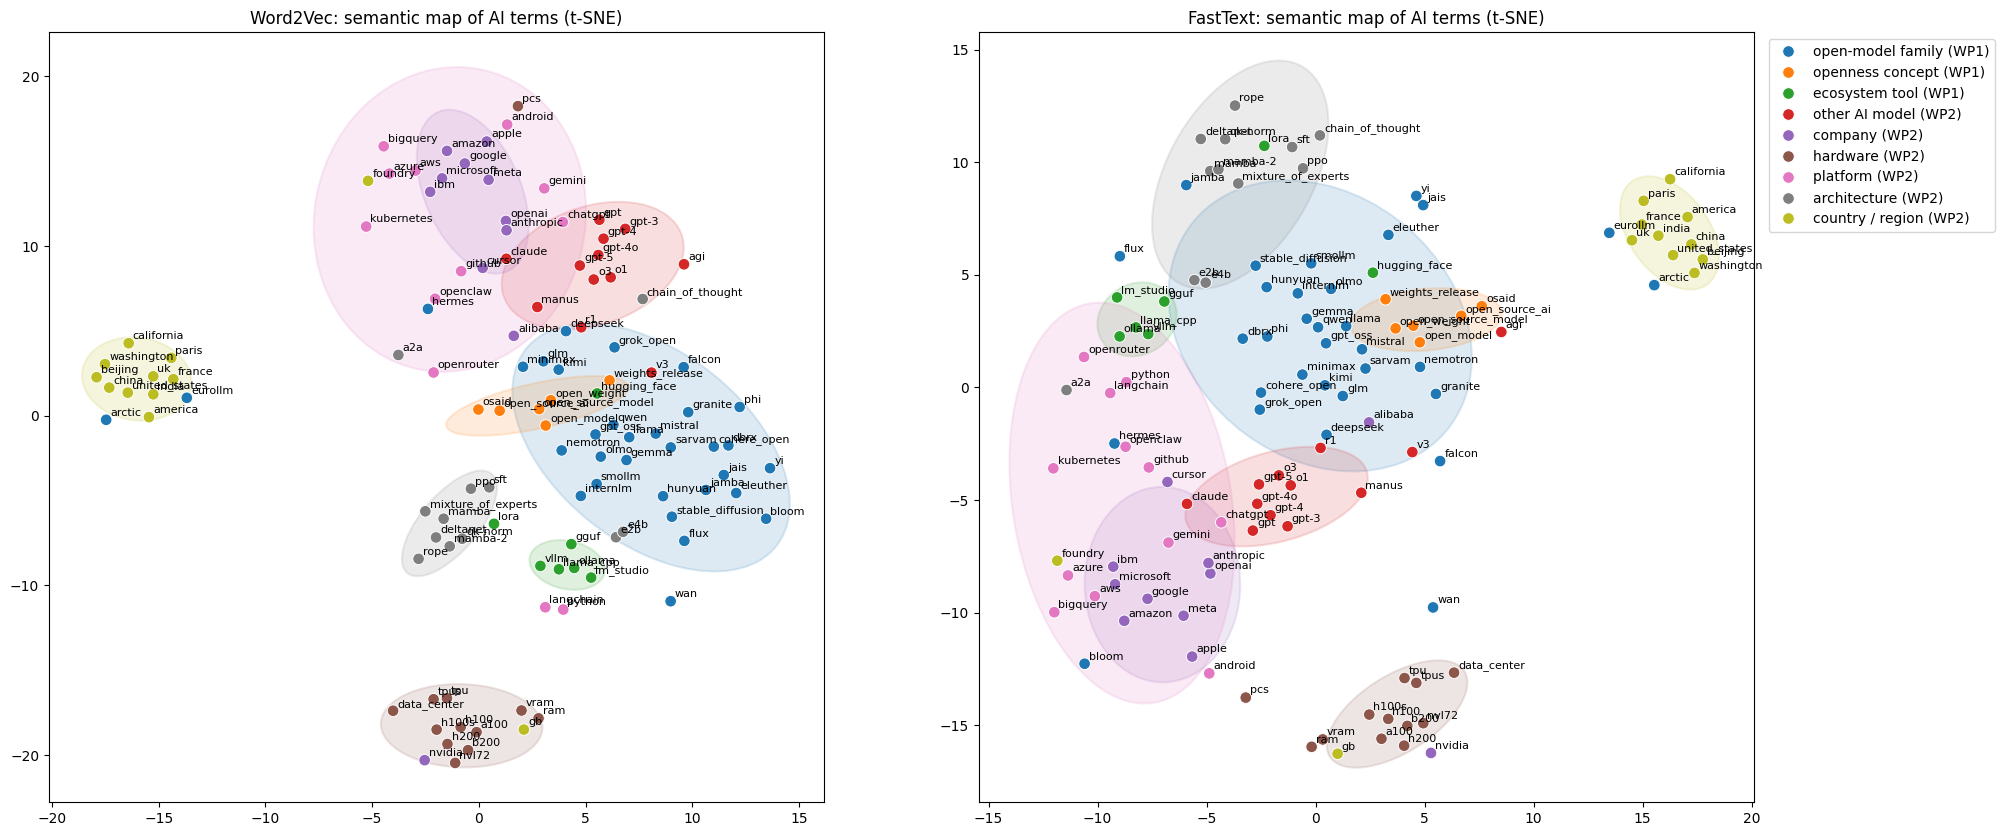

In [ ]:
from sklearn.manifold import TSNE
from matplotlib.patches import Ellipse

# One row per term
rows, seen = [], set()
for cat, words in CATEGORIES.items():
    for w in words:
        if w in w2v.wv.key_to_index and w not in seen:
            rows.append((w, cat))
            seen.add(w)
terms = pd.DataFrame(rows, columns=["term", "category"])
palette = dict(zip(CATEGORIES, sns.color_palette("tab10", len(CATEGORIES))))

def draw_ellipse(ax, pts, color, n_std=2.0):
    dist = np.linalg.norm(pts - np.median(pts, axis=0), axis=1)
    pts = pts[dist <= 2.5 * np.median(dist)]
    if len(pts) < 3:
        return
    vals, vecs = np.linalg.eigh(np.cov(pts.T))
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    ax.add_patch(Ellipse(pts.mean(axis=0), 2 * n_std * np.sqrt(vals[1]), 2 * n_std * np.sqrt(vals[0]), angle=angle,
                         facecolor=color, edgecolor=color, alpha=0.15, lw=1.5))

# Same terms, two models: Word2Vec and FastText
fig, axes = plt.subplots(1, 2, figsize=(22, 10))
for ax, (name, model) in zip(axes, [("Word2Vec", w2v), ("FastText", ft)]):
    # t-SNE
    xy = TSNE(n_components=2, perplexity=min(15, len(terms) - 1), metric="cosine", init="pca",
              random_state=SEED).fit_transform(unit(model.wv[terms["term"].tolist()]))
    terms[f"x_{name.lower()}"], terms[f"y_{name.lower()}"] = xy[:, 0], xy[:, 1]

    # Zone of each category, then one point per term with its label
    for cat in CATEGORIES:
        mask = (terms["category"] == cat).to_numpy()
        if mask.any():
            draw_ellipse(ax, xy[mask], palette[cat])
    sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=terms["category"], palette=palette, s=70, ax=ax,
                    legend=(name == "FastText"))
    for term, x, y in zip(terms["term"], xy[:, 0], xy[:, 1]):
        ax.annotate(term, (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.set(title=f"{name}: semantic map of AI terms (t-SNE)", xlabel="", ylabel="")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
terms.to_csv(OUT_DIR / "terms_tsne.csv", index=False)
save_fig(fig, "terms_tsne")

Both models give similar maps:
- **country / region** and **hardware** form separate zones;
- **company** and **platform** overlap strongly, while **other AI model** overlaps them less strongly, indicating that companies appear with their platforms;
- **ecosystem tool** overlaps **platform**;
- **openness concept** overlaps **open-model family**.

However, the models differ for **architecture** and **ecosystem tool**. In Word2Vec, **architecture** forms a separate zone, while in FastText it overlaps **open-model family**; **ecosystem tool** also overlaps slightly **open-model family** in FastText only.

In addition, in both models, terms of **open-model family** that are also common words are pulled towards their other meaning (*arctic* near **country / region** in Word2Vec), since classical embeddings give one vector per word, which mixes all its senses.

### 1.3.3 Thematic overlaps
Each article is a point, projected with t-SNE:
1. **Open-models discourse within AI discourse**: all track articles and a random sample of the other articles, coloured by relevance tier
2. **Themes of the track**: the 1,210 core articles coloured by their Stage 1 topic

All open-models articles (core, reference, mention) are shown, together with a random sample of 4,000 articles without open-model terms (fixed seed). The sample keeps the map readable, since these articles are the large majority of the corpus and would hide the track articles, and it keeps the t-SNE computation short. As a consequence, the map does not show the real proportions of the corpus.

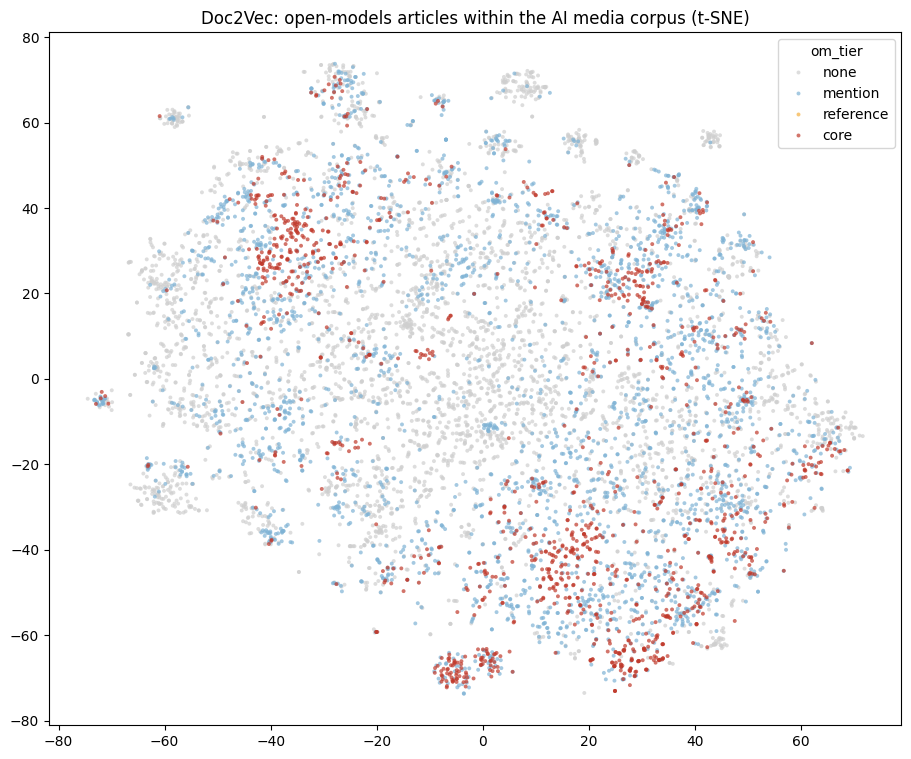

In [ ]:
rng = np.random.default_rng(SEED)
track_idx = np.flatnonzero(doc_vectors["track"].to_numpy())
none_idx = np.flatnonzero(~doc_vectors["track"].to_numpy())
sample_idx = np.concatenate([track_idx, rng.choice(none_idx, size=min(len(none_idx), 4000), replace=False)])

# t-SNE
xy = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca", random_state=SEED).fit_transform(unit(DOC[sample_idx]))
plot_df = doc_vectors.iloc[sample_idx][["om_tier"]].assign(x=xy[:, 0], y=xy[:, 1])
plot_df["om_tier"] = pd.Categorical(plot_df["om_tier"], ["none", "mention", "reference", "core"])
plot_df = plot_df.sort_values("om_tier")   # core articles drawn last (on top)

fig, ax = plt.subplots(figsize=(11, 9))
sns.scatterplot(data=plot_df, x="x", y="y", hue="om_tier", s=8, linewidth=0, alpha=0.7, ax=ax,
                palette={"none": "#cfcfcf", "mention": "#7fb3d5", "reference": "#f5b041", "core": "#c0392b"})
ax.set(title="Doc2Vec: open-models articles within the AI media corpus (t-SNE)", xlabel="", ylabel="")
save_fig(fig, "docs_tsne_tiers")

The tiers are largely mixed: *none*, *mention* and *core* articles appear over most of the map, so Doc2Vec does not separate well the open-models articles from the rest of the corpus.

- **core articles** are spread mainly over the right half, with a few denser concentrations (top left, bottom centre-right and one small tight group at the bottom)
- **mention articles** lie mostly in the outer part of the map, around the centre
- **none articles** appear everywhere and dominate the centre of the map
- **reference tier** contains very few articles and is hardly visible

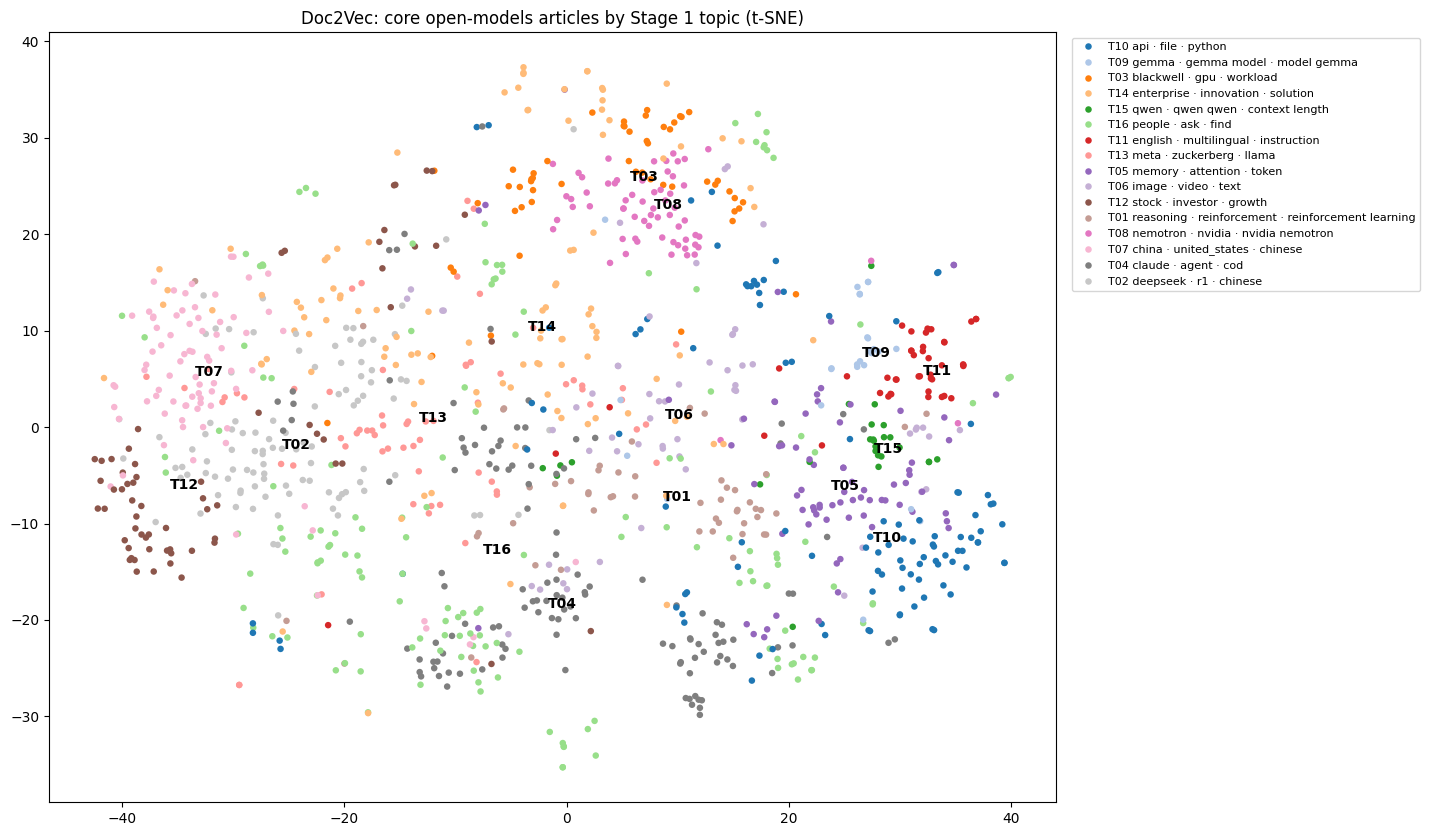

In [ ]:
# Core articles of the track, coloured by their Stage 1 topic
core_vec = doc_vectors.merge(core, on="doc_id")
xy = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca",
          random_state=SEED).fit_transform(unit(np.vstack(core_vec["vector"].to_numpy())))
core_vec["x"], core_vec["y"] = xy[:, 0], xy[:, 1]

fig, ax = plt.subplots(figsize=(13, 10))
sns.scatterplot(data=core_vec, x="x", y="y", hue="dominant_topic_label", s=22, linewidth=0, ax=ax, palette="tab20")
for topic, g in core_vec.groupby("dominant_topic_label"):          # topic number at the centre of its points
    ax.annotate(topic.split(" ")[0], (g["x"].median(), g["y"].median()), fontsize=10, weight="bold")
ax.set(title="Doc2Vec: core open-models articles by Stage 1 topic (t-SNE)", xlabel="", ylabel="")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
save_fig(fig, "core_docs_tsne_topics")



Doc2Vec was trained without the Stage 1 topics, yet several topics form their own zones, while the others are spread over the map:
- **T12** (*stock · investor · growth*) is isolated on the left edge of the map;
- **T03** (*blackwell · gpu · workload*) and **T08** (*nemotron · nvidia · nvidia nemotron*) lie close to each other at the bottom right, distinct from the other topics
- **T09** (*gemma · gemma model · model gemma*), **T11** (*english · multilingual · instruction*) and **T15** (*qwen · qwen qwen · context length*) also lie close to each other
- **T05** (*memory · attention · token*) and **T10** (*api · file · python*) lie close to each other

The other topics are spread over the map; for example, **T14** (*enterprise · innovation · solution*) and **T16** (*people · ask · find*) appear almost everywhere. For these topics, the label placed at the centre of their points does not mark a dense zone.

# 2. Fine-Tuning Compact Open Models
Part 1 built classical representations trained from scratch on the corpus (Word2Vec, FastText, Doc2Vec). It also showed their limits on the open-models track: Word2Vec has no vector for unseen model names, FastText groups names by spelling rather than meaning, and Doc2Vec does not separate the open-models articles well from the rest of the corpus.

This part asks whether **pre-trained compact open models, adapted with parameter-efficient fine-tuning (QLoRA)**, represent the open-models articles better than the classical embeddings, and at what cost in model size, training time and GPU memory:
1. **Task definition**: a theme classification of the open-models articles
2. **Model selection**: compact open models that fit on a Colab GPU
3. **Baselines**: Doc2Vec (Part 1) and the frozen pre-trained model, each with a linear classifier
4. **QLoRA fine-tuning**: training setup, resource tracking and evaluation on the shared validation split
5. **Track analysis**: unseen model names and theme trends; article vectors, predictions and resource logs are saved for the comparative evaluation (Part 3)

Only small low-rank adapters (LoRA) and the classification head are trained; the weights of the pre-trained model stay frozen and are loaded in 4-bit (QLoRA). This is **not full fine-tuning**: the share of trainable parameters is reported for every model.

**Key results** (shared validation split):
1. **Fine-tuning helps**: QLoRA reaches a macro-F1 of 0.80 (Qwen3-1.7B) and 0.84 (Qwen3-4B), 5 to 9 points above Doc2Vec and the frozen models (Sections 2.6.2 – 2.6.3). A TF-IDF baseline, tested in Part 3, comes close (0.80, Section 3.4).
2. **The smaller model is enough**: Qwen3-4B is not significantly better than Qwen3-1.7B, which trains 2.3× faster with 1.7× less GPU memory (Sections 2.3, 2.9).
3. **The first 512 tokens are enough**: reading the whole article does not improve the fine-tuned models (Section 2.6.4).
4. **Unseen model names are placed by their spelling**, not by their context (Section 2.8.1).
5. **Track trend**: among the articles that mention open models, the share about developer tools grows from about a quarter to about a half (Section 2.8.2).

**Labels**: the themes were first taken from the Stage 1 topics (**topic labels**). A hand check found only 64% of them correct, so all articles were labelled again with a written rubric (**reviewed labels**, Sections 2.2.2 – 2.2.3). Unless stated otherwise, the models are trained and evaluated on the reviewed labels; the first run on the topic labels is kept as a comparison (Section 2.6.5).

**Cache**: every long step saves its result on Google Drive and loads it when the notebook is run again.

| Team member | Sections | Contribution |
|---|---|---|
| Jihyeon Choung | 2.1 – 2.8 | selection and QLoRA fine-tuning of compact open models, training setup and resource documentation |

## 2.1 Setup
A GPU runtime is required. Start with the main model only (`MODELS`) for a first full run.

Inputs:
- `corpus_clean.parquet` and `open_models_core.parquet`: the cleaned corpus and the 1,210 core articles with their Stage 1 topic
- `artifacts/stage2_wp1/splits.parquet`: the training / validation split shared by all Stage 2 work packages
- `doc_vectors.parquet` (Part 1, Google Drive): the Doc2Vec vector of every article, used as the classical baseline

In [ ]:
!pip install -q -U transformers peft bitsandbytes accelerate datasets gensim

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
from pathlib import Path

# Clone the project repository
REPO = Path("/content/computational-language-technology-hs26")
if REPO.exists():
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/jihyeon26/computational-language-technology-hs26.git {REPO}

# Mount Google Drive (input data and outputs)
from google.colab import drive
drive.mount("/content/drive")

# Inputs: Stage 1 outputs and Part 1 (WP1) outputs
DATA_DIR = Path("/content/drive/MyDrive/HSLU/CLT/data/processed")
WP1_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp1")

# Labels used for training: "checked" (reviewed labels, Section 2.2.3) or "silver" (topic labels, first run)
TRAIN_LABELS = "checked"
LABELS_FILE = REPO / "artifacts/stage2_wp2/labels_checked.csv"

# Outputs of this notebook (also used as cache). The outputs that do not depend on the labels (frozen-model embeddings,
# Doc2Vec) are shared in OUT_DIR; the outputs that do (adapters, predictions, results) go to RUN_DIR, one per label version
OUT_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp2")
RUN_DIR = OUT_DIR if TRAIN_LABELS == "silver" else OUT_DIR / TRAIN_LABELS
FIG = RUN_DIR / "figures"
ADAPTERS = RUN_DIR / "adapters"
for d in (FIG, ADAPTERS):
    d.mkdir(parents=True, exist_ok=True)

# Trainer checkpoints stay on the local disk (only the final adapter is copied to Drive)
CKPT_DIR = Path("/content/wp2_runs")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Libraries
import gc, json, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Fix the seed (same as Part 1)
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Cosine
def unit(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)

# Save figure and show it
def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Release GPU memory between models
def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
# Native bf16 needs an Ampere GPU or newer (L4, A100); is_bf16_supported() is also True on a T4, where bf16 is emulated and slow
BF16 = torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 8
print(f"GPU: {GPU} | bf16: {BF16}")

GPU: NVIDIA L4 | bf16: True


In [ ]:
# Stage 1 outputs (API reference pages left out, as in Part 1)
corpus = pd.read_parquet(DATA_DIR / "corpus_clean.parquet",
                         columns=["doc_id", "quarter", "text", "om_tier", "is_api_reference"])
corpus = corpus[~corpus["is_api_reference"]].drop(columns="is_api_reference").reset_index(drop=True)
core = pd.read_parquet(DATA_DIR / "open_models_core.parquet", columns=["doc_id", "title", "dominant_topic_label"])

# Shared split of Part 1
splits = pd.read_parquet(REPO / "artifacts/stage2_wp1/splits.parquet")
corpus["split"] = corpus["doc_id"].map(dict(zip(splits["doc_id"], splits["split"])))
print(f"{len(corpus):,} articles")
display(pd.crosstab(corpus["om_tier"], corpus["split"], margins=True))

45,462 articles


split,train,validation,All
om_tier,,,
core,968,242,1210
mention,2262,565,2827
none,33139,8286,41425
All,36369,9093,45462


## 2.2 Task Definition: Theme Classification of Open-Models Articles
The extrinsic task must be relevant to the open-models track and must have labels for training and evaluation. The relevance tier (`om_tier`) is not used as a label: it was defined by the keywords of the WP1 lexicon, so a classifier would only learn to find these keywords again.

Instead, the 1,210 core articles are classified into **5 themes** of the open-models discourse. The themes group the 16 Stage 1 topics: several topics are small (T09 and T15: 26 articles each) and some are close in meaning (T02 DeepSeek and T07 China–US). **T16** (*people · ask · find*) is left out: it had the weakest coherence of the Stage 1 topics (NPMI 0.10) and gathers general writing without a clear theme. An article belongs to the theme of its **main subject**, not to every theme it mentions:

| Theme | Main subject | Stage 1 topics |
|---|---|---|
| `model_families` | a specific model or model family of any vendor: release, versions, benchmarks, capabilities, licence | T08 Nemotron · T09 Gemma · T11 multilingual / instruction · T13 Meta / Llama · T15 Qwen |
| `china_geopolitics` | China–US competition, export controls, AI policy and regulation, national AI race | T02 DeepSeek / R1 · T07 China / United States |
| `research_techniques` | methods: training, architecture and efficiency, multimodal techniques, safety research | T01 reasoning / RL · T05 memory / attention · T06 image / video |
| `developer_tools` | using models: agents, coding tools, APIs, platforms, tutorials, deployment | T04 Claude / agents / coding · T10 API / Python |
| `business_compute` | hardware and infrastructure, investment, enterprise adoption, markets | T03 Blackwell / GPU · T12 stock / investors · T14 enterprise / innovation |

The labels are built in two steps: the Stage 1 topic of an article gives a first label (**topic label**, this section); after a hand check (Section 2.2.2), all articles are labelled again with the rubric above (**reviewed label**, Section 2.2.3).

In [ ]:
# Stage 1 topic -> theme
THEMES = {
    "model_families":      ["T08", "T09", "T11", "T13", "T15"],
    "china_geopolitics":   ["T02", "T07"],
    "research_techniques": ["T01", "T05", "T06"],
    "developer_tools":     ["T04", "T10"],
    "business_compute":    ["T03", "T12", "T14"],
}
TOPIC_TO_THEME = {t: theme for theme, topics in THEMES.items() for t in topics}
LABELS = list(THEMES)
LABEL_ID = {label: i for i, label in enumerate(LABELS)}

task = core.merge(corpus[["doc_id", "quarter", "text", "split"]], on="doc_id")
task["topic"] = task["dominant_topic_label"].str[:3]
task["theme"] = task["topic"].map(TOPIC_TO_THEME)
print(f"Left out (T16): {task['theme'].isna().sum()} articles")
task = task.dropna(subset=["theme"]).reset_index(drop=True)

Left out (T16): 150 articles


### 2.2.1 Training, development and validation sets
The shared split of Part 1 is kept, so that the classical and the fine-tuned models are evaluated on the same articles:
- **validation** (Part 1): held-out evaluation set for every model of Stage 2. It is never used for training or model selection. The Doc2Vec vectors of these articles were also inferred, not trained, in Part 1.
- **train** (Part 1): split again into **train** (90%) and **dev** (10%, stratified by topic label). The dev set is used for model selection during fine-tuning (best epoch).

The sets are fixed here and are the same for both label versions.

In [ ]:
fit_ids, dev_ids = train_test_split(task.loc[task["split"] == "train", "doc_id"], test_size=0.1, random_state=SEED,
                                    stratify=task.loc[task["split"] == "train", "theme"])
task["set"] = np.select([task["doc_id"].isin(set(fit_ids)), task["doc_id"].isin(set(dev_ids))],
                        ["train", "dev"], "validation")

display(pd.crosstab(task["theme"], task["set"], margins=True)[["train", "dev", "validation", "All"]])

set,train,dev,validation,All
theme,,,,
business_compute,172,19,40,231
china_geopolitics,134,15,35,184
developer_tools,167,18,47,232
model_families,159,18,50,227
research_techniques,131,15,40,186
All,763,85,212,1060


### 2.2.2 Topic labels: hand check
The topic label is the theme of the dominant Stage 1 topic of an article. It is cheap, but a topic model is not an annotator: an article can mix several themes, and its dominant topic can be wrong. A stratified sample of validation articles (20 per theme) was therefore checked by hand with the rubric of Section 2.2, reading the title and the first 600 characters: `label_ok` says whether the topic label is correct and, if not, `correct_theme` gives the correct theme (`none` if no theme fits). If two themes weighed the same and the topic label was one of them, it counted as correct.

Only **64%** of the topic labels are correct. Many errors are model releases outside the five families of the Stage 1 topics (e.g. MiniMax, Kimi, Phi), which the topic model placed in other themes. These labels are too noisy to train and evaluate the models, so all articles were labelled again (Section 2.2.3).

In [ ]:
CHECK_PATH = OUT_DIR / "label_check_validation.csv"
if not CHECK_PATH.exists():
    sample = task[task["set"] == "validation"].groupby("theme", group_keys=False).sample(n=20, random_state=SEED)
    sample = sample.assign(text=sample["text"].str[:600], label_ok="", correct_theme="")
    sample[["doc_id", "title", "theme", "text", "label_ok", "correct_theme"]].to_csv(CHECK_PATH, index=False)
    print("Sample written to", CHECK_PATH.name, "- fill in label_ok / correct_theme, then re-run this cell")
    check = pd.DataFrame()
else:
    check = pd.read_csv(CHECK_PATH)
    check = check[check["label_ok"].notna()]
    ok = check["label_ok"].astype(str).str.lower().isin(["1", "1.0", "true", "yes", "y"])
    check["checked_theme"] = check["theme"].where(ok, check["correct_theme"])
    print(f"Checked: {len(check)} | topic label correct: {ok.mean():.1%}\n")
    display(pd.crosstab(check["theme"], check["checked_theme"], margins=True)
              .rename_axis(index="topic label", columns="hand check"))

Checked: 100 | topic label correct: 64.0%



hand check,business_compute,china_geopolitics,developer_tools,model_families,none,research_techniques,All
topic label,,,,,,,
business_compute,14,1,2,1,1,1,20
china_geopolitics,1,17,0,1,1,0,20
developer_tools,0,0,12,6,0,2,20
model_families,4,0,4,11,0,1,20
research_techniques,3,0,3,4,0,10,20
All,22,18,21,23,2,14,100


### 2.2.3 Reviewed labels
All 1,060 articles were labelled again with the rubric of Section 2.2 (`artifacts/stage2_wp2/labels_checked.csv`, rubric in `annotation_rubric.md`). The sets of Section 2.2.1 are not changed.

| set | how the label was made (`label_source`) | articles |
|---|---|---|
| train, dev | `ai`: an LLM (Claude Opus 5.5) with the rubric, reading the title and the first 6,000 characters, without seeing the topic label | 848 |
| validation | `human`: the hand check of Section 2.2.2 | 100 |
| validation | `human_after_ai`: LLM label checked by hand, for every article where the LLM disagreed with the topic label or was not highly confident | 68 |
| validation | `ai_agrees_silver_high`: LLM label and topic label agree, with high LLM confidence | 44 |

The agreement of the LLM with the hand check (below) shows how far the LLM training labels can be trusted. Articles labelled `none` stay in the data but are left out of training and evaluation (label −1). In the code, the topic labels are called `silver` and the reviewed labels `checked`; `TRAIN_LABELS` (Section 2.1) selects the labels used for training.

In [ ]:
from sklearn.metrics import cohen_kappa_score

task["silver_theme"] = task["theme"]
if LABELS_FILE.exists():
    checked_labels = pd.read_csv(LABELS_FILE)
    task = task.merge(checked_labels[["doc_id", "checked_theme", "label_source", "ai_theme"]], on="doc_id", how="left")
    hand = task[task["label_source"] == "human"]
    print(f"LLM vs hand check ({len(hand)} articles): agreement {(hand['ai_theme'] == hand['checked_theme']).mean():.1%}, "
          f"kappa {cohen_kappa_score(hand['checked_theme'], hand['ai_theme']):.2f} | "
          f"topic labels vs hand check: agreement {(hand['silver_theme'] == hand['checked_theme']).mean():.1%}, "
          f"kappa {cohen_kappa_score(hand['checked_theme'], hand['silver_theme']):.2f}")
    print(f"Topic label = reviewed label: {(task['silver_theme'] == task['checked_theme']).mean():.1%} of all articles\n")
    display(pd.crosstab(task["label_source"], task["set"], margins=True))
    display(pd.crosstab(task["silver_theme"], task["checked_theme"], margins=True)
              .rename_axis(index="topic label", columns="reviewed label"))
else:
    print("No reviewed labels: training and evaluation use the topic labels")
    task["checked_theme"] = task["silver_theme"]

to_label = lambda themes: themes.map(LABEL_ID).fillna(-1).astype(int)   # -1: none
task["theme"] = task[f"{TRAIN_LABELS}_theme"]        # training labels
task["label"] = to_label(task["theme"])
task["eval_label"] = to_label(task["checked_theme"])  # evaluation labels
task["silver_label"] = to_label(task["silver_theme"])
task.drop(columns="text").to_parquet(RUN_DIR / "task_labels.parquet", index=False)
print(f"Training labels: {TRAIN_LABELS} | left out as none: {(task.loc[task['set'] != 'validation', 'label'] < 0).sum()} (training), "
      f"{(task.loc[task['set'] == 'validation', 'eval_label'] < 0).sum()} (validation)")

LLM vs hand check (100 articles): agreement 76.0%, kappa 0.70 | topic labels vs hand check: agreement 64.0%, kappa 0.55
Topic label = reviewed label: 59.7% of all articles



set,dev,train,validation,All
label_source,,,,
ai,85,763,0,848
ai_agrees_silver_high,0,0,44,44
human,0,0,100,100
human_after_ai,0,0,68,68
All,85,763,212,1060


reviewed label,business_compute,china_geopolitics,developer_tools,model_families,none,research_techniques,All
topic label,,,,,,,
business_compute,149,19,35,18,6,4,231
china_geopolitics,10,145,2,16,2,9,184
developer_tools,14,10,131,65,1,11,232
model_families,43,11,29,126,5,13,227
research_techniques,7,0,40,55,2,82,186
All,223,185,237,280,16,119,1060


Training labels: checked | left out as none: 10 (training), 6 (validation)


### 2.2.4 Model input
The input of the language models is the **title followed by the article text, cut to the first `MAX_LEN` tokens**. The articles have 1,464 tokens on average (Part 1), so most of them are cut. The beginning of a news article (title and lead) usually states its subject, but themes that appear only later in the text are missed. The share of articles that are cut is reported in Section 2.6.4, which also tests whether the cut explains the scores.

In [ ]:
MAX_LEN = 512

def model_input(df):
    return (df["title"].fillna("") + "\n\n" + df["text"]).tolist()

sets = {name: task[task["set"] == name].reset_index(drop=True) for name in ["train", "dev", "validation"]}

## 2.3 Model Selection
The models are chosen among the compact open models suggested in the project brief, with two constraints: they fit with QLoRA on a 16 GB Colab GPU, and they are supported for sequence classification by `transformers`.

| Model | Parameters | Role |
|---|---|---|
| Qwen3-1.7B | 1.7 B | main model: fast to train, so several runs fit in one session |
| Qwen3-4B | 4.0 B | larger model of the same family: shows the effect of size alone |

Comparing two sizes of **the same family** isolates the effect of model size; the trade-off between size, performance, training time and GPU memory is analysed in Part 3.

**Final choice**: both sizes are kept in the comparison, and **Qwen3-1.7B is the recommended model**. On the hand-checked validation labels it scores as well as Qwen3-4B (Section 2.6.3), with 2.3× shorter training, 2.2× faster prediction and 1.7× less GPU memory (Section 2.9). Qwen3-4B scores higher only on the validation labels made with the LLM annotator, which is no evidence that it classifies the themes better.

In [ ]:
MODELS = {
    "qwen3-1.7b": "Qwen/Qwen3-1.7B",
    "qwen3-4b":   "Qwen/Qwen3-4B",     # needs an L4 or A100
}

## 2.4 Training Setup and Resource Documentation
Every long step (embedding extraction, fine-tuning, prediction) is measured with the same tracker: wall-clock time, peak GPU memory and the GPU used. The results are stored per model in `resources.json` for the trade-off comparison in Part 3.

In [ ]:
RES_PATH = RUN_DIR / "resources.json"
RESOURCES = json.loads(RES_PATH.read_text()) if RES_PATH.exists() else {}

class track:
    """Measure time and peak GPU memory of a step: with track("qwen3-1.7b", "finetune"): ..."""
    def __init__(self, model, step):
        self.model, self.step = model, step
    def __enter__(self):
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        if exc[0] is not None:
            return False
        peak = torch.cuda.max_memory_allocated() / 2**30 if torch.cuda.is_available() else 0.0
        RESOURCES.setdefault(self.model, {})[self.step] = {
            "seconds": round(time.perf_counter() - self.t0, 1), "peak_vram_gb": round(peak, 2), "gpu": GPU}
        RES_PATH.write_text(json.dumps(RESOURCES, indent=2))
        print(f"[{self.model} · {self.step}] {RESOURCES[self.model][self.step]}")

In [ ]:
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification, BitsAndBytesConfig

# 4-bit quantisation of the frozen weights (QLoRA)
BNB = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                         bnb_4bit_compute_dtype=torch.bfloat16 if BF16 else torch.float16)

def load_tokenizer(repo):
    tok = AutoTokenizer.from_pretrained(repo)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    return tok

def batches(texts, tok, batch_size):
    """Tokenised batches, longest texts first so that a batch holds texts of similar length (less padding).
    Yields the positions of the texts in the batch, then the batch."""
    order = np.argsort([-len(t) for t in texts], kind="stable")
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        yield idx, tok([texts[j] for j in idx], truncation=True, max_length=MAX_LEN, padding=True,
                       return_tensors="pt").to("cuda")

def in_input_order(positions, parts):
    """Put the batch outputs back in the order of the input texts."""
    out = np.vstack(parts)
    out[np.concatenate(positions)] = out.copy()
    return out

@torch.no_grad()
def run(fn, batch_iter):
    """Apply fn to every batch and return one output row per input, in input order."""
    positions, parts = [], []
    for idx, batch in batch_iter:
        positions.append(idx)
        parts.append(fn(batch))
    return in_input_order(positions, parts)

## 2.5 Baselines
Two baselines show what fine-tuning adds:
1. **Doc2Vec + logistic regression**: the classical article vectors of Part 1
2. **Frozen pre-trained model + logistic regression**: the compact model without fine-tuning; the article vector is the mean of its last hidden states (mean pooling over the tokens)

Both use the same linear classifier, trained on train + dev (no model selection is needed) and evaluated on validation.

Every method is scored on the reviewed validation labels (`macro_f1`, main score, with a 95% bootstrap interval); `macro_f1_silver` is the score on the topic labels. With about 210 validation articles, the interval is about ±6 points wide.

In [ ]:
def linear_probe(X_fit, y_fit, X_eval):
    y_fit = np.asarray(y_fit)
    keep = y_fit >= 0   # articles labelled none are left out
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    clf.fit(unit(X_fit[keep]), y_fit[keep])
    return clf.predict(unit(X_eval))

RESULTS = []      # one row per method: validation scores
PREDICTIONS = {}  # method -> predicted labels on validation

def bootstrap_ci(y_true, y_pred, n=1000):
    """95% interval of the macro-F1 over n resamples of the validation articles."""
    idx = np.random.default_rng(SEED).integers(0, len(y_true), (n, len(y_true)))
    return np.percentile([f1_score(y_true[i], y_pred[i], average="macro") for i in idx], [2.5, 97.5])

def record(method, y_pred):
    y_pred = np.asarray(y_pred)
    y_true = sets["validation"]["eval_label"].to_numpy()
    keep = y_true >= 0
    low, high = bootstrap_ci(y_true[keep], y_pred[keep])
    RESULTS.append({"method": method, "accuracy": accuracy_score(y_true[keep], y_pred[keep]),
                    "macro_f1": f1_score(y_true[keep], y_pred[keep], average="macro"), "f1_low": low, "f1_high": high,
                    "macro_f1_silver": f1_score(sets["validation"]["silver_label"], y_pred, average="macro")})
    PREDICTIONS[method] = y_pred
    r = RESULTS[-1]
    print(f"{method:34} macro-F1 {r['macro_f1']:.3f} [{low:.3f}, {high:.3f}] | on topic labels {r['macro_f1_silver']:.3f}")

fit_part = pd.concat([sets["train"], sets["dev"]], ignore_index=True)

### 2.5.1 Doc2Vec + logistic regression

In [ ]:
doc_vectors = pd.read_parquet(WP1_DIR / "doc_vectors.parquet")
D2V = dict(zip(doc_vectors["doc_id"], doc_vectors["vector"]))
X = lambda df: np.vstack([D2V[d] for d in df["doc_id"]])

record("Doc2Vec + LogReg", linear_probe(X(fit_part), fit_part["label"], X(sets["validation"])))

Doc2Vec + LogReg                   macro-F1 0.749 [0.683, 0.805] | on topic labels 0.540


### 2.5.2 Frozen compact model + logistic regression

In [ ]:
def mean_pooled(model, batch):
    """Mean of the last hidden states over the tokens of every text (padding left out)."""
    hidden = model(**batch, output_hidden_states=True).hidden_states[-1]
    mask = batch["attention_mask"].unsqueeze(-1).to(hidden.dtype)
    return ((hidden * mask).sum(1) / mask.sum(1)).float().cpu().numpy()

def embed(model, tok, texts, batch_size=16):
    model.eval()
    return run(lambda b: mean_pooled(model, b), batches(texts, tok, batch_size))

def embed_cached(name, model, tok, df, tag):
    path = (RUN_DIR if tag.startswith("ft") else OUT_DIR) / f"emb_{name}_{tag}.npy"   # fine-tuned vectors depend on the labels
    if path.exists():
        return np.load(path)
    with track(name, f"embed_{tag}"):
        E = embed(model, tok, model_input(df))
    np.save(path, E)
    return E

In [ ]:
for name, repo in MODELS.items():
    tok = load_tokenizer(repo)
    base = AutoModel.from_pretrained(repo, quantization_config=BNB, device_map="auto")
    E_fit = embed_cached(name, base, tok, fit_part, "base_fit")
    E_val = embed_cached(name, base, tok, sets["validation"], "base_val")
    record(f"{name} frozen + LogReg", linear_probe(E_fit, fit_part["label"], E_val))
    del base; free_memory()

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

qwen3-4b frozen + LogReg           macro-F1 0.752 [0.691, 0.805] | on topic labels 0.535


## 2.6 QLoRA Fine-Tuning
### 2.6.1 Settings
The pre-trained model is loaded in 4-bit and frozen. LoRA adds two small matrices of rank `r` next to the attention projections (`q_proj`, `k_proj`, `v_proj`, `o_proj`), and a new classification head (`score`) maps the representation of the last token to the 5 themes. Only these two parts are trained.

| Setting | Value | Reason |
|---|---|---|
| LoRA rank `r` / alpha | 16 / 32 | common default; alpha = 2r |
| LoRA dropout | 0.05 | small training set (≈ 770 articles) |
| Learning rate | 2e-4 | usual value for LoRA |
| Epochs | 3 | best epoch selected on dev (macro-F1) |
| Effective batch | 16 (4 × 4 gradient accumulation) | fits on a T4 with `MAX_LEN` = 512 |

The LoRA rank and the number of epochs were not tuned: the dev macro-F1 of the first runs changed little after the second epoch, and with 85 dev articles small differences between settings could not be measured.

In [ ]:
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments, DataCollatorWithPadding
from datasets import Dataset

LORA = dict(r=16, lora_alpha=32, lora_dropout=0.05, target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])
TRAIN = dict(learning_rate=2e-4, num_train_epochs=3, per_device_train_batch_size=4,
             gradient_accumulation_steps=4, per_device_eval_batch_size=8, warmup_steps=5,
             lr_scheduler_type="cosine", weight_decay=0.01)

def load_classifier(repo, tok):
    model = AutoModelForSequenceClassification.from_pretrained(
        repo, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=LABEL_ID,
        quantization_config=BNB, device_map="auto")
    model.config.pad_token_id = tok.pad_token_id
    return model

def to_dataset(df, tok):
    df = df[df["label"] >= 0]
    ds = Dataset.from_dict({"text": model_input(df), "labels": df["label"].tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True, remove_columns=["text"])

def dev_metrics(pred):
    y_pred = pred.predictions.argmax(-1)
    return {"accuracy": accuracy_score(pred.label_ids, y_pred),
            "macro_f1": f1_score(pred.label_ids, y_pred, average="macro")}

In [ ]:
def finetune(name, repo):
    """Train the LoRA adapter of a model, or load it from Drive if it exists."""
    tok = load_tokenizer(repo)
    model = load_classifier(repo, tok)
    adapter_dir = ADAPTERS / name
    if adapter_dir.exists():
        print(f"{name}: adapter loaded")
        return PeftModel.from_pretrained(model, adapter_dir), tok

    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
    model = get_peft_model(model, LoraConfig(task_type="SEQ_CLS", **LORA))   # the "score" head is trained too
    trainable, total = model.get_nb_trainable_parameters()
    print(f"{name}: trainable {trainable:,} / {total:,} parameters ({100 * trainable / total:.2f}%)")

    args = TrainingArguments(output_dir=str(CKPT_DIR / name), eval_strategy="epoch", save_strategy="epoch",
                             load_best_model_at_end=True, metric_for_best_model="macro_f1", save_total_limit=1,
                             logging_steps=10, bf16=BF16, fp16=not BF16, seed=SEED, report_to="none",
                             label_names=["labels"], **TRAIN)   # PeftModel hides the label argument from Trainer
    trainer = Trainer(model=model, args=args, train_dataset=to_dataset(sets["train"], tok),
                      eval_dataset=to_dataset(sets["dev"], tok), compute_metrics=dev_metrics,
                      data_collator=DataCollatorWithPadding(tok))
    with track(name, "finetune"):
        trainer.train()
    model.save_pretrained(adapter_dir)

    # Training log and size facts for Part 3
    pd.DataFrame(trainer.state.log_history).to_csv(RUN_DIR / f"train_log_{name}.csv", index=False)
    adapter_mb = sum(f.stat().st_size for f in adapter_dir.rglob("*") if f.is_file()) / 2**20
    RESOURCES[name].update({"total_params": total, "trainable_params": trainable,
                            "trainable_pct": round(100 * trainable / total, 3), "adapter_mb": round(adapter_mb, 1),
                            "lora": LORA, "train": TRAIN, "max_len": MAX_LEN})
    RES_PATH.write_text(json.dumps(RESOURCES, indent=2))
    return model, tok

### 2.6.2 Results on validation

In [ ]:
def class_proba(model, batch):
    return torch.softmax(model(**batch).logits.float(), -1).cpu().numpy()

def predict_proba(model, tok, texts, batch_size=16):
    model.eval()
    return run(lambda b: class_proba(model, b), batches(texts, tok, batch_size))

val_proba = {}
for name, repo in MODELS.items():
    model, tok = finetune(name, repo)
    with track(name, "predict_validation"):
        val_proba[name] = predict_proba(model, tok, model_input(sets["validation"]))
    record(f"{name} QLoRA", val_proba[name].argmax(1))
    del model; free_memory()

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-1.7B
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


qwen3-1.7b: adapter loaded
[qwen3-1.7b · predict_validation] {'seconds': 14.1, 'peak_vram_gb': 2.57, 'gpu': 'NVIDIA L4'}
qwen3-1.7b QLoRA                   macro-F1 0.804 [0.746, 0.855] | on topic labels 0.544


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


qwen3-4b: adapter loaded
[qwen3-4b · predict_validation] {'seconds': 28.8, 'peak_vram_gb': 4.27, 'gpu': 'NVIDIA L4'}
qwen3-4b QLoRA                     macro-F1 0.843 [0.786, 0.891] | on topic labels 0.536


,accuracy,macro_f1,f1_low,f1_high,macro_f1_silver
method,,,,,
Doc2Vec + LogReg,0.757,0.749,0.683,0.805,0.540
qwen3-1.7b frozen + LogReg,0.733,0.738,0.677,0.792,0.527
qwen3-4b frozen + LogReg,0.748,0.752,0.691,0.805,0.535
qwen3-1.7b QLoRA,0.816,0.804,0.746,0.855,0.544
qwen3-4b QLoRA,0.850,0.843,0.786,0.891,0.536


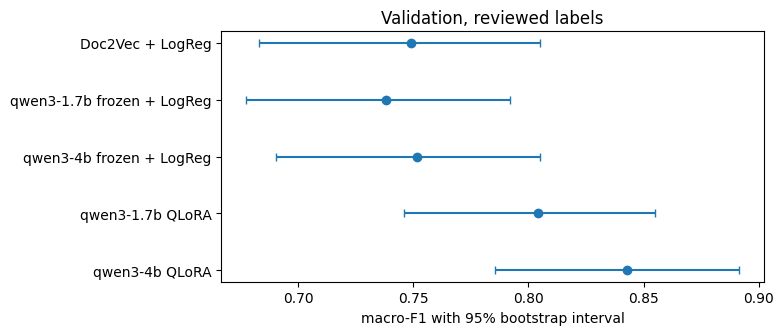

Best: qwen3-4b QLoRA

                     precision    recall  f1-score   support

     model_families      0.845     0.875     0.860        56
  china_geopolitics      0.914     0.889     0.901        36
research_techniques      1.000     0.636     0.778        22
    developer_tools      0.840     0.857     0.848        49
   business_compute      0.776     0.884     0.826        43

           accuracy                          0.850       206
          macro avg      0.875     0.828     0.843       206
       weighted avg      0.858     0.850     0.849       206



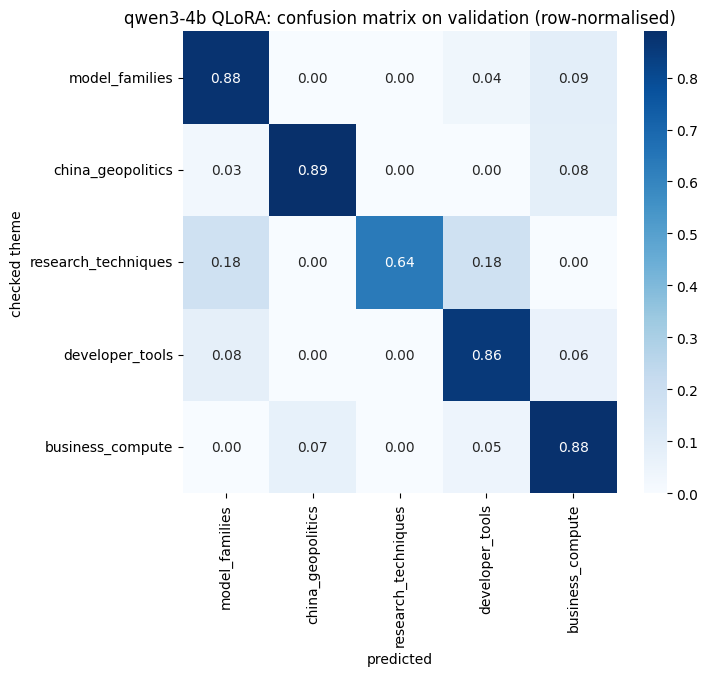

In [ ]:
results = pd.DataFrame(RESULTS).drop_duplicates("method", keep="last").set_index("method")
results.to_csv(RUN_DIR / "results_validation.csv")
display(results.round(3))

fig, ax = plt.subplots(figsize=(7, 0.45 * len(results) + 1))
ax.errorbar(results["macro_f1"], range(len(results)), fmt="o", capsize=3,
            xerr=[results["macro_f1"] - results["f1_low"], results["f1_high"] - results["macro_f1"]])
ax.set(yticks=range(len(results)), yticklabels=results.index, xlabel="macro-F1 with 95% bootstrap interval",
       title="Validation, reviewed labels")
ax.invert_yaxis()
save_fig(fig, "results_validation")

# Per-theme scores and confusion matrix of the best method
best = results["macro_f1"].idxmax()
y_true = sets["validation"]["eval_label"].to_numpy()
keep = y_true >= 0
print(f"Best: {best}\n")
print(classification_report(y_true[keep], PREDICTIONS[best][keep], target_names=LABELS, digits=3))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_true[keep], PREDICTIONS[best][keep], normalize="true"), annot=True, fmt=".2f",
            cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=ax)
ax.set(title=f"{best}: confusion matrix on validation (row-normalised)", xlabel="predicted", ylabel="checked theme")
save_fig(fig, "confusion_best")

**Interpretation**:
- **Fine-tuning helps.** The QLoRA models score highest (0.80 for Qwen3-1.7B, 0.84 for Qwen3-4B), 7 to 9 points above the same frozen models with a linear classifier. As the classifier is the same, the gain comes from adapting the representation to the task.
- **Pre-training alone does not.** The frozen compact models (0.74 and 0.75) score no better than Doc2Vec (0.75), which was trained on this corpus only.
- **Per theme**, `china_geopolitics` is the easiest theme (F1 0.90): its vocabulary (China, export controls, policy) is distinctive. `research_techniques` is the hardest: its precision is 1.00 but its recall only 0.64. Missed research articles are predicted as `model_families` or `developer_tools` (18% each): research is often reported through a model release or a tool, and it is the smallest theme (97 training articles).
- Whether these differences are reliable is tested in Section 2.6.3.

### 2.6.3 Are the differences reliable?
The bootstrap intervals above are wide (about ±6 points), so two checks are added:
1. **Hand-checked labels only**: the training labels come from an LLM, and 112 of the validation labels were made with its help (Section 2.2.3). If the scores partly measured the agreement with the LLM, they would change on the 98 articles checked by hand without it (`label_source = human`).
2. **Paired differences**: two methods are compared on the same resampled articles; `p` is the share of resamples where the first method is not better (one-sided).

In [ ]:
val = sets["validation"]
y = val["eval_label"].to_numpy()
subsets = {"all": y >= 0}
if "label_source" in val:
    subsets["hand-checked"] = (y >= 0) & (val["label_source"] == "human").to_numpy()
    subsets["made with the LLM"] = (y >= 0) & (val["label_source"] != "human").to_numpy()

robust = pd.DataFrame({f"{name} (n={mask.sum()})": {m: f1_score(y[mask], p[mask], average="macro") for m, p in PREDICTIONS.items()}
                       for name, mask in subsets.items()})
robust.to_csv(RUN_DIR / "results_robustness.csv")
# Validation predictions of every method, for the paired tests of Part 3
pd.DataFrame({"doc_id": val["doc_id"].to_numpy(), **{m: np.array(LABELS)[p] for m, p in PREDICTIONS.items()}}).to_parquet(
    RUN_DIR / "predictions_validation.parquet", index=False)
display(robust.round(3))

,all (n=206),hand-checked (n=98),made with the LLM (n=108)
Doc2Vec + LogReg,0.749,0.740,0.754
qwen3-1.7b frozen + LogReg,0.738,0.713,0.749
qwen3-4b frozen + LogReg,0.752,0.754,0.735
qwen3-1.7b QLoRA,0.804,0.796,0.801
qwen3-4b QLoRA,0.843,0.788,0.886


In [ ]:
def paired_bootstrap(a, b, mask, n=1000):
    """Macro-F1 of method a minus method b on the same resamples of the articles in mask."""
    yt, pa, pb = y[mask], PREDICTIONS[a][mask], PREDICTIONS[b][mask]
    idx = np.random.default_rng(SEED).integers(0, len(yt), (n, len(yt)))
    d = np.array([f1_score(yt[i], pa[i], average="macro") - f1_score(yt[i], pb[i], average="macro") for i in idx])
    return {"difference": f1_score(yt, pa, average="macro") - f1_score(yt, pb, average="macro"),
            "low": np.percentile(d, 2.5), "high": np.percentile(d, 97.5), "p": (d <= 0).mean()}

names = list(MODELS)
PAIRS = ([(f"{m} QLoRA", "Doc2Vec + LogReg") for m in names] + [(f"{m} QLoRA", f"{m} frozen + LogReg") for m in names]
         + [(f"{b} QLoRA", f"{a} QLoRA") for i, a in enumerate(names) for b in names[i + 1:]])
paired = pd.DataFrame([{"comparison": f"{a} vs {b}", "labels": name, **paired_bootstrap(a, b, mask)}
                       for a, b in PAIRS if a in PREDICTIONS and b in PREDICTIONS
                       for name, mask in subsets.items() if name != "made with the LLM"])
paired.to_csv(RUN_DIR / "results_paired.csv", index=False)
display(paired.set_index(["comparison", "labels"]).round(3))

difference  \
comparison                                     labels                     
qwen3-1.7b QLoRA vs Doc2Vec + LogReg           all                0.055   
                                               hand-checked       0.057   
qwen3-4b QLoRA vs Doc2Vec + LogReg             all                0.094   
                                               hand-checked       0.048   
qwen3-1.7b QLoRA vs qwen3-1.7b frozen + LogReg all                0.066   
                                               hand-checked       0.083   
qwen3-4b QLoRA vs qwen3-4b frozen + LogReg     all                0.091   
                                               hand-checked       0.034   
qwen3-4b QLoRA vs qwen3-1.7b QLoRA             all                0.039   
                                               hand-checked      -0.009   

                                                               low   high  \
comparison                                     labels                       
qwen3-1.7b QLoRA vs Doc2Vec + LogReg           all          -0.015  0.128   
                                               hand-checked -0.049  0.164   
qwen3-4b QLoRA vs Doc2Vec + LogReg             all           0.029  0.165   
                                               hand-checked -0.057  0.159   
qwen3-1.7b QLoRA vs qwen3-1.7b frozen + LogReg all           0.002  0.129   
                                               hand-checked -0.011  0.180   
qwen3-4b QLoRA vs qwen3-4b frozen + LogReg     all           0.028  0.158   
                                               hand-checked -0.059  0.134   
qwen3-4b QLoRA vs qwen3-1.7b QLoRA             all          -0.011  0.087   
                                               hand-checked -0.096  0.074   

                                                                 p  
comparison                                     labels               
qwen3-1.7b QLoRA vs Doc2Vec + LogReg           all           0.043  
                                               hand-checked  0.140  
qwen3-4b QLoRA vs Doc2Vec + LogReg             all           0.001  
                                               hand-checked  0.173  
qwen3-1.7b QLoRA vs qwen3-1.7b frozen + LogReg all           0.023  
                                               hand-checked  0.044  
qwen3-4b QLoRA vs qwen3-4b frozen + LogReg     all           0.002  
                                               hand-checked  0.255  
qwen3-4b QLoRA vs qwen3-1.7b QLoRA             all           0.061  
                                               hand-checked  0.584

**Interpretation**:
- **Fine-tuning versus the baselines**: on all 206 validation articles, QLoRA is better than the frozen model of the same size (Qwen3-1.7B +7 points, p = 0.02; Qwen3-4B +9, p = 0.002) and than Doc2Vec (+6, p = 0.04; +9, p = 0.001). On the 98 hand-checked articles, the differences keep the same sign (+3 to +8), but with so few articles only the gain of Qwen3-1.7B over its frozen model stays significant (p = 0.04).
- **Model size**: Qwen3-4B is not better than Qwen3-1.7B (+4 points on all articles, p = 0.06; −1 on the hand-checked articles). Its advantage comes only from the validation labels made with the LLM (0.89 vs 0.80): the larger model may follow the judgement of the LLM annotator more closely rather than classify the themes better. The two subsets also differ in difficulty, so this comparison is only indicative.
- The scores of the QLoRA models vary by up to 1 point between runs (4-bit GPU kernels are not deterministic); smaller differences are not meaningful.

### 2.6.4 Input length
The compact models read only the **first `MAX_LEN` tokens** of an article (Section 2.2.4), while Doc2Vec reads the whole article. Every representation is therefore evaluated on both inputs:

| Representation | First `MAX_LEN` tokens | Whole article |
|---|---|---|
| Doc2Vec | vector inferred from the first `MAX_LEN` tokens | vector inferred from the whole article (+ Part 1 vectors) |
| Frozen compact model | Section 2.5.2 | mean of the vectors of consecutive windows of `MAX_LEN` tokens |
| Fine-tuned compact model | Section 2.6.2 | mean of the predicted probabilities of the windows (no re-training) |

An article is split into at most `MAX_WINDOWS` windows; longer articles are cut after the last window. The Doc2Vec vectors are all inferred here (also for the training articles), so that both Doc2Vec inputs are built the same way.

In [ ]:
MAX_WINDOWS = 4   # up to 4 x 512 = 2,048 tokens per article

def windows(texts, tok, max_windows=MAX_WINDOWS):
    """Token ids of consecutive windows of MAX_LEN tokens, and the position of the text of every window."""
    ids, owner = [], []
    for i, text_ids in enumerate(tok(texts, add_special_tokens=False)["input_ids"]):
        for start in range(0, min(len(text_ids), max_windows * MAX_LEN), MAX_LEN):
            ids.append(text_ids[start:start + MAX_LEN])
            owner.append(i)
    return ids, np.array(owner)

def window_batches(ids, tok, batch_size=16):
    order = np.argsort([-len(x) for x in ids], kind="stable")
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        yield idx, tok.pad({"input_ids": [ids[j] for j in idx]}, return_tensors="pt").to("cuda")

def per_text(values, owner):
    """Mean of the window values of every text."""
    return np.vstack([values[owner == i].mean(0) for i in range(owner.max() + 1)])

# Length of the articles of the task, in tokens of the main model
tok = load_tokenizer(next(iter(MODELS.values())))
n_tokens = pd.Series([len(x) for x in tok(model_input(task), add_special_tokens=False)["input_ids"]])
print(f"Articles longer than {MAX_LEN} tokens: {(n_tokens > MAX_LEN).mean():.1%} | "
      f"longer than {MAX_WINDOWS * MAX_LEN}: {(n_tokens > MAX_WINDOWS * MAX_LEN).mean():.1%} | "
      f"median {n_tokens.median():.0f} tokens")

Articles longer than 512 tokens: 99.6% | longer than 2048: 30.8% | median 1545 tokens


#### Doc2Vec on both inputs
The Doc2Vec model of Part 1 infers a vector for any text. The text is normalised and tokenised with the functions of Part 1 (Sections 1.1.2 and 1.1.3), which are taken from the WP1 notebook so that both parts use exactly the same preprocessing. The "first tokens" input is the text of the first `MAX_LEN` tokens of the compact model, so that both models read the same beginning of the article.

In [ ]:
from gensim.models.doc2vec import Doc2Vec

d2v = Doc2Vec.load(str(WP1_DIR / "doc2vec.model"))

# Normalisation and tokenisation of Part 1, run from the WP1 notebook (they use the WP1 lexicon)
lexicon = json.loads((REPO / "artifacts/stage1_wp1/lexicon/open_models_lexicon.json").read_text(encoding="utf-8"))
wp1_nb = json.loads((REPO / "stage2/work_packages/stage2_wp1_embeddings.ipynb").read_text(encoding="utf-8"))
for marker in ("def normalise(", "def doc_sentences("):
    exec(next("".join(c["source"]) for c in wp1_nb["cells"]
              if c["cell_type"] == "code" and marker in "".join(c["source"])))

def d2v_infer(texts):
    return np.vstack([d2v.infer_vector([t for s in doc_sentences(normalise(x)) for t in s], epochs=d2v.epochs)
                      for x in texts])

def first_tokens(texts, tok):
    """Text of the first MAX_LEN tokens of every text, as read by the compact models."""
    return tok.batch_decode([x[:MAX_LEN] for x in tok(texts, add_special_tokens=False)["input_ids"]])

D2V_LEN_PATH = OUT_DIR / "d2v_length.npz"
if D2V_LEN_PATH.exists():
    d2v_len = dict(np.load(D2V_LEN_PATH))
else:
    d2v_len = {f"{split}_{inp}": d2v_infer(texts) for split, df in [("fit", fit_part), ("val", sets["validation"])]
               for inp, texts in [("first", first_tokens(model_input(df), tok)), ("whole", model_input(df))]}
    np.savez(D2V_LEN_PATH, **d2v_len)

for inp in ["first", "whole"]:
    record(f"Doc2Vec (inferred, {inp}) + LogReg",
           linear_probe(d2v_len[f"fit_{inp}"], fit_part["label"], d2v_len[f"val_{inp}"]))

Doc2Vec (inferred, first) + LogReg macro-F1 0.745 [0.681, 0.803] | on topic labels 0.540
Doc2Vec (inferred, whole) + LogReg macro-F1 0.762 [0.696, 0.820] | on topic labels 0.520


#### Compact models on the whole article

In [ ]:
for name, repo in MODELS.items():
    tok = load_tokenizer(repo)

    # Frozen model: mean of the window vectors
    path = OUT_DIR / f"emb_{name}_base_windows.npz"
    if path.exists():
        E = dict(np.load(path))
    else:
        base = AutoModel.from_pretrained(repo, quantization_config=BNB, device_map="auto")
        base.eval()
        E = {}
        with track(name, "embed_base_windows"):
            for tag, df in [("fit", fit_part), ("val", sets["validation"])]:
                ids, owner = windows(model_input(df), tok)
                E[tag] = per_text(run(lambda b: mean_pooled(base, b), window_batches(ids, tok)), owner)
        np.savez(path, **E)
        del base; free_memory()
    record(f"{name} frozen (whole) + LogReg", linear_probe(E["fit"], fit_part["label"], E["val"]))

    # Fine-tuned model: mean of the window probabilities
    path = RUN_DIR / f"proba_{name}_ft_windows_val.npy"
    if path.exists():
        P = np.load(path)
    else:
        ft, tok = finetune(name, repo)
        ft.eval()
        ids, owner = windows(model_input(sets["validation"]), tok)
        with track(name, "predict_validation_windows"):
            P = per_text(run(lambda b: class_proba(ft, b), window_batches(ids, tok)), owner)
        np.save(path, P)
        del ft; free_memory()
    record(f"{name} fine-tuned (whole)", P.argmax(1))

qwen3-1.7b frozen (whole) + LogReg macro-F1 0.696 [0.632, 0.754] | on topic labels 0.548
qwen3-1.7b fine-tuned (whole)      macro-F1 0.765 [0.700, 0.821] | on topic labels 0.539
qwen3-4b frozen (whole) + LogReg   macro-F1 0.727 [0.665, 0.785] | on topic labels 0.549
qwen3-4b fine-tuned (whole)        macro-F1 0.789 [0.729, 0.844] | on topic labels 0.562


input,first tokens,whole article,whole article (Part 1 vectors)
representation,,,
Doc2Vec,0.745,0.762,0.749
qwen3-1.7b fine-tuned,0.804,0.765,NaN
qwen3-1.7b frozen,0.738,0.696,NaN
qwen3-4b fine-tuned,0.843,0.789,NaN
qwen3-4b frozen,0.752,0.727,NaN


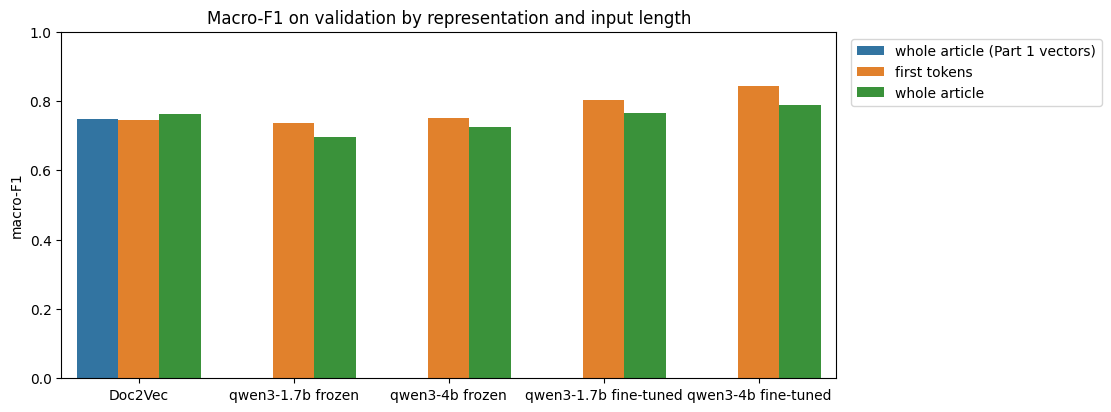

In [ ]:
# Representation x input
def describe(method):
    if method.startswith("Doc2Vec"):
        rep = "Doc2Vec"
        inp = "first tokens" if "first" in method else "whole article"
        inp += " (Part 1 vectors)" if method == "Doc2Vec + LogReg" else ""
    else:
        model = method.split(" ")[0]
        rep = f"{model} {'frozen' if 'frozen' in method else 'fine-tuned'}"
        inp = "whole article" if "(whole)" in method else "first tokens"
    return rep, inp

length = pd.DataFrame(RESULTS).drop_duplicates("method", keep="last")
length[["representation", "input"]] = length["method"].apply(lambda m: pd.Series(describe(m)))
length.to_csv(RUN_DIR / "results_input_length.csv", index=False)
display(length.pivot_table(index="representation", columns="input", values="macro_f1").round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=length, x="representation", y="macro_f1", hue="input", ax=ax)
ax.set(title="Macro-F1 on validation by representation and input length", xlabel="", ylabel="macro-F1", ylim=(0, 1))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "input_length")

**Interpretation**: reading the whole article does not help. The fine-tuned models drop (Qwen3-4B 0.84 → 0.79, Qwen3-1.7B 0.80 → 0.77), the frozen models drop by 2 to 4 points, and Doc2Vec changes by less than 2 points. The main subject of a news article is stated in its title and lead; averaging the windows gives the later parts, which often digress, the same weight as the beginning. For this task, the first 512 tokens are enough.

Limitation: the reviewed labels were made from the beginning of the articles (600 characters by hand, 6,000 by the LLM), which can favour the first-tokens input. With the topic labels, which the topic model computed from all the words of an article, the whole article helped instead (Section 2.6.5).

### 2.6.5 First run with the topic labels
The first run of this notebook trained and evaluated every method on the topic labels. It is kept to show how much the conclusions depend on the labels. The table compares the models trained on the topic labels (`trained on silver`) and on the reviewed labels (`trained on checked`), each scored on the reviewed labels (`macro_f1`, with interval) and on the topic labels (`macro_f1_silver`). It needs one run with each value of `TRAIN_LABELS`; all caches are kept, so the second run only trains what depends on the labels.

In [ ]:
runs = {version: OUT_DIR / ("" if version == "silver" else version) / "results_input_length.csv"
        for version in ["silver", "checked"]}
runs = {version: pd.read_csv(path, index_col="method") for version, path in runs.items() if path.exists()}
runs = {version: r for version, r in runs.items() if "macro_f1_silver" in r}   # results of the current notebook only

if len(runs) == 2:
    comparison = pd.concat({f"trained on {version}": r[["macro_f1", "f1_low", "f1_high", "macro_f1_silver"]]
                            for version, r in runs.items()}, axis=1)
    comparison[("gain", "macro_f1")] = (comparison[("trained on checked", "macro_f1")]
                                        - comparison[("trained on silver", "macro_f1")])
    comparison.to_csv(OUT_DIR / "results_label_versions.csv")
    display(comparison.round(3))
else:
    print("Run the notebook with TRAIN_LABELS =", " and ".join(f'"{v}"' for v in ["silver", "checked"] if v not in runs))

trained on silver                 \
                                            macro_f1 f1_low f1_high   
method                                                                
Doc2Vec + LogReg                               0.605  0.534   0.666   
qwen3-1.7b frozen + LogReg                     0.656  0.590   0.717   
qwen3-4b frozen + LogReg                       0.656  0.592   0.719   
qwen3-1.7b QLoRA                               0.635  0.568   0.693   
qwen3-4b QLoRA                                 0.659  0.593   0.720   
Doc2Vec (inferred, first) + LogReg             0.618  0.552   0.678   
Doc2Vec (inferred, whole) + LogReg             0.613  0.544   0.672   
qwen3-1.7b frozen (whole) + LogReg             0.614  0.550   0.673   
qwen3-1.7b fine-tuned (whole)                  0.655  0.586   0.719   
qwen3-4b frozen (whole) + LogReg               0.673  0.606   0.732   
qwen3-4b fine-tuned (whole)                    0.684  0.619   0.747   

                                                   trained on checked         \
                                   macro_f1_silver           macro_f1 f1_low   
method                                                                         
Doc2Vec + LogReg                             0.738              0.749  0.683   
qwen3-1.7b frozen + LogReg                   0.611              0.738  0.677   
qwen3-4b frozen + LogReg                     0.607              0.752  0.691   
qwen3-1.7b QLoRA                             0.693              0.804  0.746   
qwen3-4b QLoRA                               0.678              0.843  0.786   
Doc2Vec (inferred, first) + LogReg           0.658              0.745  0.681   
Doc2Vec (inferred, whole) + LogReg           0.718              0.762  0.696   
qwen3-1.7b frozen (whole) + LogReg           0.575              0.696  0.632   
qwen3-1.7b fine-tuned (whole)                0.717              0.765  0.700   
qwen3-4b frozen (whole) + LogReg             0.640              0.727  0.665   
qwen3-4b fine-tuned (whole)                  0.711              0.789  0.729   

                                                               gain  
                                   f1_high macro_f1_silver macro_f1  
method                                                               
Doc2Vec + LogReg                     0.805           0.540    0.144  
qwen3-1.7b frozen + LogReg           0.792           0.527    0.082  
qwen3-4b frozen + LogReg             0.805           0.535    0.096  
qwen3-1.7b QLoRA                     0.855           0.544    0.169  
qwen3-4b QLoRA                       0.891           0.536    0.183  
Doc2Vec (inferred, first) + LogReg   0.803           0.540    0.127  
Doc2Vec (inferred, whole) + LogReg   0.820           0.520    0.149  
qwen3-1.7b frozen (whole) + LogReg   0.754           0.548    0.081  
qwen3-1.7b fine-tuned (whole)        0.821           0.539    0.110  
qwen3-4b frozen (whole) + LogReg     0.785           0.549    0.054  
qwen3-4b fine-tuned (whole)          0.844           0.562    0.105

**Interpretation**: the conclusions of this part need the reviewed labels.
- Trained and scored on the topic labels, Doc2Vec ranked first (0.74), ahead of QLoRA (0.68 – 0.69) and the frozen models (0.61): the topic labels reward the representation closest to the topic model that made them, as both are built on word counts. Scored on the reviewed labels, the same Doc2Vec model comes last (0.61).
- Trained on the reviewed labels, every method improves, the fine-tuned models most (+17 and +18 points); only then does the gain of fine-tuning become visible.
- The effect of the input length also reverses: with the topic labels, the whole article helped (QLoRA Qwen3-1.7B 0.69 → 0.72, scored on the topic labels).

## 2.7 Article Vectors for the Comparative Evaluation
Part 3 compares all representations on the same intrinsic tasks (semantic similarity, clustering quality, visualisation). The article vectors of the compact models are therefore saved **in the same format as `doc_vectors.parquet` of Part 1** (`doc_id`, `split`, `om_tier`, `track`, `vector`), for two versions of each model: the frozen pre-trained model (`base`) and the fine-tuned model (`ft`).

The vectors are computed for the **same articles as the t-SNE map of Part 1** (all open-models articles and the same random sample of 4,000 other articles, same seed), so the maps of the classical and the compact models can be compared one to one. Embedding all 45,462 articles would take several hours on a T4.

In [ ]:
# Same sample as Part 1 (Section 1.3.3)
rng = np.random.default_rng(SEED)
track_idx = np.flatnonzero(doc_vectors["track"].to_numpy())
none_idx = np.flatnonzero(~doc_vectors["track"].to_numpy())
sample_idx = np.concatenate([track_idx, rng.choice(none_idx, size=min(len(none_idx), 4000), replace=False)])
vec_docs = doc_vectors.iloc[sample_idx][["doc_id", "split", "om_tier", "track"]].reset_index(drop=True)

titles = dict(zip(core["doc_id"], core["title"]))   # titles exist for core articles only
vec_docs = vec_docs.merge(corpus[["doc_id", "text"]], on="doc_id")
vec_docs["title"] = vec_docs["doc_id"].map(titles)
print(f"{len(vec_docs):,} articles to embed")

8,037 articles to embed


In [ ]:
def save_vectors(name, tag, E):
    vec_docs[["doc_id", "split", "om_tier", "track"]].assign(vector=list(E)).to_parquet(
        (OUT_DIR if tag == "base" else RUN_DIR) / f"llm_doc_vectors_{name}_{tag}.parquet", index=False)

for name, repo in MODELS.items():
    tok = load_tokenizer(repo)
    if not (OUT_DIR / f"llm_doc_vectors_{name}_base.parquet").exists():
        base = AutoModel.from_pretrained(repo, quantization_config=BNB, device_map="auto")
        save_vectors(name, "base", embed_cached(name, base, tok, vec_docs, "base_sample"))
        del base; free_memory()
    if not (RUN_DIR / f"llm_doc_vectors_{name}_ft.parquet").exists():
        ft, tok = finetune(name, repo)
        save_vectors(name, "ft", embed_cached(name, ft, tok, vec_docs, "ft_sample"))
        del ft; free_memory()

## 2.8 Open-Models Track: Unseen Model Names and Theme Trends
### 2.8.1 Unseen model names
Part 1 showed that Word2Vec has no vector for model names that never appeared in training, and that FastText gives them one from their character n-grams, so that its neighbours follow the spelling. The invented names of Part 1 (`qwen999-max`, `llama-999`, `deepseek-r999`) contain the name of their family: a model that splits words into sub-words will find the family from the spelling alone. They are kept for the comparison with Part 1, but they cannot show whether a model places a new name by its **meaning**.

The test therefore asks whether the compact model links an unseen name to its family **from the context**. Each name is placed in a sentence whose beginning names a company, and the vector of the **name tokens only** is compared with the vectors of five known family names:

| condition | example | expected nearest family |
|---|---|---|
| spelling | "A company has released its newest open-weight language model, qwen999-max." | the family in the name (Qwen) |
| context | "Meta has released its newest open-weight language model, Velora-7B." | the family of the company (Llama) |
| conflict | "Meta has released its newest open-weight language model, qwen999-max." | context (Llama) or spelling (Qwen)? |
| control | "A company has released its newest open-weight language model, Velora-7B." | no family: about 20% per family |

The company comes before the name because the model reads from left to right: the vector of a token depends only on the tokens before it. The family names are embedded in the neutral sentence, so that their vectors reflect what the model knows about them. All vectors are centred before the cosine similarity, because the vectors of a language model share a common direction that makes every similarity high. FastText, which does not read the context, follows the spelling in every conflict sentence by construction.

In [ ]:
FAMILIES = ["Qwen", "Llama", "DeepSeek", "Gemma", "Nemotron"]
COMPANY = {"Qwen": "Alibaba Cloud", "Llama": "Meta", "DeepSeek": "The Chinese lab behind the R1 reasoning model",
           "Gemma": "Google DeepMind", "Nemotron": "NVIDIA"}
NEUTRAL = "A company"
FRAME = "{} has released its newest open-weight language model, {}."   # company first: the model reads left to right
SPELLED = {"qwen999-max": "Qwen", "llama-999": "Llama", "deepseek-r999": "DeepSeek"}   # invented names of Part 1
INVENTED = ["Velora-7B", "Kestrix-2", "Orvane-9B", "Tamsin-3", "Brivo-14B"]          # no family in the name

rows = []
for word in INVENTED:
    rows += [("control", word, None, None)] + [("context", word, f, None) for f in FAMILIES]
for word, family in SPELLED.items():
    rows += [("spelling", word, None, family)] + [("conflict", word, f, family) for f in FAMILIES if f != family]
tests = pd.DataFrame(rows, columns=["condition", "name", "context_family", "spelling_family"])
tests["sentence"] = [FRAME.format(COMPANY[f] if f else NEUTRAL, w) for w, f in zip(tests["name"], tests["context_family"])]

@torch.no_grad()
def name_vectors(model, tok, sentences, names):
    """Mean of the last hidden states of the tokens of the name, not of the whole sentence."""
    model.eval()
    out = []
    for sentence, word in zip(sentences, names):
        enc = tok(sentence, return_offsets_mapping=True, return_tensors="pt")
        start = sentence.rindex(word)
        in_name = torch.tensor([a < start + len(word) and b > start for a, b in enc.pop("offset_mapping")[0].tolist()])
        hidden = model(**enc.to("cuda"), output_hidden_states=True).hidden_states[-1][0]
        out.append(hidden[in_name.to(hidden.device)].float().mean(0).cpu().numpy())
    return np.vstack(out)

def nearest_family(model, tok):
    V = name_vectors(model, tok, list(tests["sentence"]) + [FRAME.format(NEUTRAL, f) for f in FAMILIES],
                     list(tests["name"]) + FAMILIES)
    V = unit(V - V.mean(0))   # centre: remove the direction shared by all vectors
    return np.array(FAMILIES)[(V[:len(tests)] @ V[len(tests):].T).argmax(1)]

name, repo = next(iter(MODELS.items()))   # main model
tok = load_tokenizer(repo)
for word in list(SPELLED) + INVENTED:
    print(f"{word:15} -> {tok.tokenize(' ' + word)}")

base = AutoModel.from_pretrained(repo, quantization_config=BNB, device_map="auto")
tests["frozen"] = nearest_family(base, tok)
del base; free_memory()
ft, tok = finetune(name, repo)
tests["fine-tuned"] = nearest_family(ft, tok)
del ft; free_memory()
tests.to_csv(RUN_DIR / "unseen_names.csv", index=False)

def share(condition, target):
    d = tests[tests["condition"] == condition]
    return {"sentences": len(d), **{m: (d[m] == d[target]).mean() for m in ["frozen", "fine-tuned"]}}

display(pd.DataFrame({"spelling: nearest = family in the name": share("spelling", "spelling_family"),
                      "context: nearest = family of the company": share("context", "context_family"),
                      "conflict: follows the company": share("conflict", "context_family"),
                      "conflict: follows the spelling": share("conflict", "spelling_family")}).T.round(2))
print("Control sentences (no family), nearest family:")
display(tests[tests["condition"] == "control"].set_index("name")[["frozen", "fine-tuned"]])

qwen999-max     -> ['Ġq', 'wen', '9', '9', '9', '-max']
llama-999       -> ['Ġllama', '-', '9', '9', '9']
deepseek-r999   -> ['Ġdeep', 'seek', '-r', '9', '9', '9']
Velora-7B       -> ['ĠVel', 'ora', '-', '7', 'B']
Kestrix-2       -> ['ĠK', 'est', 'rix', '-', '2']
Orvane-9B       -> ['ĠOr', 'v', 'ane', '-', '9', 'B']
Tamsin-3        -> ['ĠT', 'ams', 'in', '-', '3']
Brivo-14B       -> ['ĠBr', 'ivo', '-', '1', '4', 'B']


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[transformers] Qwen3Model LOAD REPORT from: Qwen/Qwen3-1.7B
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-1.7B
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


qwen3-1.7b: adapter loaded


,sentences,frozen,fine-tuned
spelling: nearest = family in the name,3.0,1.0,1.00
context: nearest = family of the company,25.0,0.2,0.32
conflict: follows the company,12.0,0.0,0.00
conflict: follows the spelling,12.0,1.0,1.00


Control sentences (no family), nearest family:


,frozen,fine-tuned
name,,
Velora-7B,Gemma,Gemma
Kestrix-2,Qwen,Qwen
Orvane-9B,Qwen,Qwen
Tamsin-3,Llama,Qwen
Brivo-14B,Qwen,Qwen


**Interpretation**: the compact model places unseen names by their **spelling, not by their context**.
- **Spelling**: the three names of Part 1 are all closest to the family in their name, for the frozen and the fine-tuned model. As with FastText, the sub-words (`q` + `wen`, `llama`, `deep` + `seek`) are enough.
- **Context**: without a family in the name, the company before it does not lead to the right family: 20% of the sentences for the frozen model, the rate of chance with five families, and 32% for the fine-tuned model (8 of 25, p = 0.11 against chance). The control sentences show why this small gain is not evidence of context use: without any company, the fine-tuned model places 4 of the 5 invented names next to Qwen, so a part of its correct answers can come from this preference.
- **Conflict**: when the spelling and the company disagree, both models follow the spelling in all 12 sentences, as FastText does by construction.

The compact models therefore solve the problem of Word2Vec (every name gets a vector), but for names, they behave like FastText rather than like a reader who links a new model to its developer. Fine-tuning on theme classification does not change this, which is expected: the task does not require knowing the family of a model. Limitations: one sentence frame, five families and the last layer only; the vector of a token in a left-to-right model also encodes the prediction of the next token.

### 2.8.2 Theme trends beyond the labelled articles
Only the core articles have a Stage 1 topic. The fine-tuned classifier can label the **mention** articles too (2,827 articles that name open models without being centred on them), which extends the theme trends of the track to a larger part of the corpus. The predictions are saved for the insight extraction in Part 3.

As the classifier was trained on core articles, its predictions on mention articles are less reliable: the predicted probability is kept so that Part 3 can filter on confidence.

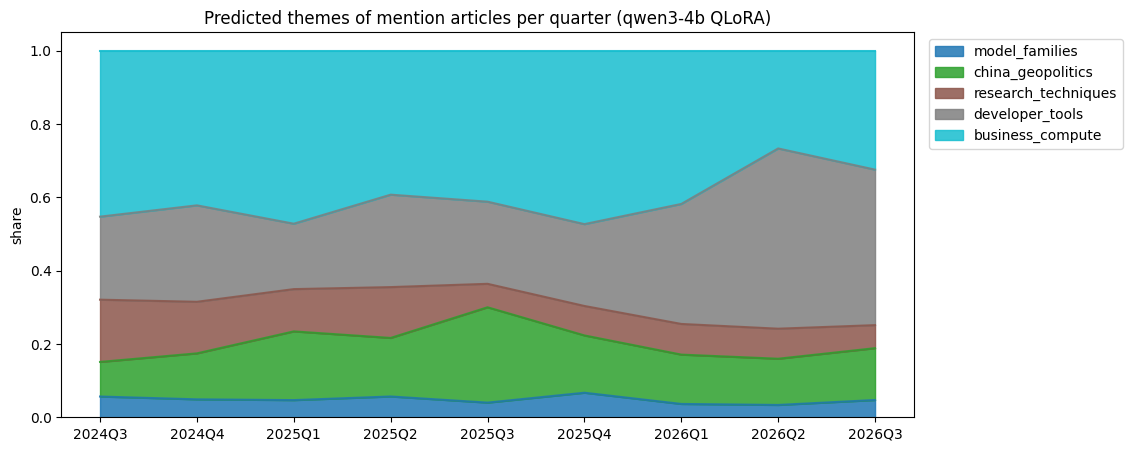

In [ ]:
best_name = results.filter(like="QLoRA", axis=0)["macro_f1"].idxmax().replace(" QLoRA", "")
PRED_PATH = RUN_DIR / f"predictions_track_{best_name}.parquet"   # one file per model, so a new best model is not read from an old cache

if PRED_PATH.exists():
    preds = pd.read_parquet(PRED_PATH)
else:
    track_docs = corpus[corpus["om_tier"].isin(["core", "mention", "reference"])][["doc_id", "quarter", "om_tier", "split", "text"]]
    track_docs = track_docs.assign(title=track_docs["doc_id"].map(titles))
    ft, tok = finetune(best_name, MODELS[best_name])
    with track(best_name, "predict_track"):
        P = predict_proba(ft, tok, model_input(track_docs))
    del ft; free_memory()
    preds = track_docs.drop(columns=["text", "title"]).assign(model=best_name, pred=[LABELS[i] for i in P.argmax(1)],
                                                             confidence=P.max(1))
    preds = preds.join(pd.DataFrame(P, columns=[f"p_{l}" for l in LABELS], index=preds.index))
    preds.to_parquet(PRED_PATH, index=False)

share = (preds[preds["om_tier"] == "mention"].groupby("quarter")["pred"].value_counts(normalize=True)
         .unstack(fill_value=0).reindex(columns=LABELS, fill_value=0))
fig, ax = plt.subplots(figsize=(11, 5))
share.plot.area(ax=ax, cmap="tab10", alpha=0.85)
ax.set(title=f"Predicted themes of mention articles per quarter ({best_name} QLoRA)", xlabel="", ylabel="share")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "theme_share_mention")

**Interpretation** (shares read from the figure; the classifier was trained on core articles, so the predictions on mention articles are less reliable):
- `developer_tools` grows the most: from about 23% of the mention articles in 2024Q3 to about 49% in 2026Q2 (42% in 2026Q3). Open models are increasingly mentioned as building blocks of agents, coding tools and platforms.
- `business_compute` is the largest theme until 2025Q4 (about 40–47%) and falls to about 27–33% in 2026.
- `research_techniques` shrinks from about 17% to 6–9%, and `china_geopolitics` peaks in 2025Q3 (about 26%).
- `model_families` stays small (4–7%), as expected: mention articles name open models without being about them.

Part 3 can restrict these trends to confident predictions (`confidence` column) and compare them with the topic trends of Stage 1.

## 2.9 Resource Summary
Size, training time, peak GPU memory and validation score of each fine-tuned model, from the resource log of Section 2.4 (`resources.json`). The times depend on the GPU each step ran on (`train_gpu`, `val_predict_gpu`): they are compared between models only when the GPU is the same.

In [ ]:
# Trade-off summary for Part 3
rows = []
for name in MODELS:
    r = RESOURCES.get(name, {})
    rows.append({"model": name, "total_params_M": r.get("total_params", np.nan) / 1e6,
                 "trainable_pct": r.get("trainable_pct"), "adapter_mb": r.get("adapter_mb"),
                 "train_gpu": r.get("finetune", {}).get("gpu"),
                 "train_min": r.get("finetune", {}).get("seconds", np.nan) / 60,
                 "train_peak_vram_gb": r.get("finetune", {}).get("peak_vram_gb"),
                 "val_predict_gpu": r.get("predict_validation", {}).get("gpu"),
                 "val_predict_s": r.get("predict_validation", {}).get("seconds"),
                 "val_macro_f1": results["macro_f1"].get(f"{name} QLoRA")})
display(pd.DataFrame(rows).round(2))

,model,total_params_M,trainable_pct,adapter_mb,train_gpu,train_min,train_peak_vram_gb,val_predict_gpu,val_predict_s,val_macro_f1
0,qwen3-1.7b,1727.02,0.37,24.6,NVIDIA L4,9.01,2.82,NVIDIA L4,14.1,0.80
1,qwen3-4b,4034.29,0.29,45.1,NVIDIA L4,21.16,4.80,NVIDIA L4,28.8,0.84


# 3. Comparative Evaluation and Insights
Part 1 trained classical representations on the corpus (Word2Vec, FastText, Doc2Vec). Part 2 adapted compact open models (Qwen3-1.7B and Qwen3-4B) with QLoRA and classified the open-models articles into five themes. This part puts them side by side and uses the best of them to analyse the discourse:
1. **Intrinsic evaluation of words**: do Word2Vec and FastText place similar words close together, in general English and for the terms of the open-models track?
2. **Intrinsic evaluation of articles**: do the article vectors of all representations group articles of the same theme, and separate the open-models articles from the rest of the corpus?
3. **Extrinsic evaluation**: the theme classification of Part 2, completed with the representations Part 2 did not test (TF-IDF, Word2Vec, FastText).
4. **Trade-offs**: model size, performance, training time, inference speed and GPU requirements of every representation.
5. **Insight extraction**: the AI discourse of the whole corpus (Doc2Vec) and the themes of the open-models track over time, by developer region and by model family (best fine-tuned model).

No model is trained in this part, except short timing runs (Section 3.5) and linear classifiers on fixed vectors, so **no GPU is needed**: everything starts from the outputs of Parts 1 and 2.

**Key results**:
1. **Fine-tuning gives the best theme representation**: the QLoRA vectors are the only ones that group articles of the same theme clearly better than the others (kNN accuracy 0.76 vs 0.63 – 0.66, Section 3.3), and Qwen3-4B QLoRA classifies the themes best (macro-F1 0.84, Section 3.4).
2. **A plain TF-IDF baseline comes close**: with a macro-F1 of 0.80 it beats every dense classical representation and both frozen compact models, and it is not significantly worse than Qwen3-4B QLoRA (−4.7 points, p = 0.06) and level with the recommended Qwen3-1.7B QLoRA, at a fraction of the cost (Sections 3.4 – 3.5).
3. **Pre-training alone does not help**: the frozen compact models score like the representations trained on the corpus, on every intrinsic and extrinsic test.
4. **Cost**: Qwen3-1.7B QLoRA is the best compromise among the compact models: same intrinsic scores and same macro-F1 on the hand-checked articles as Qwen3-4B, with 2.3× shorter training, 2× faster inference and 1.7× less GPU memory (Section 3.5).
5. **Track insight**: the open-models discourse moves from research and China–US rivalry towards **developer tools and agents** (core articles 18% → 29%, mention articles 23% → 36% between the two years); Chinese models are discussed through geopolitics (31% of their articles vs 7% for US models), US and European models through tools and business (Section 3.6).

**Cache**: the long steps (tokenisation of the compared articles, timing runs) save their result on Google Drive and load it when the notebook is run again.

| Team member | Sections | Contribution |
|---|---|---|
| Daliasny Gonzalez Guzman | 3.1 – 3.7 | intrinsic and extrinsic evaluation, comparison of trade-offs (size, performance, training speed, GPU), insight extraction on the open-models track |

## 3.1 Setup
Inputs:
- `corpus_clean.parquet` and `open_models_core.parquet` (Stage 1): the cleaned corpus with the relevance tier, developer regions and model families of every article, and the 1,210 core articles with their Stage 1 topic
- `artifacts/stage2_wp1/splits.parquet` (Part 1): the training / validation split shared by all Stage 2 parts
- `word2vec.model`, `fasttext.model`, `doc_vectors.parquet` (Part 1, Google Drive): the word embeddings and the Doc2Vec vector of every article
- `artifacts/stage2_wp2/labels_checked.csv` (Part 2): the reviewed theme labels of the 1,060 labelled core articles, with their label source
- `llm_doc_vectors_<model>_{base,ft}.parquet` (Part 2, Google Drive): the article vectors of the frozen (`base`) and fine-tuned (`ft`) compact models
- `results_*.csv`, `resources.json`, `predictions_track_qwen3-4b.parquet` (Part 2, Google Drive): scores, time and GPU memory of every step, and the theme predictions for all open-models articles

In [ ]:
!pip install -q gensim

In [ ]:
from pathlib import Path
import os

# Clone the project repository
REPO = Path("/content/computational-language-technology-hs26")
if REPO.exists():
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/jihyeon26/computational-language-technology-hs26.git {REPO}

# Mount Google Drive (input data and outputs)
from google.colab import drive
drive.mount("/content/drive")

# Inputs: Stage 1 outputs, Part 1 (WP1) and Part 2 (WP2) outputs
DATA_DIR = Path("/content/drive/MyDrive/HSLU/CLT/data/processed")
WP1_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp1")
WP2_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp2")   # outputs that do not depend on the labels
WP2_RUN = WP2_DIR / "checked"                                                      # outputs trained on the reviewed labels

# Outputs of this notebook (also used as cache), with a sub-folder for the figures
OUT_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp3")
FIG = OUT_DIR / "figures"
FIG.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Libraries
import json, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, accuracy_score, silhouette_score, normalized_mutual_info_score,
                             adjusted_rand_score, classification_report)
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
warnings.filterwarnings("ignore", category=FutureWarning)

# Fix the seed (same as Parts 1 and 2)
SEED = 42
np.random.seed(SEED)

# Cosine
def unit(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)

# Save figure and show it
def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

In [ ]:
# Stage 1 outputs (API reference pages left out, as in Parts 1 and 2)
corpus = pd.read_parquet(DATA_DIR / "corpus_clean.parquet",
                         columns=["doc_id", "date", "quarter", "title", "text", "om_tier", "om_regions", "om_families",
                                  "is_api_reference"])
corpus = corpus[~corpus["is_api_reference"]].drop(columns="is_api_reference").reset_index(drop=True)
core = pd.read_parquet(DATA_DIR / "open_models_core.parquet", columns=["doc_id", "dominant_topic_label"])
lexicon = json.loads((REPO / "artifacts/stage1_wp1/lexicon/open_models_lexicon.json").read_text(encoding="utf-8"))

# Shared split (Part 1) and reviewed theme labels (Part 2)
splits = pd.read_parquet(REPO / "artifacts/stage2_wp1/splits.parquet")
corpus["split"] = corpus["doc_id"].map(dict(zip(splits["doc_id"], splits["split"])))
corpus["track"] = corpus["om_tier"].ne("none")
labels = pd.read_csv(REPO / "artifacts/stage2_wp2/labels_checked.csv")

LABELS = ["model_families", "china_geopolitics", "research_techniques", "developer_tools", "business_compute"]   # order of Part 2
LABEL_ID = {label: i for i, label in enumerate(LABELS)}
labels["y"] = labels["checked_theme"].map(LABEL_ID).fillna(-1).astype(int)      # "none" -> -1, left out as in Part 2
print(f"{len(corpus):,} articles | labelled core articles: {len(labels):,}")
display(pd.crosstab(labels["checked_theme"], labels["split"], margins=True))

45,462 articles | labelled core articles: 1,060


split,train,validation,All
checked_theme,,,
business_compute,180,43,223
china_geopolitics,149,36,185
developer_tools,188,49,237
model_families,224,56,280
none,10,6,16
research_techniques,97,22,119
All,848,212,1060


The text is normalised and tokenised with the functions of Part 1 (Sections 1.1.2 and 1.1.3), taken from the Part 1 notebook as in Part 2, so that the word and article vectors are computed from exactly the same tokens as in training.

In [ ]:
wp1_nb = json.loads((REPO / "stage2/work_packages/stage2_wp1_embeddings.ipynb").read_text(encoding="utf-8"))
for marker in ("def normalise(", "def doc_sentences("):
    exec(next("".join(c["source"]) for c in wp1_nb["cells"]
              if c["cell_type"] == "code" and marker in "".join(c["source"])))

def tokens_of(text):
    return [t for s in doc_sentences(normalise(text)) for t in s]

print(tokens_of("Meta released the open-weight Llama 4 models on Hugging Face.")[:20])

['meta', 'released', 'the', 'open_weight', 'llama', 'models', 'on', 'hugging_face']


### 3.1.1 Representations
All representations are compared on the **same articles**: the 8,037 articles of the Part 1 map (all 4,037 core and mention articles and a fixed random sample of 4,000 other articles), for which Part 2 saved the article vectors of the compact models. Among them are all 1,060 labelled core articles.

| Representation | Type | Article vector |
|---|---|---|
| TF-IDF | discrete (bag of words) | sparse TF-IDF vector of the tokens; vocabulary and IDF fitted on the training split |
| Word2Vec | static word embedding (Part 1) | mean of the word vectors of the article |
| FastText | static word embedding with character n-grams (Part 1) | mean of the word vectors of the article |
| Doc2Vec | document embedding (Part 1) | trained article vector (training split) or inferred vector (validation split) |
| Qwen3-1.7B / Qwen3-4B frozen | pre-trained compact model (Part 2) | mean of the last hidden states over the first 512 tokens |
| Qwen3-1.7B / Qwen3-4B QLoRA | compact model fine-tuned on the themes (Part 2) | same, after fine-tuning |

TF-IDF is added as the discrete baseline of the course (representations of Course 3.0): it shows what plain word counts achieve before any embedding. The mean of word vectors is the simplest way to turn word embeddings into an article vector (Course 3.1).

In [ ]:
from gensim.models import Word2Vec, FastText

w2v = Word2Vec.load(str(WP1_DIR / "word2vec.model"))
ft = FastText.load(str(WP1_DIR / "fasttext.model"))
doc_vectors = pd.read_parquet(WP1_DIR / "doc_vectors.parquet")

# Articles of the comparison: those with compact-model vectors (same sample as the Part 1 map)
LLM = {f"Qwen3-{size.upper()} {kind}": (WP2_DIR if tag == "base" else WP2_RUN) / f"llm_doc_vectors_qwen3-{size}_{tag}.parquet"
       for size in ["1.7b", "4b"] for kind, tag in [("frozen", "base"), ("QLoRA", "ft")]}
first = pd.read_parquet(next(iter(LLM.values())), columns=["doc_id"])
docs = first.merge(corpus[["doc_id", "quarter", "title", "text", "om_tier", "track", "split"]], on="doc_id", how="left")
docs = docs.merge(labels[["doc_id", "y", "checked_theme", "label_source"]], on="doc_id", how="left")
docs["y"] = docs["y"].fillna(-1).astype(int)
print(f"Articles of the comparison: {len(docs):,}")
display(pd.crosstab(docs["om_tier"], docs["split"], margins=True))

Articles of the comparison: 8,037


split,train,validation,All
om_tier,,,
core,968,242,1210
mention,2262,565,2827
none,3207,793,4000
All,6437,1600,8037


In [ ]:
TOKENS_PATH = OUT_DIR / "tokens_sample.parquet"
if TOKENS_PATH.exists():
    docs["tokens"] = pd.read_parquet(TOKENS_PATH)["tokens"].map(list)
else:
    t0 = time.perf_counter()
    docs["tokens"] = [tokens_of(t) for t in docs["text"]]
    pd.DataFrame({"doc_id": docs["doc_id"], "tokens": docs["tokens"]}).to_parquet(TOKENS_PATH, index=False)
    print(f"Tokenised in {time.perf_counter() - t0:.0f}s")

def mean_vectors(kv, token_lists, oov_vectors):
    """Mean of the word vectors of every article. Word2Vec skips the words without a vector;
    FastText (oov_vectors=True) builds a vector for them from their character n-grams."""
    out = np.zeros((len(token_lists), kv.vector_size), dtype=np.float32)
    cache = {}
    for i, toks in enumerate(token_lists):
        idx = [kv.key_to_index[t] for t in toks if t in kv.key_to_index]
        rows = [kv.vectors[idx]] if idx else []
        if oov_vectors:
            oov = [t for t in toks if t not in kv.key_to_index]
            for t in oov:
                if t not in cache:
                    cache[t] = kv.get_vector(t)
            if oov:
                rows.append(np.vstack([cache[t] for t in oov]))
        if rows:
            out[i] = np.vstack(rows).mean(0)
    return out

# Vectors of every representation, row i = docs.loc[i]
REP = {}
tfidf = TfidfVectorizer(analyzer=lambda toks: toks, min_df=5, max_df=0.5, sublinear_tf=True)
tfidf.fit(docs.loc[docs["split"].eq("train"), "tokens"])
REP["TF-IDF"] = normalize(tfidf.transform(docs["tokens"]))
REP["Word2Vec (mean)"] = mean_vectors(w2v.wv, docs["tokens"], oov_vectors=False)
REP["FastText (mean)"] = mean_vectors(ft.wv, docs["tokens"], oov_vectors=True)
d2v_map = dict(zip(doc_vectors["doc_id"], doc_vectors["vector"]))
REP["Doc2Vec"] = np.vstack([d2v_map[d] for d in docs["doc_id"]]).astype(np.float32)
for name, path in LLM.items():
    v = pd.read_parquet(path)
    assert v["doc_id"].tolist() == docs["doc_id"].tolist(), f"{name}: articles differ from the sample"
    REP[name] = np.vstack(v["vector"].to_numpy()).astype(np.float32)

FAMILY = {"TF-IDF": "discrete", "Word2Vec (mean)": "static word", "FastText (mean)": "static word", "Doc2Vec": "document",
          **{n: ("compact, frozen" if "frozen" in n else "compact, QLoRA") for n in LLM}}
print(pd.DataFrame({"dimensions": {n: X.shape[1] for n, X in REP.items()}, "type": FAMILY}).to_string())

                   dimensions             type
TF-IDF                  29827         discrete
Word2Vec (mean)           100      static word
FastText (mean)           100      static word
Doc2Vec                   100         document
Qwen3-1.7B frozen        2048  compact, frozen
Qwen3-1.7B QLoRA         2048   compact, QLoRA
Qwen3-4B frozen          2560  compact, frozen
Qwen3-4B QLoRA           2560   compact, QLoRA


## 3.2 Intrinsic Evaluation: Words
An intrinsic evaluation tests the vectors themselves, without a downstream task (Course 3.2: similarity). Part 1 compared Word2Vec and FastText by their nearest neighbours; here the comparison is measured with three tests:
1. **General semantic similarity**: two standard benchmarks with human similarity scores for word pairs, WordSim-353 (relatedness: *computer – keyboard*) and SimLex-999 (strict similarity: *smart – intelligent*, but *hard – easy* is dissimilar). The score is the Spearman correlation between the cosine similarity of the vectors and the human scores.
2. **Track-specific similarity**: for every open-model family of the WP1 lexicon, is its developer the closest of all developers (*llama → meta*, *gemma → google*)? And does the analogy *llama : meta = gemma : ?* return *google*?
3. **Category coherence**: do the 116 terms of the Part 1 map (model families, companies, hardware, platforms, …) form groups by category? Measured with the silhouette score and the share of the 5 nearest terms in the same category.

### 3.2.1 General semantic similarity
Word2Vec has no vector for words it saw fewer than 10 times, FastText has one for every word. To compare like with like, both models are scored on the pairs that Word2Vec covers; FastText is also scored on all pairs.

In [ ]:
from gensim.test.utils import datapath

def read_pairs(name):
    rows = [l.rstrip("\n").split("\t") for l in open(datapath(name), encoding="utf-8") if not l.startswith("#")]
    return pd.DataFrame([(a.lower(), b.lower(), float(s)) for a, b, s in rows], columns=["w1", "w2", "human"])

def pair_scores(kv, pairs):
    return np.array([kv.similarity(a, b) for a, b in zip(pairs["w1"], pairs["w2"])])

rows = []
for bench in ["wordsim353.tsv", "simlex999.txt"]:
    pairs = read_pairs(bench)
    covered = pairs[[a in w2v.wv.key_to_index and b in w2v.wv.key_to_index for a, b in zip(pairs["w1"], pairs["w2"])]]
    for model_name, kv, subset, label in [("Word2Vec", w2v.wv, covered, "pairs covered by Word2Vec"),
                                         ("FastText", ft.wv, covered, "pairs covered by Word2Vec"),
                                         ("FastText", ft.wv, pairs, "all pairs")]:
        rho, p = spearmanr(pair_scores(kv, subset), subset["human"])
        rows.append({"benchmark": bench.split(".")[0], "model": model_name, "pairs": label,
                     "n": len(subset), "coverage": len(subset) / len(pairs), "spearman": rho, "p": p})
general = pd.DataFrame(rows)
general.to_csv(OUT_DIR / "intrinsic_words_general.csv", index=False)
display(general.round(3))

,benchmark,model,pairs,n,coverage,spearman,p
0,wordsim353,Word2Vec,pairs covered by Word2Vec,339,0.960,0.538,0.0
1,wordsim353,FastText,pairs covered by Word2Vec,339,0.960,0.486,0.0
2,wordsim353,FastText,all pairs,353,1.000,0.481,0.0
3,simlex999,Word2Vec,pairs covered by Word2Vec,985,0.986,0.261,0.0
4,simlex999,FastText,pairs covered by Word2Vec,985,0.986,0.242,0.0
5,simlex999,FastText,all pairs,999,1.000,0.240,0.0


**Interpretation**:
- **Both models capture general word similarity**: all correlations are positive and significant (p < 0.001). Word2Vec scores higher than FastText on both benchmarks (WordSim-353 0.54 vs 0.49, SimLex-999 0.26 vs 0.24, same pairs).
- **Relatedness rather than strict similarity**: the scores on SimLex-999 are about half those on WordSim-353. A skip-gram learns from the words around a word, so words that appear in the same contexts are close even when they are opposites or only related (*hard – easy*, *cup – coffee*). This is the expected behaviour of window-based embeddings.
- **FastText's spelling information costs a little on general words**: the shared character n-grams pull together words that look alike but mean different things, which is the trade-off seen in Part 1 (*deepseek* close to *deepset*). Its advantage, a vector for every word, matters little here: Word2Vec already covers 96 – 99% of the benchmark pairs.
- The scores are lower than those of embeddings trained on general corpora with billions of words; the corpus has about 53 M training tokens of AI news, so general vocabulary is learned only from this domain.

### 3.2.2 Track-specific similarity: model families and their developers
The pairs come from the WP1 lexicon (family → developer). A developer name is turned into a token with the normalisation of Part 1; families whose developer has the same token as the family (*deepseek*, *mistral*, *minimax*) or whose developer has no single-token name in the vocabulary are left out. For each family, all developers of the list are ranked by cosine similarity:
- **hit@1**: the true developer is the closest one; **MRR**: mean of 1 / rank of the true developer;
- **analogy accuracy**: for every two pairs, *developer₁ − family₁ + family₂* is closest to *developer₂* (among the developers, inputs excluded).

In [ ]:
GENERIC = {"ai", "labs", "lab", "research", "the", "inc", "inception", "consortia",
           "eu", "swiss", "shanghai"}   # generic words and place names ("Swiss AI Initiative", "Shanghai AI Lab")

def dev_token(name, family):
    for t in tokenize(normalise(str(name))):          # as in Part 1 (Section 1.3.1), a name is one short phrase
        if t not in GENERIC and t != family and t in w2v.wv.key_to_index:
            return t
    return None

dev_pairs = []
for fid, f in lexicon["families"].items():
    if fid not in w2v.wv.key_to_index:
        continue
    d = dev_token(f["developer"].split("/")[0].split("(")[0], fid)
    if d:
        dev_pairs.append((fid, d, f["region"]))
dev_pairs = pd.DataFrame(dev_pairs, columns=["family", "developer", "region"])
DEVS = sorted(dev_pairs["developer"].unique())
print(f"{len(dev_pairs)} family–developer pairs, {len(DEVS)} developers:")
print(", ".join(f"{a}→{b}" for a, b in zip(dev_pairs["family"], dev_pairs["developer"])))

def dev_retrieval(kv):
    D = unit(np.vstack([kv[d] for d in DEVS]))
    ranks = []
    for fam, dev in zip(dev_pairs["family"], dev_pairs["developer"]):
        sims = D @ unit(kv[fam][None])[0]
        ranks.append(1 + int((sims > sims[DEVS.index(dev)]).sum()))
    ranks = np.array(ranks)
    hits = []
    for (f1, d1), (f2, d2) in [(a, b) for a in zip(dev_pairs["family"], dev_pairs["developer"])
                               for b in zip(dev_pairs["family"], dev_pairs["developer"]) if a[1] != b[1]]:
        q = unit((kv[d1] - kv[f1] + kv[f2])[None])[0]
        cand = [d for d in DEVS if d != d1]
        hits.append(cand[int(np.argmax(unit(np.vstack([kv[d] for d in cand])) @ q))] == d2)
    return ranks, np.mean(hits)

assert len(dev_pairs) >= 5, "too few family-developer pairs in the vocabulary"
rows = []
for model_name, kv in [("Word2Vec", w2v.wv), ("FastText", ft.wv)]:
    ranks, analogy = dev_retrieval(kv)
    dev_pairs[f"rank_{model_name}"] = ranks
    rows.append({"model": model_name, "hit@1": (ranks == 1).mean(), "hit@3": (ranks <= 3).mean(),
                 "MRR": (1 / ranks).mean(), "analogy accuracy": analogy})
rows.append({"model": "random ranking", "hit@1": 1 / len(DEVS), "hit@3": 3 / len(DEVS),
             "MRR": np.mean(1 / np.arange(1, len(DEVS) + 1)), "analogy accuracy": 1 / (len(DEVS) - 1)})
developers = pd.DataFrame(rows).set_index("model")
developers.to_csv(OUT_DIR / "intrinsic_words_developers.csv")
display(developers.round(3))
display(dev_pairs)

21 family–developer pairs, 20 developers:
llama→meta, gemma→google, phi→microsoft, nemotron→nvidia, gpt_oss→openai, granite→ibm, olmo→ai2, dbrx→databricks, arctic→snowflake, smollm→hugging_face, eleuther→eleutherai, hermes→nous, grok_open→xai, stable_diffusion→stability, qwen→alibaba, wan→alibaba, hunyuan→tencent, falcon→tii, jais→g42, jamba→ai21, cohere_open→cohere


,hit@1,hit@3,MRR,analogy accuracy
model,,,,
Word2Vec,0.333,0.524,0.492,0.239
FastText,0.286,0.619,0.480,0.364
random ranking,0.050,0.150,0.180,0.053


,family,developer,region,rank_Word2Vec,rank_FastText
0,llama,meta,US,9,8
1,gemma,google,US,10,8
2,phi,microsoft,US,8,10
3,nemotron,nvidia,US,2,1
4,gpt_oss,openai,US,2,2
5,granite,ibm,US,6,14
6,olmo,ai2,US,1,1
7,dbrx,databricks,US,16,6
8,arctic,snowflake,US,6,3
9,smollm,hugging_face,US,1,1


**Interpretation**:
- **Both models link families to their developers far above chance**: the true developer is the closest one for a third of the families (hit@1 0.33 for Word2Vec, 0.29 for FastText, chance 0.05), and among the three closest for half of them or more (0.52 and 0.62).
- **Developers known mainly for their model are found; large companies are not**: *qwen → alibaba*, *olmo → ai2*, *smollm → hugging_face*, *eleuther → eleutherai* and *cohere_open → cohere* rank first in both models, while *llama → meta* (rank 9 / 8), *gemma → google* (10 / 8) and *phi → microsoft* (8 / 10) fail. *Meta*, *Google* and *Microsoft* appear in many other contexts (products, cloud, business, policy), so their vector represents the whole company rather than its open model.
- **FastText is better on analogies** (0.36 vs 0.24, chance 0.05): the relation *family → developer* is more regular in FastText, while Word2Vec ranks the closest developer slightly better. With 21 pairs, the difference between the two models is small and not conclusive.

### 3.2.3 Category coherence of the terms of AI discourse
The terms and categories are those of the Part 1 map (`terms_tsne.csv`): open-model families, openness concepts and ecosystem tools (WP1 lexicon), and the most frequent other AI models, companies, hardware, platforms, architectures and countries (Stage 1 WP2 entities). Part 1 judged the groups visually; here they are measured on the full 100-dimensional vectors (not on the 2-D map, which distorts distances):
- **silhouette** (cosine, −1 to 1): how much closer a term is to its own category than to the nearest other category; > 0 means the categories are separated;
- **5-NN purity**: share of the 5 nearest terms that belong to the same category.

,silhouette,5-NN purity
model,,
Word2Vec,0.092,0.640
FastText,0.078,0.624
random,0.000,0.145


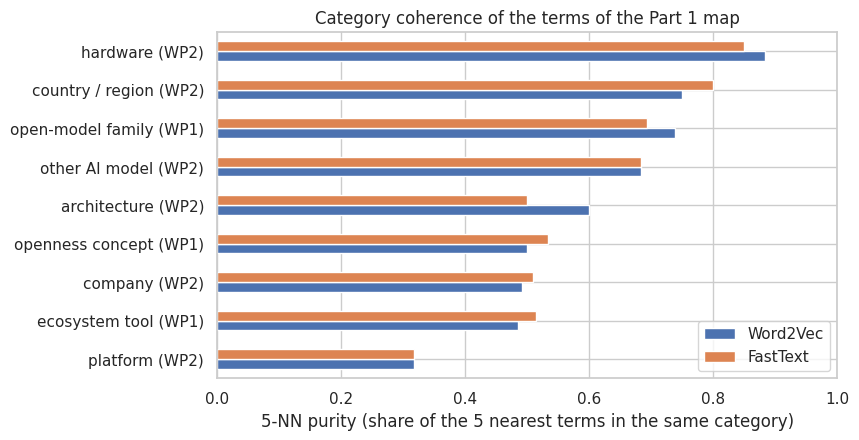

In [ ]:
terms = pd.read_csv(REPO / "artifacts/stage2_wp1/terms_tsne.csv")
terms = terms[terms["term"].isin(w2v.wv.key_to_index)].reset_index(drop=True)

def knn_purity(X, y, k=5):
    S = unit(X) @ unit(X).T
    np.fill_diagonal(S, -np.inf)
    nn = np.argsort(-S, axis=1)[:, :k]
    return (np.asarray(y)[nn] == np.asarray(y)[:, None]).mean(1)

rows, per_cat = [], {}
for model_name, kv in [("Word2Vec", w2v.wv), ("FastText", ft.wv)]:
    X = np.vstack([kv[t] for t in terms["term"]])
    pur = knn_purity(X, terms["category"])
    per_cat[model_name] = pd.Series(pur).groupby(terms["category"]).mean()
    rows.append({"model": model_name, "silhouette": silhouette_score(X, terms["category"], metric="cosine"),
                 "5-NN purity": pur.mean()})
shares = terms["category"].value_counts(normalize=True)
rows.append({"model": "random", "silhouette": 0.0, "5-NN purity": float((shares ** 2).sum())})
coherence = pd.DataFrame(rows).set_index("model")
coherence.to_csv(OUT_DIR / "intrinsic_words_categories.csv")
display(coherence.round(3))

per_cat = pd.DataFrame(per_cat).sort_values("Word2Vec")
fig, ax = plt.subplots(figsize=(8, 4.5))
per_cat.plot.barh(ax=ax, color=["#4C72B0", "#DD8452"])
ax.set(xlabel="5-NN purity (share of the 5 nearest terms in the same category)", ylabel="", xlim=(0, 1),
       title="Category coherence of the terms of the Part 1 map")
save_fig(fig, "words_category_purity")

**Interpretation**: the measures confirm the visual reading of the Part 1 map.
- The terms of AI discourse are **organised by category**: 64% (Word2Vec) and 62% (FastText) of the 5 nearest terms belong to the same category, against 15% by chance. The silhouette is positive but small (0.09 and 0.08): categories form neighbourhoods rather than separate groups.
- **Hardware** (0.88 / 0.85), **country / region** (0.75 / 0.80) and **open-model family** (0.74 / 0.69) are the most coherent categories; **platform** is the least (0.32 for both), as its terms are mixed with companies, as seen in Part 1.
- **Architecture** is more coherent in Word2Vec (0.60) than in FastText (0.50), which matches Part 1, where architecture terms formed their own zone in Word2Vec but overlapped the model families in FastText.
- Overall, **Word2Vec is the better word model for this corpus** on similarity and category structure; FastText is useful for unseen names (Part 1) and analogies.

## 3.3 Intrinsic Evaluation: Articles
The article vectors are compared with three intrinsic tasks named in the project brief:
- **Semantic similarity** (retrieval): for an article, are the most similar articles (cosine) about the same theme? Measured with the **kNN accuracy** (the majority theme of the 10 nearest articles is the article's theme) and the **mean average precision of the 10 nearest articles (MAP@10)**.
- **Clustering quality**: K-means with 5 clusters on the vectors; how well do the clusters match the themes (**NMI** and **adjusted Rand index**, mean over 10 runs)? The **silhouette** (cosine) measures how separated the themes are, without clustering.
- **Visualisation**: t-SNE maps of the same articles for every representation.

The themes are the reviewed labels of Part 2. All scores use the **206 labelled validation articles** only: the QLoRA models were trained on the themes of the training articles, so on these the comparison would be unfair. Even on validation articles, the QLoRA vectors have an advantage: they were trained to separate exactly these five themes, while all other representations never saw a theme label.

### 3.3.1 Themes of the open-models articles

In [ ]:
val = docs.index[(docs["split"] == "validation") & (docs["y"] >= 0)].to_numpy()
y_val = docs.loc[val, "y"].to_numpy()
print(f"Validation articles with a theme: {len(val)}")

def cosine_matrix(X):
    if hasattr(X, "toarray"):                      # sparse TF-IDF (already unit length)
        return (X @ X.T).toarray()
    Xu = unit(np.asarray(X, dtype=np.float32))
    return Xu @ Xu.T

def retrieval_scores(S, y, k=10):
    """Per-article kNN hit (majority theme of the k nearest) and average precision of the k nearest."""
    S = S.copy()
    np.fill_diagonal(S, -np.inf)
    nn = np.argsort(-S, axis=1)[:, :k]
    same = (y[nn] == y[:, None])
    knn_hit = np.array([np.bincount(y[row], minlength=len(LABELS)).argmax() == t for row, t in zip(nn, y)])
    prec_at = np.cumsum(same, axis=1) / np.arange(1, k + 1)
    ap = (prec_at * same).sum(1) / np.maximum(same.sum(1), 1)
    return knn_hit, ap

def boot_ci(values, n=1000):
    idx = np.random.default_rng(SEED).integers(0, len(values), (n, len(values)))
    return np.percentile(values[idx].mean(1), [2.5, 97.5])

rows, VAL_X = [], {}
for name, X in REP.items():
    Xv = X[val]
    VAL_X[name] = Xv
    S = cosine_matrix(Xv)
    knn_hit, ap = retrieval_scores(S, y_val)
    Xk = Xv if hasattr(Xv, "toarray") else unit(Xv)
    clusters = [KMeans(n_clusters=len(LABELS), n_init=10, random_state=SEED + r).fit_predict(Xk) for r in range(10)]
    lo, hi = boot_ci(knn_hit.astype(float))
    rows.append({"representation": name, "type": FAMILY[name],
                 "kNN accuracy": knn_hit.mean(), "kNN low": lo, "kNN high": hi, "MAP@10": ap.mean(),
                 "silhouette": silhouette_score(Xk, y_val, metric="cosine"),
                 "NMI": np.mean([normalized_mutual_info_score(y_val, c) for c in clusters]),
                 "ARI": np.mean([adjusted_rand_score(y_val, c) for c in clusters])})
intrinsic_docs = pd.DataFrame(rows).set_index("representation")
intrinsic_docs.to_csv(OUT_DIR / "intrinsic_articles_themes.csv")
majority = np.bincount(y_val).max() / len(y_val)
print(f"Chance level of the kNN accuracy (largest theme): {majority:.3f}")
display(intrinsic_docs.round(3))

Validation articles with a theme: 206
Chance level of the kNN accuracy (largest theme): 0.272


,type,kNN accuracy,kNN low,kNN high,MAP@10,silhouette,NMI,ARI
representation,,,,,,,,
TF-IDF,discrete,0.655,0.587,0.723,0.667,0.009,0.274,0.170
Word2Vec (mean),static word,0.636,0.573,0.704,0.689,0.040,0.317,0.212
FastText (mean),static word,0.626,0.563,0.689,0.684,0.038,0.318,0.211
Doc2Vec,document,0.646,0.578,0.714,0.693,0.036,0.338,0.255
Qwen3-1.7B frozen,"compact, frozen",0.646,0.583,0.709,0.641,0.022,0.287,0.161
Qwen3-1.7B QLoRA,"compact, QLoRA",0.762,0.699,0.820,0.722,0.167,0.495,0.438
Qwen3-4B frozen,"compact, frozen",0.660,0.592,0.723,0.642,0.032,0.309,0.201
Qwen3-4B QLoRA,"compact, QLoRA",0.762,0.699,0.820,0.760,0.102,0.484,0.346


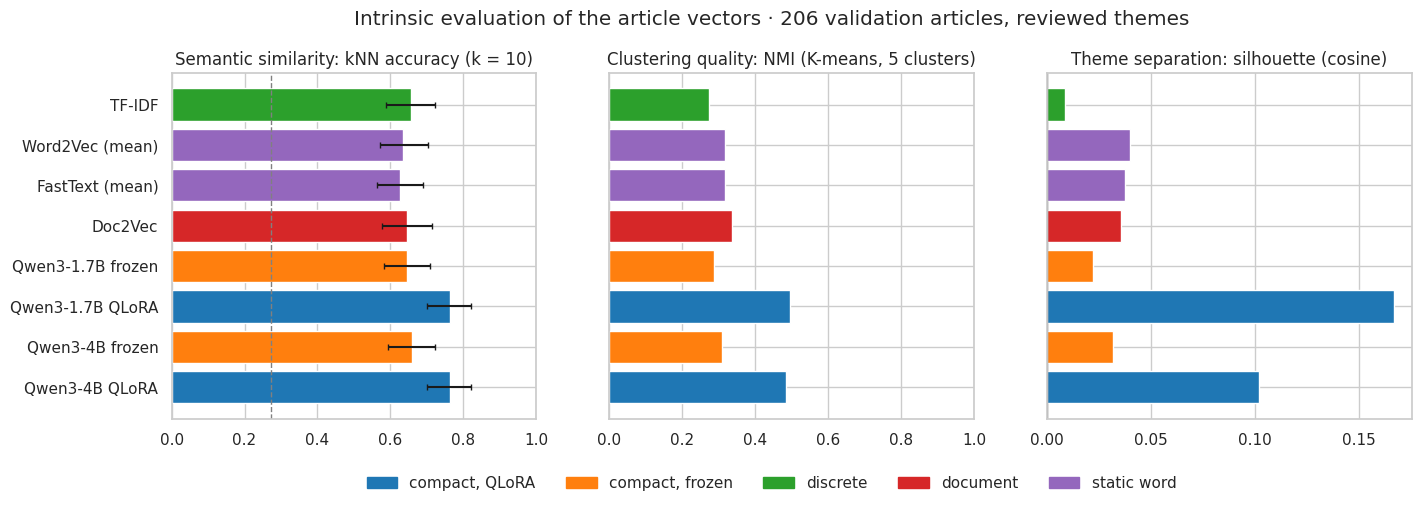

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
order = intrinsic_docs.index[::-1]
type_colors = dict(zip(sorted(set(FAMILY.values())), sns.color_palette("tab10")))
colors = intrinsic_docs.loc[order, "type"].map(type_colors)
axes[0].barh(order, intrinsic_docs.loc[order, "kNN accuracy"], color=colors,
             xerr=[intrinsic_docs.loc[order, "kNN accuracy"] - intrinsic_docs.loc[order, "kNN low"],
                   intrinsic_docs.loc[order, "kNN high"] - intrinsic_docs.loc[order, "kNN accuracy"]], capsize=2)
axes[0].axvline(majority, color="grey", ls="--", lw=1)
axes[0].set(title="Semantic similarity: kNN accuracy (k = 10)", xlim=(0, 1))
axes[1].barh(order, intrinsic_docs.loc[order, "NMI"], color=colors)
axes[1].set(title="Clustering quality: NMI (K-means, 5 clusters)", xlim=(0, 1))
axes[2].barh(order, intrinsic_docs.loc[order, "silhouette"], color=colors)
axes[2].axvline(0, color="grey", lw=1)
axes[2].set(title="Theme separation: silhouette (cosine)")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in type_colors.values()], labels=list(type_colors),
           loc="lower center", ncol=len(type_colors), bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.suptitle("Intrinsic evaluation of the article vectors · 206 validation articles, reviewed themes", y=1.02)
save_fig(fig, "intrinsic_articles")

**Interpretation**:
- **Without theme labels, all representations are close**: the kNN accuracy of the six unsupervised representations lies between 0.63 and 0.66 (chance 0.27), with overlapping intervals. TF-IDF, the mean of word vectors, Doc2Vec and the frozen compact models put articles of the same theme next to each other about equally often.
- **Pre-training on general text does not give better theme neighbourhoods**: the frozen Qwen3 models (0.65 and 0.66) are not better than the representations trained only on this corpus; their NMI (0.29 and 0.31) is even below that of Doc2Vec (0.34), the best unsupervised representation for clustering.
- **QLoRA vectors are clearly better** (kNN accuracy 0.76, NMI 0.50 and 0.48, silhouette 0.17 and 0.10), but they were trained on these five themes, so this measures what fine-tuning learned rather than an unsupervised property. Interestingly, the larger model does not separate the themes better than the smaller one.
- **The themes overlap**: the silhouette of all unsupervised representations is close to 0 (≤ 0.04). The themes are not separate groups of articles; many articles touch several of them (e.g. a model release discussed through its business impact), as the annotation rubric of Part 2 already noted.

### 3.3.2 Open-models articles within AI discourse
The second intrinsic question uses **all 8,037 articles**: are the open-models articles (core, mention, reference) close to each other and apart from the other AI articles? For every article, the share of its 10 nearest articles that are on the same side (open models or not) is measured. About half of this sample are open-models articles, so a random representation scores about 50% (printed below). No representation was trained on this distinction, so the comparison is fair for all of them. The relevance tier was defined by the keywords of the WP1 lexicon, so this test favours representations that weigh the model names.

In [ ]:
track = docs["track"].to_numpy()
sub = np.random.default_rng(SEED).choice(len(docs), size=4000, replace=False)   # 4,000 articles keep the matrices small
rows = []
for name, X in REP.items():
    S = cosine_matrix(X[sub])
    np.fill_diagonal(S, -np.inf)
    nn = np.argpartition(-S, 10, axis=1)[:, :10]
    same = (track[sub][nn] == track[sub][:, None]).mean(1)
    rows.append({"representation": name, "type": FAMILY[name],
                 "10-NN purity (all)": same.mean(),
                 "open-models articles": same[track[sub]].mean(),
                 "other articles": same[~track[sub]].mean()})
p = track[sub].mean()
track_sep = pd.DataFrame(rows).set_index("representation")
track_sep.to_csv(OUT_DIR / "intrinsic_articles_track.csv")
print(f"Share of open-models articles in the 4,000 articles: {p:.1%} | random purity: {p**2 + (1-p)**2:.3f}")
display(track_sep.round(3))

Share of open-models articles in the 4,000 articles: 51.1% | random purity: 0.500


,type,10-NN purity (all),open-models articles,other articles
representation,,,,
TF-IDF,discrete,0.672,0.802,0.536
Word2Vec (mean),static word,0.693,0.786,0.597
FastText (mean),static word,0.694,0.784,0.601
Doc2Vec,document,0.716,0.780,0.650
Qwen3-1.7B frozen,"compact, frozen",0.673,0.778,0.563
Qwen3-1.7B QLoRA,"compact, QLoRA",0.671,0.761,0.577
Qwen3-4B frozen,"compact, frozen",0.681,0.786,0.570
Qwen3-4B QLoRA,"compact, QLoRA",0.673,0.756,0.586


**Interpretation**:
- **All representations place open-models articles near each other** (10-NN purity 0.67 – 0.72, chance 0.50), but none separates them well from the rest of AI discourse: about a third of the neighbours are on the other side.
- **Doc2Vec separates the track best** (0.72), mainly because it keeps the other AI articles together (0.65 vs 0.54 – 0.60 for the others). Part 1 judged from the t-SNE map that Doc2Vec does not separate the open-models articles well; measured on all 100 dimensions, it is still the best of the eight, which shows that the t-SNE map understates the separation.
- **TF-IDF groups the open-models articles most** (0.80) but not the other articles (0.54): the open-models articles share rare words (model names, *open-weight*), as expected for tiers defined by keywords.
- **Fine-tuning does not help here**: the QLoRA vectors (0.67) are slightly below the frozen models (0.67 – 0.68). They were trained to separate themes **within** the track, so a China article with or without open models, for example, moves closer to the `china_geopolitics` articles.

### 3.3.3 Visualisation
The 206 validation articles are projected with t-SNE (cosine) for every representation, with the same settings and seed. The colours are the reviewed themes. As in Part 1, the distances between groups on a t-SNE map are not meaningful, only the neighbourhoods.

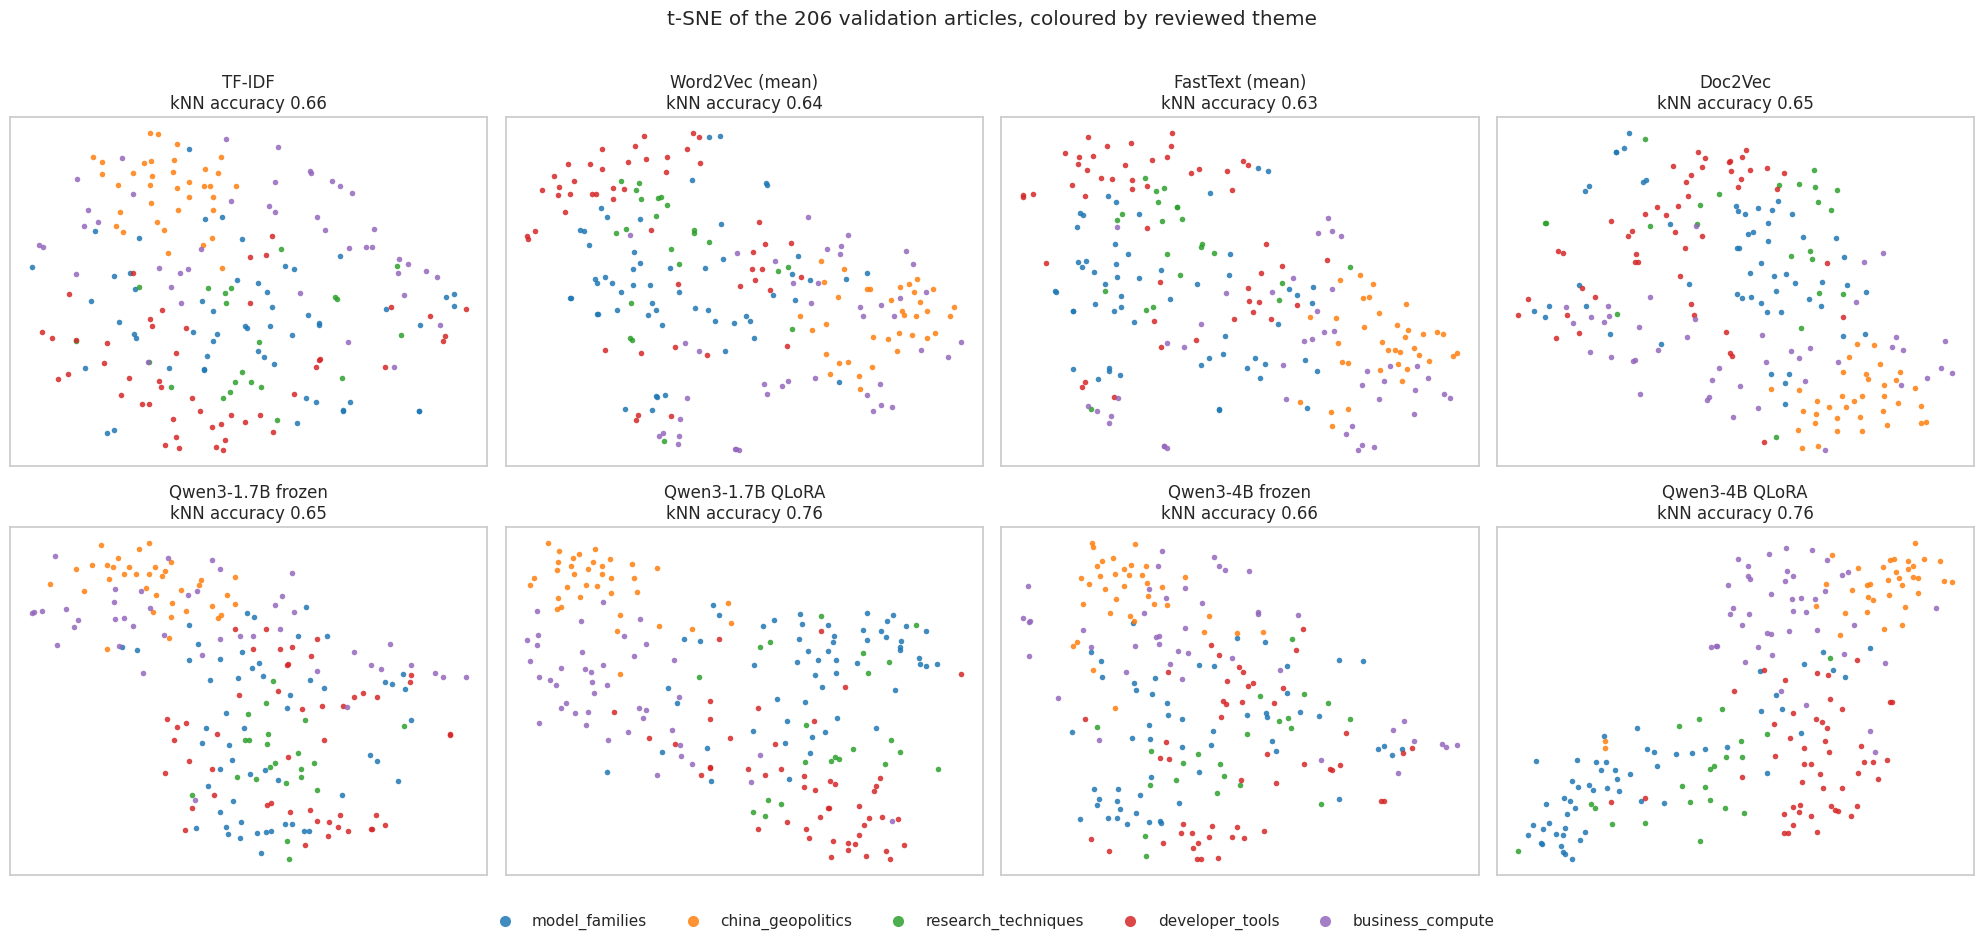

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
palette = dict(zip(LABELS, sns.color_palette("tab10", len(LABELS))))
theme_names = np.array(LABELS)[y_val]
for ax, (name, Xv) in zip(axes.ravel(), VAL_X.items()):
    Xd = Xv.toarray() if hasattr(Xv, "toarray") else Xv
    xy = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca", random_state=SEED).fit_transform(unit(Xd))
    for theme in LABELS:
        m = theme_names == theme
        ax.scatter(xy[m, 0], xy[m, 1], s=16, color=palette[theme], label=theme, alpha=0.85, linewidths=0)
    ax.set(title=f"{name}\nkNN accuracy {intrinsic_docs.loc[name, 'kNN accuracy']:.2f}", xticks=[], yticks=[])
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=5, fontsize=11, frameon=False, markerscale=2)
fig.suptitle("t-SNE of the 206 validation articles, coloured by reviewed theme")
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
save_fig(fig, "tsne_validation_themes")

**Interpretation**:
- In all maps, **`china_geopolitics` forms the clearest zone** (orange), followed by `business_compute` (purple): both themes have a distinctive vocabulary (China, export controls; stocks, revenue, chips).
- `model_families`, `research_techniques` and `developer_tools` are **mixed in the classical and frozen maps**: a model release, a training technique and a tool are reported with similar words.
- The **QLoRA maps** show two large regions, `china_geopolitics` + `business_compute` on one side and `model_families` + `research_techniques` + `developer_tools` on the other, with clearer zones for each theme inside them. `research_techniques` (green) remains spread in all maps: it is the smallest theme and the hardest to classify (Part 2, Section 2.6.2).

## 3.4 Extrinsic Evaluation: Theme Classification
The extrinsic task is the theme classification of Part 2 (Section 2.2): five themes of the open-models discourse, reviewed labels, 848 training articles and 206 validation articles. Part 2 compared Doc2Vec with the compact models; the representations it did not test are added here **with exactly the same protocol** (Section 2.5): article vectors scaled to unit length, a logistic regression with balanced class weights, trained on train + dev and evaluated on validation, macro-F1 with a 95% bootstrap interval, and the score on the 98 articles labelled by hand without the LLM.

The protocol is checked first: Doc2Vec + logistic regression, recomputed here from the Part 1 vectors, must give the macro-F1 of Part 2 (0.749).

In [ ]:
fit = docs.index[(docs["split"] == "train") & (docs["y"] >= 0)].to_numpy()
y_fit = docs.loc[fit, "y"].to_numpy()
hand = (docs.loc[val, "label_source"] == "human").to_numpy()

def linear_probe(X_fit, y, X_eval):
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    if hasattr(X_fit, "toarray"):
        clf.fit(X_fit, y)
        return clf.predict(X_eval)
    clf.fit(unit(X_fit), y)
    return clf.predict(unit(X_eval))

def f1_ci(y_true, y_pred, n=1000):
    idx = np.random.default_rng(SEED).integers(0, len(y_true), (n, len(y_true)))
    return np.percentile([f1_score(y_true[i], y_pred[i], average="macro") for i in idx], [2.5, 97.5])

PRED = {}
rows = []
for name in ["TF-IDF", "Word2Vec (mean)", "FastText (mean)", "Doc2Vec"]:
    X = REP[name]
    pred = linear_probe(X[fit], y_fit, X[val])
    PRED[name] = pred
    lo, hi = f1_ci(y_val, pred)
    rows.append({"method": f"{name} + LogReg", "representation": name, "type": FAMILY[name],
                 "accuracy": accuracy_score(y_val, pred), "macro_f1": f1_score(y_val, pred, average="macro"),
                 "f1_low": lo, "f1_high": hi,
                 "macro_f1_hand": f1_score(y_val[hand], pred[hand], average="macro"), "source": "Part 3"})
new = pd.DataFrame(rows)
check = new.loc[new["representation"] == "Doc2Vec", "macro_f1"].item()
print(f"Doc2Vec + LogReg recomputed: {check:.3f} (Part 2: 0.749) -> protocol reproduced: {abs(check - 0.749) < 0.002}")

Doc2Vec + LogReg recomputed: 0.749 (Part 2: 0.749) -> protocol reproduced: True


,type,accuracy,macro_f1,f1_low,f1_high,macro_f1_hand,source
method,,,,,,,
Qwen3-4B QLoRA,"compact, QLoRA",0.850,0.843,0.786,0.891,0.788,Part 2
Qwen3-1.7B QLoRA,"compact, QLoRA",0.816,0.804,0.746,0.855,0.796,Part 2
TF-IDF + LogReg,discrete,0.806,0.796,0.733,0.851,0.754,Part 3
Qwen3-4B frozen + LogReg,"compact, frozen",0.748,0.752,0.691,0.805,0.754,Part 2
Doc2Vec + LogReg,document,0.757,0.749,0.683,0.805,0.740,Part 3
Qwen3-1.7B frozen + LogReg,"compact, frozen",0.733,0.738,0.677,0.792,0.713,Part 2
FastText (mean) + LogReg,static word,0.738,0.727,0.660,0.785,0.743,Part 3
Word2Vec (mean) + LogReg,static word,0.738,0.725,0.659,0.782,0.729,Part 3


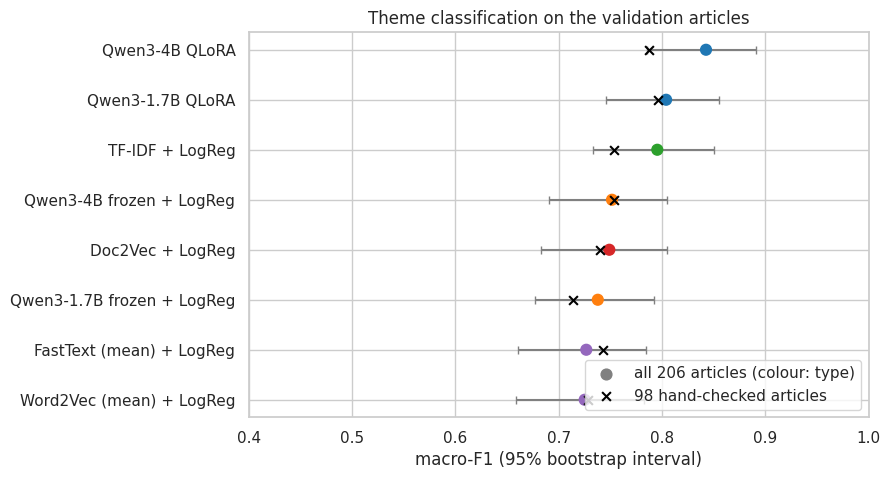

In [ ]:
# Scores of Part 2 (same validation articles, same protocol)
wp2 = pd.read_csv(WP2_RUN / "results_validation.csv")
wp2_hand = pd.read_csv(WP2_RUN / "results_robustness.csv", index_col=0)
wp2 = wp2[~wp2["method"].str.startswith("Doc2Vec")].copy()
wp2["representation"] = (wp2["method"].str.replace(" + LogReg", "", regex=False).str.replace("qwen3-", "Qwen3-")
                         .str.replace("1.7b", "1.7B").str.replace("4b", "4B"))
wp2["macro_f1_hand"] = wp2["method"].map(wp2_hand.filter(like="hand-checked").iloc[:, 0])   # Part 2 method names
wp2["method"] = np.where(wp2["representation"].str.contains("frozen"), wp2["representation"] + " + LogReg", wp2["representation"])
wp2["type"] = wp2["representation"].map(FAMILY)
wp2["source"] = "Part 2"
extrinsic = pd.concat([new, wp2[new.columns]], ignore_index=True).sort_values("macro_f1", ascending=False)
extrinsic.to_csv(OUT_DIR / "extrinsic_theme_classification.csv", index=False)
display(extrinsic.set_index("method").drop(columns=["representation"]).round(3))

fig, ax = plt.subplots(figsize=(8, 5))
e = extrinsic.iloc[::-1]
ax.errorbar(e["macro_f1"], range(len(e)), xerr=[e["macro_f1"] - e["f1_low"], e["f1_high"] - e["macro_f1"]],
            fmt="none", ecolor="grey", capsize=3)
ax.scatter(e["macro_f1"], range(len(e)), c=e["type"].map(type_colors), s=60, zorder=3)
ax.scatter([], [], color="grey", s=60, label="all 206 articles (colour: type)")
ax.scatter(e["macro_f1_hand"], range(len(e)), marker="x", color="black", s=40, zorder=3, label="98 hand-checked articles")
ax.set(yticks=range(len(e)), yticklabels=e["method"], xlabel="macro-F1 (95% bootstrap interval)", xlim=(0.4, 1),
       title="Theme classification on the validation articles")
ax.legend(loc="lower right")
save_fig(fig, "extrinsic_theme_classification")

**Is the best compact model better than the best classical representation?** The predictions of Qwen3-4B QLoRA for the validation articles are taken from the theme predictions that Part 2 saved for all open-models articles (`predictions_track_qwen3-4b.parquet`); their macro-F1 must equal the Part 2 score (0.843). The predictions of Qwen3-1.7B QLoRA, the compact model recommended by Part 2, are taken from the validation predictions that Part 2 saved (`predictions_validation.parquet`); their macro-F1 must equal 0.804. The difference to the best classical representation is tested with the paired bootstrap of Section 2.6.3 (same resampled articles for both methods; `p` = share of resamples where the compact model is not better).

In [ ]:
preds_track = pd.read_parquet(WP2_RUN / "predictions_track_qwen3-4b.parquet")
pmap = dict(zip(preds_track["doc_id"], preds_track["pred"].map(LABEL_ID)))
PRED["Qwen3-4B QLoRA"] = docs.loc[val, "doc_id"].map(pmap).to_numpy()
print(f"Qwen3-4B QLoRA from the saved predictions: macro-F1 {f1_score(y_val, PRED['Qwen3-4B QLoRA'], average='macro'):.3f}")
preds_val = pd.read_parquet(WP2_RUN / "predictions_validation.parquet").set_index("doc_id")
PRED["Qwen3-1.7B QLoRA"] = docs.loc[val, "doc_id"].map(preds_val["qwen3-1.7b QLoRA"].map(LABEL_ID)).to_numpy()
print(f"Qwen3-1.7B QLoRA from the saved predictions: macro-F1 {f1_score(y_val, PRED['Qwen3-1.7B QLoRA'], average='macro'):.3f}")

def paired(a, b, mask, n=1000):
    yt, pa, pb = y_val[mask], PRED[a][mask], PRED[b][mask]
    idx = np.random.default_rng(SEED).integers(0, len(yt), (n, len(yt)))
    d = np.array([f1_score(yt[i], pa[i], average="macro") - f1_score(yt[i], pb[i], average="macro") for i in idx])
    return {"difference": f1_score(yt, pa, average="macro") - f1_score(yt, pb, average="macro"),
            "low": np.percentile(d, 2.5), "high": np.percentile(d, 97.5), "p": (d <= 0).mean()}

best_classical = new.sort_values("macro_f1").iloc[-1]["representation"]
paired_rows = [{"comparison": f"{model} vs {best_classical}", "labels": lab, **paired(model, best_classical, m)}
               for model in ["Qwen3-4B QLoRA", "Qwen3-1.7B QLoRA"]
               for lab, m in [("all", np.ones(len(val), bool)), ("hand-checked", hand)]]
paired_rows += [{"comparison": f"{best_classical} vs Doc2Vec", "labels": lab, **paired(best_classical, "Doc2Vec", m)}
                for lab, m in [("all", np.ones(len(val), bool)), ("hand-checked", hand)]] if best_classical != "Doc2Vec" else []
paired_ext = pd.DataFrame(paired_rows)
paired_ext.to_csv(OUT_DIR / "extrinsic_paired.csv", index=False)
display(paired_ext.round(3))

print(f"\nPer-theme F1 of {best_classical} and Qwen3-4B QLoRA:")
display(pd.DataFrame({m: f1_score(y_val, PRED[m], average=None) for m in [best_classical, "Qwen3-4B QLoRA"]},
                     index=LABELS).round(3))

Qwen3-4B QLoRA from the saved predictions: macro-F1 0.843
Qwen3-1.7B QLoRA from the saved predictions: macro-F1 0.804


,comparison,labels,difference,low,high,p
0,Qwen3-4B QLoRA vs TF-IDF,all,0.047,-0.013,0.114,0.062
1,Qwen3-4B QLoRA vs TF-IDF,hand-checked,0.034,-0.064,0.139,0.273
2,Qwen3-1.7B QLoRA vs TF-IDF,all,0.009,-0.056,0.076,0.375
3,Qwen3-1.7B QLoRA vs TF-IDF,hand-checked,0.043,-0.066,0.153,0.216
4,TF-IDF vs Doc2Vec,all,0.046,0.011,0.083,0.006
5,TF-IDF vs Doc2Vec,hand-checked,0.014,-0.035,0.065,0.285



Per-theme F1 of TF-IDF and Qwen3-4B QLoRA:


,TF-IDF,Qwen3-4B QLoRA
model_families,0.793,0.860
china_geopolitics,0.854,0.901
research_techniques,0.718,0.778
developer_tools,0.857,0.848
business_compute,0.756,0.826


**Interpretation**:
- **TF-IDF is the strongest classical representation** (macro-F1 0.80) and is better than Doc2Vec (+4.6 points, p = 0.006), the mean of word vectors (0.73) and both frozen compact models (0.74 – 0.75). The themes are largely defined by vocabulary (*China*, *export*, *GPU*, *API*, *benchmark*), which a sparse vector keeps word by word, while averaging word vectors blurs it.
- **Qwen3-4B QLoRA is still the best** (0.84) and better than TF-IDF on four of the five themes (largest gains on `business_compute` and `model_families`, +7 points each). The difference to TF-IDF (+4.7 points) is **not significant** (p = 0.06), and on the 98 hand-checked articles it shrinks to +3.4 (p = 0.27).
- **The recommended Qwen3-1.7B QLoRA is level with TF-IDF** (0.804 vs 0.796): the difference is not significant, on all articles (+0.9 points, p = 0.38) nor on the hand-checked ones (+4.3 points, p = 0.22).
- **The conclusion of Part 2 needs nuance**: fine-tuning clearly improves on the frozen models and Doc2Vec, but a well-chosen discrete baseline captures most of what the task needs.
- The scores on the hand-checked articles keep the same order, except that Qwen3-1.7B QLoRA (0.80) is slightly above Qwen3-4B QLoRA (0.79), as in Part 2.

## 3.5 Trade-offs: Size, Performance, Training Speed and GPU Requirements
Part 2 logged the time and peak GPU memory of every step of the compact models (`resources.json`). Part 1 did not log the training time of the classical models, so it is measured here: Word2Vec, FastText and Doc2Vec are trained again **with the settings of Part 1** (read from the Part 1 notebook) on a fixed random 10% of the training articles, on the CPU, and the time is scaled to the full training split (training time grows linearly with the number of tokens). TF-IDF is timed the same way. The inference time (vectors for 1,000 articles) is measured on the validation articles.

The times come from different machines: the compact models ran on an NVIDIA L4 GPU (Colab), the classical models on the CPU of the machine that runs this notebook (printed below). They are comparable in order of magnitude, not to the second.

In [ ]:
import platform
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

# Settings of Part 1 (Sections 1.2.1 - 1.2.3), read from its notebook
for marker in ("EMB = dict(", "FT_NGRAMS = dict(", "D2V = dict("):
    line = next(l for c in wp1_nb["cells"] if c["cell_type"] == "code" for l in "".join(c["source"]).splitlines()
                if l.startswith(marker))
    exec(line)
print("Word2Vec / FastText:", EMB, FT_NGRAMS, "\nDoc2Vec:", D2V)
CPU = f"{platform.processor() or platform.machine()} · {os.cpu_count()} cores"
print("CPU:", CPU)

TIMING_PATH = OUT_DIR / "timing_classical.json"
train_ids = corpus.loc[corpus["split"] == "train", "doc_id"]
if TIMING_PATH.exists():
    timing = json.loads(TIMING_PATH.read_text())
else:
    sample_ids = set(train_ids.sample(frac=0.10, random_state=SEED))
    sample_texts = corpus.loc[corpus["doc_id"].isin(sample_ids), "text"]
    t0 = time.perf_counter()
    sample_docs = [doc_sentences(normalise(t)) for t in sample_texts]
    t_tok = time.perf_counter() - t0
    sentences = [s for d in sample_docs for s in d]
    tagged = [TaggedDocument([t for s in d for t in s], [i]) for i, d in enumerate(sample_docs)]
    n_tok = sum(len(s) for s in sentences)
    timing = {"cpu": CPU, "sample_articles": len(sample_docs), "sample_tokens": n_tok, "tokenise_s": t_tok}
    workers = os.cpu_count()
    for name, build in [("Word2Vec", lambda: Word2Vec(sentences, seed=SEED, workers=workers, **EMB)),
                        ("FastText", lambda: FastText(sentences, seed=SEED, workers=workers, **EMB, **FT_NGRAMS)),
                        ("Doc2Vec", lambda: Doc2Vec(tagged, seed=SEED, workers=workers, **D2V))]:
        t0 = time.perf_counter()
        model = build()
        timing[f"{name}_train_s"] = time.perf_counter() - t0
        if name == "Doc2Vec":
            d2v_small = model
    t0 = time.perf_counter()
    TfidfVectorizer(analyzer=lambda toks: toks, min_df=5, max_df=0.5, sublinear_tf=True).fit([d.words for d in tagged])
    timing["TF-IDF_train_s"] = time.perf_counter() - t0

    # Inference: vectors of 200 validation articles (tokenisation included)
    val_texts = docs.loc[val[:200], "text"].tolist()
    t0 = time.perf_counter(); toks = [tokens_of(t) for t in val_texts]; t_tok_val = time.perf_counter() - t0
    for name, infer in [("TF-IDF", lambda: tfidf.transform(toks)),
                        ("Word2Vec (mean)", lambda: mean_vectors(w2v.wv, toks, oov_vectors=False)),
                        ("FastText (mean)", lambda: mean_vectors(ft.wv, toks, oov_vectors=True)),
                        ("Doc2Vec", lambda: [d2v_small.infer_vector(t, epochs=D2V["epochs"]) for t in toks])]:
        t0 = time.perf_counter(); infer()
        timing[f"{name}_infer_per_1000_s"] = (time.perf_counter() - t0 + t_tok_val) / len(val_texts) * 1000
    TIMING_PATH.write_text(json.dumps(timing, indent=2))
scale = 1 / 0.10
print(f"Timing sample: {timing['sample_articles']:,} training articles, {timing['sample_tokens'] / 1e6:.1f} M tokens "
      f"(full training split ≈ {timing['sample_tokens'] * scale / 1e6:.0f} M tokens)")

Word2Vec / FastText: {'vector_size': 100, 'window': 5, 'min_count': 10, 'sample': 0.0001, 'negative': 5, 'epochs': 5, 'sg': 1} {'min_n': 3, 'max_n': 5, 'bucket': 500000} 
Doc2Vec: {'vector_size': 100, 'min_count': 10, 'sample': 0.0001, 'negative': 5, 'epochs': 10, 'dm': 0}
CPU: x86_64 · 12 cores
Timing sample: 3,637 training articles, 5.3 M tokens (full training split ≈ 53 M tokens)


In [ ]:
res = json.loads((WP2_RUN / "resources.json").read_text())         # fine-tuning run (reviewed labels), NVIDIA L4
res_base = json.loads((WP2_DIR / "resources.json").read_text())     # frozen-model embeddings
V_w2v, V_ft, dim = len(w2v.wv), len(ft.wv), w2v.vector_size
n_train_docs = len(train_ids)
F1 = extrinsic.set_index("representation")["macro_f1"]
F1_hand = extrinsic.set_index("representation")["macro_f1_hand"]

rows = [
    {"representation": "TF-IDF", "parameters": len(tfidf.vocabulary_) * len(LABELS),
     "what is stored": "vocabulary and IDF; classifier weights",
     "train_min": timing["TF-IDF_train_s"] * scale / 60, "train_hw": f"CPU ({os.cpu_count()} cores)",
     "peak_gpu_gb": 0.0, "infer_s_per_1000": timing["TF-IDF_infer_per_1000_s"], "infer_hw": "CPU"},
    {"representation": "Word2Vec (mean)", "parameters": 2 * V_w2v * dim, "what is stored": "input and output word vectors",
     "train_min": timing["Word2Vec_train_s"] * scale / 60, "train_hw": f"CPU ({os.cpu_count()} cores)",
     "peak_gpu_gb": 0.0, "infer_s_per_1000": timing["Word2Vec (mean)_infer_per_1000_s"], "infer_hw": "CPU"},
    {"representation": "FastText (mean)", "parameters": (2 * V_ft + ft.wv.bucket) * dim,
     "what is stored": "word vectors, n-gram buckets, output vectors",
     "train_min": timing["FastText_train_s"] * scale / 60, "train_hw": f"CPU ({os.cpu_count()} cores)",
     "peak_gpu_gb": 0.0, "infer_s_per_1000": timing["FastText (mean)_infer_per_1000_s"], "infer_hw": "CPU"},
    {"representation": "Doc2Vec", "parameters": (n_train_docs + 2 * V_w2v) * dim,
     "what is stored": "article vectors, word and output vectors",
     "train_min": timing["Doc2Vec_train_s"] * scale / 60, "train_hw": f"CPU ({os.cpu_count()} cores)",
     "peak_gpu_gb": 0.0, "infer_s_per_1000": timing["Doc2Vec_infer_per_1000_s"], "infer_hw": "CPU"},
]
N_PRED = 212   # validation articles predicted in Part 2 (incl. the 6 labelled none)
for size in ["1.7b", "4b"]:
    r, rb = res[f"qwen3-{size}"], res_base[f"qwen3-{size}"]
    name = f"Qwen3-{size.upper()}"
    rows.append({"representation": f"{name} frozen", "parameters": r["total_params"],
                 "what is stored": "pre-trained weights (4-bit); classifier weights", "train_min": 0.0,
                 "train_hw": "no training (embeddings only)", "peak_gpu_gb": rb["embed_base_val"]["peak_vram_gb"],
                 "infer_s_per_1000": rb["embed_base_val"]["seconds"] / N_PRED * 1000, "infer_hw": rb["embed_base_val"]["gpu"]})
    rows.append({"representation": f"{name} QLoRA", "parameters": r["total_params"],
                 "trainable": r["trainable_params"], "adapter_mb": r["adapter_mb"],
                 "what is stored": f"pre-trained weights (4-bit) + LoRA adapter ({r['adapter_mb']} MB)",
                 "train_min": r["finetune"]["seconds"] / 60, "train_hw": r["finetune"]["gpu"],
                 "peak_gpu_gb": r["finetune"]["peak_vram_gb"],
                 "infer_s_per_1000": r["predict_validation"]["seconds"] / N_PRED * 1000, "infer_hw": r["predict_validation"]["gpu"]})
tradeoffs = pd.DataFrame(rows)
tradeoffs["trainable"] = tradeoffs["trainable"].fillna(tradeoffs["parameters"]).astype(float)
tradeoffs.loc[tradeoffs["representation"].str.contains("frozen"), "trainable"] = 0.0   # only the linear classifier is trained
tradeoffs["macro_f1"] = tradeoffs["representation"].map(F1)
tradeoffs["macro_f1_hand"] = tradeoffs["representation"].map(F1_hand)
tradeoffs.to_csv(OUT_DIR / "tradeoffs.csv", index=False)
show = tradeoffs.assign(parameters=(tradeoffs["parameters"] / 1e6).round(1), trainable=(tradeoffs["trainable"] / 1e6).round(1))
display(show[["representation", "parameters", "trainable", "train_min", "train_hw", "peak_gpu_gb",
              "infer_s_per_1000", "infer_hw", "macro_f1", "macro_f1_hand"]]
        .rename(columns={"parameters": "parameters (M)", "trainable": "trained (M)", "train_min": "training (min)",
                         "peak_gpu_gb": "peak GPU memory (GB)", "infer_s_per_1000": "s per 1,000 articles"})
        .set_index("representation").round(2))

,parameters (M),trained (M),training (min),train_hw,peak GPU memory (GB),"s per 1,000 articles",infer_hw,macro_f1,macro_f1_hand
representation,,,,,,,,,
TF-IDF,0.1,0.1,0.55,CPU (12 cores),0.00,13.04,CPU,0.80,0.75
Word2Vec (mean),12.6,12.6,14.83,CPU (12 cores),0.00,13.17,CPU,0.73,0.73
FastText (mean),62.6,62.6,29.08,CPU (12 cores),0.00,13.95,CPU,0.73,0.74
Doc2Vec,16.2,16.2,7.66,CPU (12 cores),0.00,24.75,CPU,0.75,0.74
Qwen3-1.7B frozen,1727.0,0.0,0.00,no training (embeddings only),2.63,681.13,Tesla T4,0.74,0.71
Qwen3-1.7B QLoRA,1727.0,6.4,9.01,NVIDIA L4,2.82,66.51,NVIDIA L4,0.80,0.80
Qwen3-4B frozen,4034.3,0.0,0.00,no training (embeddings only),5.56,112.26,NVIDIA L4,0.75,0.75
Qwen3-4B QLoRA,4034.3,11.8,21.16,NVIDIA L4,4.80,135.85,NVIDIA L4,0.84,0.79


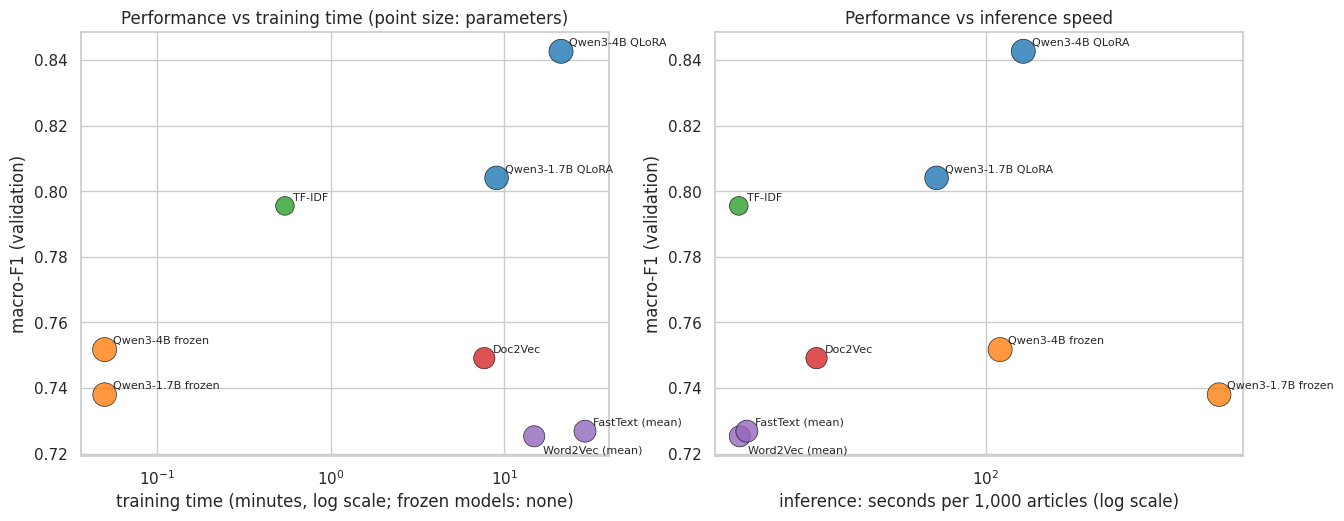

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
t = tradeoffs.copy()
t["train_plot"] = t["train_min"].clip(lower=0.05)             # frozen models: no training, shown at the left edge
for ax, xcol, xlabel in [(axes[0], "train_plot", "training time (minutes, log scale; frozen models: none)"),
                         (axes[1], "infer_s_per_1000", "inference: seconds per 1,000 articles (log scale)")]:
    ax.scatter(t[xcol], t["macro_f1"], s=40 + 260 * np.log10(t["parameters"]) / np.log10(t["parameters"].max()),
               c=t["representation"].map(FAMILY).map(type_colors), alpha=0.8, edgecolors="black", linewidths=0.5)
    for _, r in t.iterrows():
        below = r["representation"] == "Word2Vec (mean)"          # Word2Vec and FastText are close: one label below
        ax.annotate(r["representation"], (r[xcol], r["macro_f1"]), textcoords="offset points",
                    xytext=(6, -12 if below else 4), fontsize=8)
    ax.set(xscale="log", xlabel=xlabel, ylabel="macro-F1 (validation)")
axes[0].set_title("Performance vs training time (point size: parameters)")
axes[1].set_title("Performance vs inference speed")
save_fig(fig, "tradeoffs")

**Interpretation**:
- **Size**: the compact models have about 30 to 27,000 times more parameters than the classical representations (1.7 – 4.0 billion vs 0.15 – 63 million), but QLoRA trains only 0.3 – 0.4% of them (6.4 and 11.8 million), the same order as Word2Vec or Doc2Vec.
- **Training time**: training the classical representations on the full training split takes 8 (Doc2Vec) to 29 minutes (FastText) on the 2 CPU cores of Colab, fine-tuning 9 (Qwen3-1.7B) or 21 minutes (Qwen3-4B) on an L4 GPU. Measured this way, training a classical model from scratch costs as much time as adapting a compact model with QLoRA; the difference is the hardware. The pre-training of the compact models is not counted (it was done by the model provider), while the classical models are trained from scratch.
- **Inference and GPU**: the classical representations need no GPU and process 1,000 articles in 13 – 25 seconds (tokenisation included); the QLoRA models need a GPU with 2.8 or 4.8 GB of memory and 67 or 133 seconds. (The frozen Qwen3-1.7B was run on a slower T4 GPU, so its inference time is not comparable.)
- **Performance per cost**: TF-IDF reaches 94% of the best macro-F1 with about half a minute of training on a CPU. Among the compact models, Qwen3-4B gains 4 points over Qwen3-1.7B on all validation articles but none on the hand-checked ones, for 2.3× the training time, 2× the inference time and 1.7× the GPU memory: **Qwen3-1.7B QLoRA is the better compromise**, as recommended in Part 2.

## 3.6 Insight Extraction
The best representations are now used to analyse the discourse, at two levels:
1. **AI discourse in the whole corpus** (Section 3.6.1): only Doc2Vec has a vector for all 45,462 articles (the compact models were run on 8,037 articles to save GPU time). Its article vectors are clustered into discourse groups, which are followed over time and located relative to the open-models track.
2. **The open-models track** (Sections 3.6.2 – 3.6.4): the best fine-tuned model (Qwen3-4B QLoRA, macro-F1 0.84) assigned a theme to all 4,037 core and mention articles in Part 2. Its predictions are analysed over time, by developer region and by model family.

### 3.6.1 AI discourse in the whole corpus (Doc2Vec)
The Doc2Vec vectors of all articles are clustered with K-means. The number of clusters is chosen among 8 to 16 by the silhouette on a sample of 5,000 articles. Each cluster is described by its most distinctive title words (class-based TF-IDF: words frequent in the titles of the cluster and rare in the other clusters). The clusters are numbered by their share of open-models articles (C00 has the highest share).

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

all_vec = unit(np.vstack(doc_vectors["vector"].to_numpy()).astype(np.float32))
disc = doc_vectors[["doc_id"]].merge(corpus[["doc_id", "quarter", "title", "om_tier", "track"]], on="doc_id")
probe = np.random.default_rng(SEED).choice(len(all_vec), 5000, replace=False)
k_scores = {k: silhouette_score(all_vec[probe], KMeans(k, n_init=5, random_state=SEED).fit_predict(all_vec[probe]),
                                metric="cosine") for k in range(8, 17, 2)}
K = max(k_scores, key=k_scores.get)
print("Silhouette by number of clusters:", {k: round(float(v), 3) for k, v in k_scores.items()}, "-> K =", K)
disc["cluster"] = KMeans(K, n_init=10, random_state=SEED).fit_predict(all_vec)
share = disc.groupby("cluster")["track"].mean().sort_values(ascending=False)
disc["cluster"] = disc["cluster"].map({old: new for new, old in enumerate(share.index)})   # C00 = most open-models articles

# Distinctive title words per cluster (class-based TF-IDF)
cv = CountVectorizer(stop_words="english", min_df=5, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9\-]+\b")
counts = cv.fit_transform(disc.groupby("cluster")["title"].apply(lambda s: " ".join(s.fillna(""))))
tf = normalize(counts, norm="l1", axis=1).toarray()
idf = np.log(K / (counts.toarray() > 0).sum(0))      # 0 for words found in the titles of every cluster
words = np.array(cv.get_feature_names_out())
top_words = {c: ", ".join(words[np.argsort(-(tf[c] * idf))[:7]]) for c in range(K)}

summary = (disc.groupby("cluster").agg(articles=("doc_id", "size"), track_share=("track", "mean"),
                                       core=("om_tier", lambda s: (s == "core").sum()))
           .assign(top_title_words=pd.Series(top_words)))
q_share = pd.crosstab(disc["cluster"], disc["quarter"], normalize="columns")
x = np.arange(q_share.shape[1])
summary["trend_pp_per_year"] = [np.polyfit(x, q_share.loc[c].to_numpy() * 100, 1)[0] * 4 for c in q_share.index]
summary = summary.sort_values("track_share", ascending=False)
summary.to_csv(OUT_DIR / "discourse_clusters.csv")
display(summary.round(3))

Silhouette by number of clusters: {8: 0.062, 10: 0.063, 12: 0.066, 14: 0.067, 16: 0.068} -> K = 16


,articles,track_share,core,top_title_words,trend_pp_per_year
cluster,,,,,
0,2770,0.382,511,"hugging, rag, llms, reasoning, fine-tuning, annotation, transformer",-3.985
1,3138,0.180,149,"hat, coolest, cisco, hpe, servicenow, workloads, hottest",-1.960
2,3105,0.147,173,"trump, ukraine, regulation, war, russia, iran, trade",-1.040
3,3540,0.124,101,"reilly, mcp, coding, cursor, code, github, b2b",8.483
4,2764,0.101,74,"nasdaq, earnings, stocks, shares, q1, holdings, q4",1.114
5,2480,0.089,72,"azure, mcp, foundry, kafka, api, devops, sql",1.788
6,1543,0.068,14,"quantum, hpc, supercomputer, computers, computing, researchers, prize",-1.180
7,3055,0.063,19,"film, books, art, humanity, kids, women, schools",-0.241
8,1774,0.053,14,"samsung, ios, pixel, iphone, ces, macos, apk",0.381


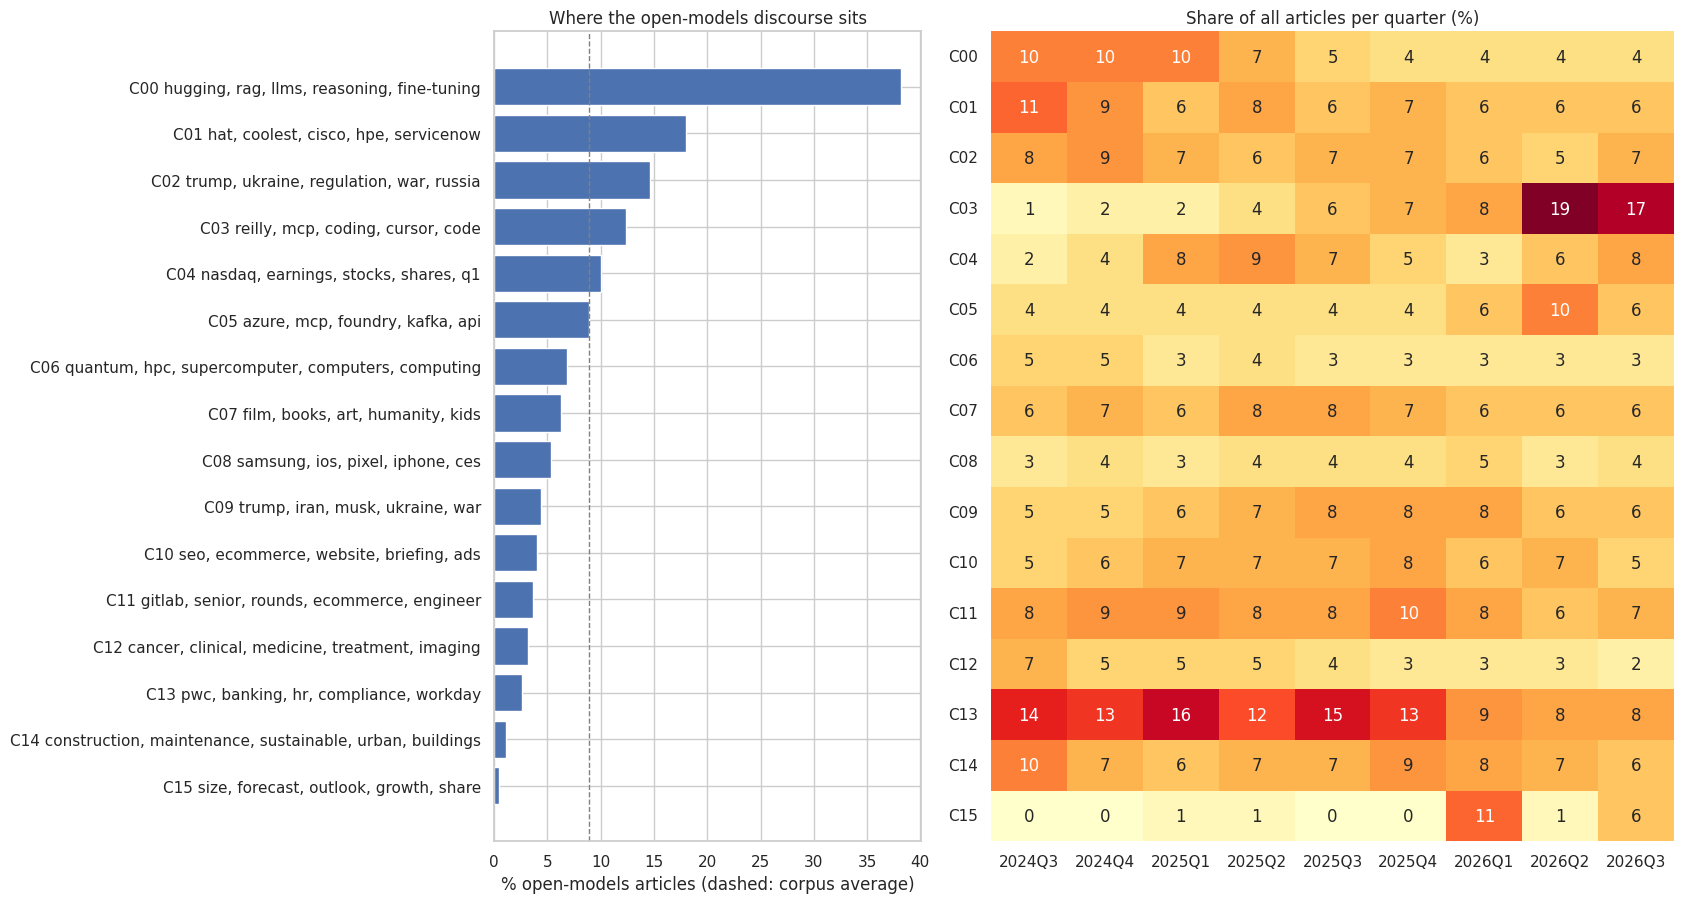

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 0.45 * K + 2), gridspec_kw={"width_ratios": [1, 1.6]})
lab = [f"C{c:02d} {', '.join(top_words[c].split(', ')[:5])}" for c in summary.index]
axes[0].barh(lab[::-1], summary["track_share"][::-1] * 100, color="#4C72B0")
axes[0].axvline(disc["track"].mean() * 100, color="grey", ls="--", lw=1)
axes[0].set(xlabel="% open-models articles (dashed: corpus average)", title="Where the open-models discourse sits")
sns.heatmap((q_share.loc[summary.index] * 100).round(0), annot=True, fmt=".0f", cmap="YlOrRd", cbar=False,
            yticklabels=[f"C{c:02d}" for c in summary.index], ax=axes[1])
axes[1].set(xlabel="", ylabel="", title="Share of all articles per quarter (%)")
axes[1].tick_params(axis="y", rotation=0)
fig.tight_layout()
save_fig(fig, "discourse_clusters")

**Interpretation**: the silhouette is low for every number of clusters (0.06 – 0.07), so the clusters are regions of a continuous discourse rather than separate groups; K = 16 is used to describe it.
- **The open-models discourse sits in four clusters**: **C00**, the technical discourse about LLMs (*Hugging Face*, *RAG*, *reasoning*, *fine-tuning*: 38% open-models articles and 511 core articles, 42% of all core articles); **C01**, enterprise infrastructure (*Red Hat*, *Cisco*, *HPE*, *ServiceNow*: 18%); **C02**, politics, regulation and geopolitics (*Trump*, *regulation*, *trade*, *Ukraine*: 15%); and **C03**, agents and coding tools (*MCP*, *Cursor*, *GitHub*, *coding*: 12%). Open models are almost absent from the clusters about consumer devices, culture and society, marketing, medicine and business management (C07 – C13: 6% or less).
- **The AI discourse shifts towards agents**: C03 grows from 1% of all articles in 2024Q3 to 17 – 19% in 2026Q2 – Q3 (+8.5 points per year), the strongest trend of the corpus, while C00 (technical LLM discourse) falls from 10% to 4% (−4.0 points per year) and C13, the business-management cluster (*PwC*, *banking*, *HR*, *compliance*), from 14% to 8%.
- **For the track**, this means that its main home (C00) is shrinking and that open models increasingly appear in the agent and developer-tool discourse, which matches the theme trends of the next section.
- C15 (*market size*, *forecast*, *outlook*) is a block of market-research press releases (11% of 2026Q1), a reminder that the corpus also contains promotional content.

### 3.6.2 Themes of the open-models track over time
The themes of the 1,210 core articles and of the 2,827 mention articles (which name open models without being centred on them) are taken from the Qwen3-4B QLoRA predictions. The classifier was trained on core articles, so its predictions on mention articles are less reliable; the trends are therefore also shown for the predictions with a confidence of at least 0.6, to check that they do not depend on uncertain predictions. The quarters 2024Q3 and 2026Q3 are incomplete (from 11 September and until 31 August).

Predicted articles by tier: {'mention': 2827, 'core': 1210}
Confidence >= 0.6: 88.6% of all, 86.9% of mention articles


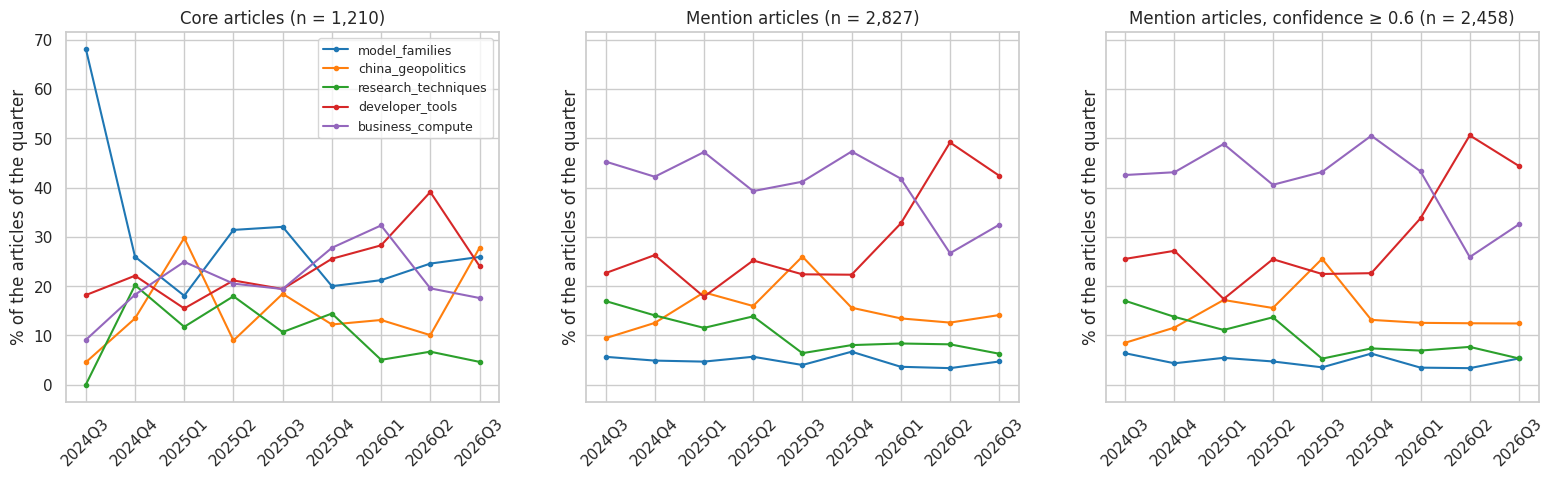

predicted theme                       model_families  china_geopolitics  research_techniques  developer_tools  business_compute
tier    period                                                                                                                 
core    year 1 (Sep 2024 – Jun 2025)            24.4               21.1                 14.3             18.1              22.2
        year 2 (Jul 2025 – Aug 2026)            24.9               15.7                  7.9             28.8              22.6
mention year 1 (Sep 2024 – Jun 2025)             5.1               16.0                 13.1             22.5              43.3
        year 2 (Jul 2025 – Aug 2026)             4.2               15.8                  7.6             36.1              36.2

In [ ]:
preds = preds_track.merge(corpus[["doc_id", "om_regions", "om_families"]], on="doc_id", how="left")
print("Predicted articles by tier:", preds["om_tier"].value_counts().to_dict())
print(f"Confidence >= 0.6: {(preds['confidence'] >= 0.6).mean():.1%} of all, "
      f"{(preds.loc[preds['om_tier'] == 'mention', 'confidence'] >= 0.6).mean():.1%} of mention articles")

def theme_shares(df):
    return pd.crosstab(df["quarter"], df["pred"], normalize="index").reindex(columns=LABELS, fill_value=0) * 100

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), sharey=True)
for ax, (title, df) in zip(axes, [("Core articles", preds[preds["om_tier"] == "core"]),
                                  ("Mention articles", preds[preds["om_tier"] == "mention"]),
                                  ("Mention articles, confidence ≥ 0.6", preds[(preds["om_tier"] == "mention") & (preds["confidence"] >= 0.6)])]):
    s = theme_shares(df)
    for theme in LABELS:
        ax.plot(s.index, s[theme], marker="o", ms=3, label=theme, color=palette[theme])
    ax.set(title=f"{title} (n = {len(df):,})", xlabel="", ylabel="% of the articles of the quarter")
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=9)
save_fig(fig, "track_themes_over_time")

year = lambda q: np.where(q < "2025Q3", "year 1 (Sep 2024 – Jun 2025)", "year 2 (Jul 2025 – Aug 2026)")
change = (pd.crosstab([preds["om_tier"], year(preds["quarter"])], preds["pred"], normalize="index")
          .reindex(columns=LABELS) * 100).rename_axis(index=["tier", "period"], columns="predicted theme")
change = change.loc[["core", "mention"]]
change.to_csv(OUT_DIR / "track_themes_by_year.csv")
display(change.round(1))

In [ ]:
# Hand check by the author: 20 random mention articles with their predicted theme
check = (preds[preds["om_tier"] == "mention"].sample(20, random_state=1)
         .merge(corpus[["doc_id", "title", "text"]], on="doc_id"))
check["start"] = check["text"].str[:300]
display(check[["title", "start", "pred", "confidence"]])

,title,start,pred,confidence
0,Multimodal Retrieval-Augmented Generation (RAG) with Document Retrieval (ColPali) and Vision Language Models (VLMs) ...,🚨 WARNING: This notebook is resource-intensive and requires substantial computational power. If you’re running this ...,developer_tools,0.996177
1,How Retrieval Augmented Generation (RAG) Makes LLM Smarter,"Large language models (LLMs) are like ultimate know-it-alls, ready to chat about any topic you throw their way—wheth...",developer_tools,0.920358
2,Experts: You have some power to reduce your AI environmental footprint,"Amazon Web Services data center is visible on Aug. 22, 2024, in Boardman, Ore. (AP Photo/Jenny Kane, File)\n\nWASHIN...",china_geopolitics,0.677947
3,"A data bottleneck is holding AI science back, says new Nobel winner",AI’s usefulness for scientific discovery will be stunted without high-quality data.\n\nDavid Baker is sleep-deprived...,china_geopolitics,0.740085
4,What we announced at Google for Brazil 2025,Google is celebrating 20 years in Brazil with new AI tools and initiatives. Expect real-time translation in Google M...,business_compute,0.925293
5,I met the ‘ godfathers of AI’ in Paris – here’s what they told me to really worry about,Experts are split between concerns about future threats and present dangers. Both camps issued dire warnings\n\nI wa...,china_geopolitics,0.984685
6,Tools and Talks Worth Checking Out at KubeCon Europe,"Are you heading to KubeCon + CloudNativeCon Europe 2025? With the event fast approaching, now’s the perfect time to ...",developer_tools,0.968983
7,Data Points: OpenAI looks inside neural networks,An interpretability team at OpenAI developed a new training method that forces language models to use far fewer conn...,model_families,0.577142
8,"Codex’s Robot Dev Team, Grok's Fixation on South Africa, Saudi Arabia’s AI Power Play, and more...","In the age of AI, large corporations — not just startups — can move fast. I often speak with large companies’ C-suit...",business_compute,0.960425
9,Connected Intelligence: Operationalizing Production-Grade Graph Solutions Across Enterprise Networks,"The race for enterprise AI dominance has officially shifted from basic model experimentation to massive, production-...",developer_tools,0.812492


In [ ]:
# Robustness checks suggested by the hand check
mention = preds[preds["om_tier"] == "mention"]
for t in (0.6, 0.8):
    s = mention[mention["confidence"] >= t]
    print(f"Mention articles with confidence >= {t}: {len(s):,} ({len(s) / len(mention):.0%})")
    display((pd.crosstab(year(s["quarter"]), s["pred"], normalize="index").reindex(columns=LABELS) * 100).round(1))

# Theme profile by region on the core articles only (where the classifier was evaluated in Part 2)
core_one = preds[(preds["om_tier"] == "core") & (preds["om_regions"].map(len) == 1)]
core_one = core_one.assign(region=core_one["om_regions"].map(lambda r: r[0]))
print("Core articles only, theme profile by region (%):")
display((pd.crosstab(core_one["region"], core_one["pred"], normalize="index").reindex(columns=LABELS) * 100)
        .round(0).loc[["US", "China", "Europe"]])

Mention articles with confidence >= 0.6: 2,458 (87%)


pred,model_families,china_geopolitics,research_techniques,developer_tools,business_compute
row_0,,,,,
year 1 (Sep 2024 – Jun 2025),5.0,15.0,12.8,22.7,44.4
year 2 (Jul 2025 – Aug 2026),4.1,15.0,6.7,37.1,37.0


Mention articles with confidence >= 0.8: 2,001 (71%)


pred,model_families,china_geopolitics,research_techniques,developer_tools,business_compute
row_0,,,,,
year 1 (Sep 2024 – Jun 2025),4.5,13.9,13.0,23.0,45.7
year 2 (Jul 2025 – Aug 2026),4.0,13.4,6.3,39.4,36.9


Core articles only, theme profile by region (%):


pred,model_families,china_geopolitics,research_techniques,developer_tools,business_compute
region,,,,,
US,32.0,5.0,11.0,32.0,20.0
China,19.0,36.0,10.0,10.0,26.0
Europe,19.0,6.0,6.0,34.0,34.0


**Hand check of the predictions on mention articles.** The classifier was evaluated on core articles only (Part 2), so its predictions on mention articles had not been checked. A random sample of 20 mention articles (fixed seed) was labelled with the annotation rubric of Part 2, from the title and the beginning of the text. The labels were proposed by Claude and reviewed by the author.

| # | predicted | verdict | better theme |
|---|---|---|---|
| 0 | developer_tools | correct | |
| 1 | developer_tools | correct | |
| 2 | china_geopolitics | wrong | business_compute or none (energy use of data centres) |
| 3 | china_geopolitics | wrong | research_techniques (AI in science) |
| 4 | business_compute | debatable | none |
| 5 | china_geopolitics | debatable | research_techniques (AI risk) |
| 6 | developer_tools | correct | |
| 7 | model_families | debatable | research_techniques (newsletter, mixed items) |
| 8 | business_compute | correct | |
| 9 | developer_tools | correct | |
| 10 | business_compute | correct | |
| 11 | business_compute | correct | |
| 12 | model_families | debatable | developer_tools (prompting guide) |
| 13 | developer_tools | correct | |
| 14 | business_compute | correct | |
| 15 | business_compute | none fits | none (architecture) |
| 16 | china_geopolitics | wrong | research_techniques (safety study) |
| 17 | business_compute | correct | |
| 18 | developer_tools | correct | |
| 19 | china_geopolitics | wrong | research_techniques (LeCun, world models) |

**Result: 11 correct, 4 debatable, 4 wrong, 1 outside the five themes.**
- **`china_geopolitics` works as a catch-all**: all 4 wrong predictions are `china_geopolitics`, and none of the 5 `china_geopolitics` predictions in the sample is clearly correct. General news about AI and society is put into the policy theme, so its share among the mention articles (about 16%) is likely overestimated.
- **`developer_tools` is reliable**: all 6 predictions are correct, which supports the main trend of this section.
- **The classifier cannot predict *none***: an article outside the five themes (#15) still receives one.
- **Confidence**: the threshold of 0.6 removes only 1 of the 5 errors, while all correct predictions have a confidence of at least 0.81 and 4 of the 5 errors are below 0.8. With a threshold of 0.8 (cell above), 71% of the mention articles are kept and the trends are the same: `developer_tools` grows from 23% to 39%, `research_techniques` falls from 13% to 6%.
- **Regions**: on the core articles alone, where the classifier was evaluated, Chinese models are discussed through geopolitics even more clearly (36% vs 5% for US models, cell above), so the regional finding of Section 3.6.3 does not depend on the mention articles.
- With 20 articles, one article is 5 percentage points: the check shows the type of errors, not a precise error rate.

**Interpretation**:
- **`developer_tools` is the growing theme**: from 18% to 29% of the core articles and from 23% to 36% of the mention articles between the two years, with a peak in 2026Q2 (39% and 49%). Open models are more and more discussed as components of agents, coding assistants and platforms.
- **`research_techniques` shrinks** (core 14% → 8%, mention 13% → 8%), and **`china_geopolitics`** peaks in the core articles in 2025Q1, the quarter of DeepSeek-R1 (30%), then falls (21% → 16% between the years).
- **`model_families`** stays stable among the core articles (about 25%) and is small among the mention articles (4 – 5%), as expected: these articles name a model without being about it. `business_compute` is the largest theme of the mention articles, but loses ground to `developer_tools` (43% → 36%).
- **The trends hold with stricter filters**: 87% of the mention articles have a confidence of at least 0.6 and 71% of at least 0.8, and all subsets show the same changes (right panel and hand check above). The hand check shows, however, that `china_geopolitics` is overestimated among the mention articles, while `developer_tools` is reliable. The first and the last quarters are incomplete (2024Q3 starts on 11 September with few core articles, hence the 68% for `model_families`).

### 3.6.3 Themes by developer region and model family
Every open-models article lists the model families it mentions and the home region of their developers (Stage 1 lexicon). An article that mentions families of one region only is assigned to that region; the theme profile of each region and of the most mentioned families shows **how** each group of open models is discussed.

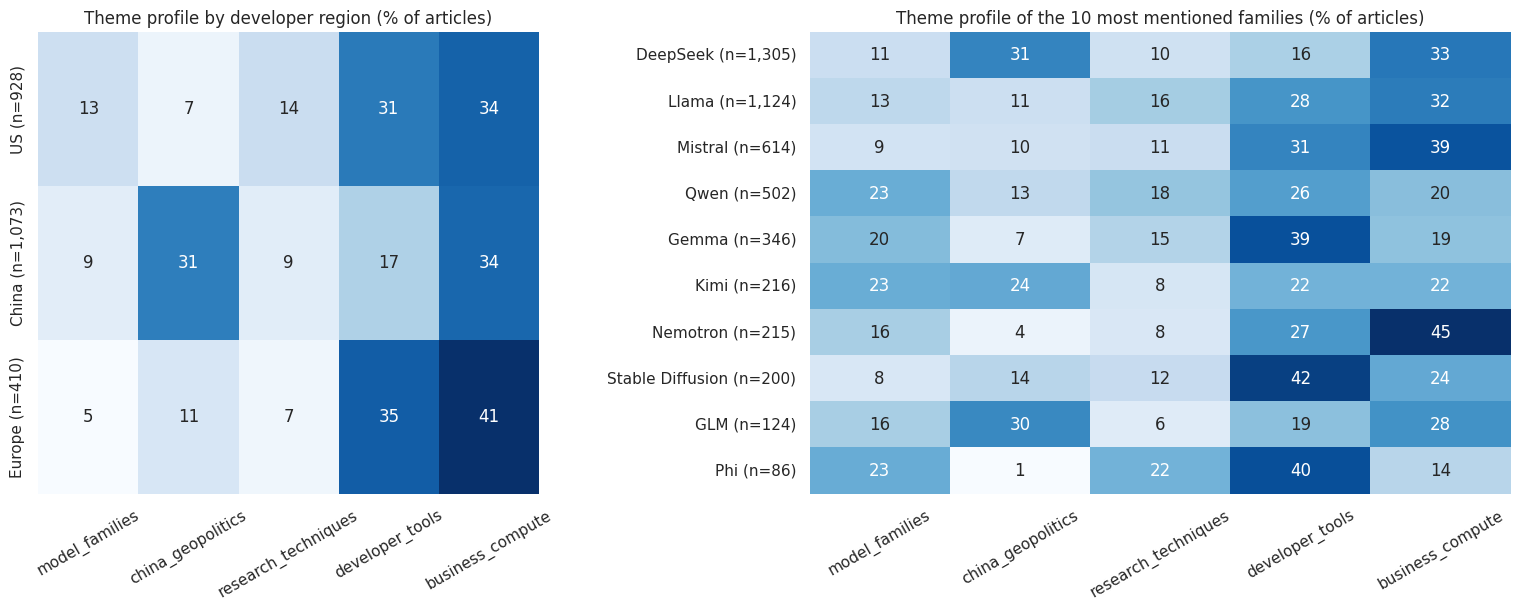

In [ ]:
one_region = (preds[preds["om_regions"].map(len) == 1].assign(region=lambda d: d["om_regions"].map(lambda r: r[0]))
              .reset_index(drop=True))
by_region = pd.crosstab(one_region["region"], one_region["pred"], normalize="index").reindex(columns=LABELS) * 100
by_region["articles"] = one_region["region"].value_counts()
by_region = by_region.loc[["US", "China", "Europe"]]

fam = preds.explode("om_families").dropna(subset=["om_families"]).reset_index(drop=True)
top_fam = fam["om_families"].value_counts().head(10).index
by_family = pd.crosstab(fam.loc[fam["om_families"].isin(top_fam), "om_families"],
                        fam.loc[fam["om_families"].isin(top_fam), "pred"], normalize="index").reindex(columns=LABELS) * 100
by_family["articles"] = fam["om_families"].value_counts()
by_family = by_family.loc[top_fam]
by_family.index = pd.Index([lexicon["families"][f]["label"].split(" / ")[0] for f in by_family.index], name="family")
by_region.to_csv(OUT_DIR / "track_themes_by_region.csv"); by_family.to_csv(OUT_DIR / "track_themes_by_family.csv")

fig, axes = plt.subplots(1, 2, figsize=(19, 6), gridspec_kw={"width_ratios": [1, 1.4], "wspace": 0.45})
sns.heatmap(by_region[LABELS], annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[0],
            yticklabels=[f"{r} (n={n:,})" for r, n in by_region["articles"].items()])
axes[0].set(title="Theme profile by developer region (% of articles)", xlabel="", ylabel="")
sns.heatmap(by_family[LABELS], annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[1],
            yticklabels=[f"{f} (n={n:,})" for f, n in by_family["articles"].items()])
axes[1].set(title="Theme profile of the 10 most mentioned families (% of articles)", xlabel="", ylabel="")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
save_fig(fig, "track_themes_region_family")

**Interpretation**:
- **Chinese models are discussed through geopolitics**: 31% of the articles that mention only Chinese families are about China–US rivalry and policy, against 7% for US and 11% for European models. US and European models are discussed mainly through **developer tools and business** (66% and 77% together).
- **DeepSeek is the extreme case** (31% `china_geopolitics`, 33% `business_compute`: the "DeepSeek shock" on costs, chips and markets), while **Qwen** is discussed like a US model, as a model and a tool (23% `model_families`, 26% `developer_tools`, only 13% `china_geopolitics`). Kimi and GLM are in between (24% and 30% `china_geopolitics`).
- **Each US family has its own profile**: Gemma and Phi are discussed as developer tools (39 – 40%), Phi also as research (22%, small models); Nemotron through business and compute (45%, NVIDIA hardware); Llama has the most balanced profile, as the reference open model.
- These profiles complete Stage 1, which found that attention moved from Llama to Chinese families: the Chinese families did not only gain attention, they brought a geopolitical framing into the track.

### 3.6.4 Fine-tuned themes and Stage 1 topics
Stage 1 described the core articles with 16 NMF topics; Part 2 mapped them to the five themes (topic labels). On the core articles, the share of agreement between the Stage 1 topic theme and the predicted theme shows how much the fine-tuned model changes the picture of the track, and on the validation articles, which of the two agrees with the reviewed labels.

In [ ]:
TOPIC_TO_THEME = {t: theme for theme, ts in {"model_families": ["T08", "T09", "T11", "T13", "T15"],
                                              "china_geopolitics": ["T02", "T07"],
                                              "research_techniques": ["T01", "T05", "T06"],
                                              "developer_tools": ["T04", "T10"],
                                              "business_compute": ["T03", "T12", "T14"]}.items() for t in ts}
cmp_ = preds[preds["om_tier"] == "core"].merge(core, on="doc_id")
cmp_["topic_theme"] = cmp_["dominant_topic_label"].str[:3].map(TOPIC_TO_THEME)
cmp_ = cmp_.dropna(subset=["topic_theme"]).merge(labels[["doc_id", "checked_theme", "split"]], on="doc_id", how="left")
v = cmp_[(cmp_["split_y"] == "validation") & (cmp_["checked_theme"] != "none") & cmp_["checked_theme"].notna()]
agree = pd.Series({
    "core articles: topic theme = predicted theme": (cmp_["topic_theme"] == cmp_["pred"]).mean(),
    "validation: topic theme = reviewed label": (v["topic_theme"] == v["checked_theme"]).mean(),
    "validation: predicted theme = reviewed label": (v["pred"] == v["checked_theme"]).mean()})
display(agree.round(3).to_frame("agreement"))

year_topic = pd.crosstab(year(cmp_["quarter"]), cmp_["topic_theme"], normalize="index").reindex(columns=LABELS) * 100
year_pred = pd.crosstab(year(cmp_["quarter"]), cmp_["pred"], normalize="index").reindex(columns=LABELS) * 100
display(pd.concat({"Stage 1 topic themes": year_topic, "fine-tuned themes": year_pred})
        .rename_axis(index=["themes", "period"], columns="theme").round(1))

,agreement
core articles: topic theme = predicted theme,0.598
validation: topic theme = reviewed label,0.592
validation: predicted theme = reviewed label,0.850


theme                                              model_families  china_geopolitics  research_techniques  developer_tools  business_compute
themes               period                                                                                                                 
Stage 1 topic themes year 1 (Sep 2024 – Jun 2025)            19.0               22.9                 21.3             12.2              24.7
                     year 2 (Jul 2025 – Aug 2026)            24.2               11.2                 13.4             32.7              18.6
fine-tuned themes    year 1 (Sep 2024 – Jun 2025)            25.9               20.0                 13.1             17.9              23.1
                     year 2 (Jul 2025 – Aug 2026)            26.3               15.0                  7.6             27.7              23.4

**Interpretation**:
- **The fine-tuned model agrees with the Stage 1 topics for only 60% of the core articles**, and on the validation articles it agrees much better with the reviewed labels (0.85) than the topic themes do (0.59, consistent with the 64% of the hand check in Part 2). The fine-tuned themes are therefore the more reliable picture of the track.
- **The direction of the trends is the same**: both show `developer_tools` growing and `china_geopolitics` and `research_techniques` shrinking between the two years. The Stage 1 topics **exaggerate the changes** (`developer_tools` 12% → 33% vs 18% → 28%; `china_geopolitics` 23% → 11% vs 20% → 15%): a topic model follows the dominant vocabulary of each period, while the classifier assigns the main subject of each article.
- The main Stage 1 findings on the themes of the track hold, with smaller effect sizes.

### 3.6.5 Which representation captures the open-models track best?
The table brings together, for every representation, its score on the four questions of this part: semantic similarity of articles, separation of the open-models articles, theme classification, and cost.

In [ ]:
synthesis = pd.DataFrame({
    "kNN accuracy (themes)": intrinsic_docs["kNN accuracy"],
    "NMI (themes)": intrinsic_docs["NMI"],
    "10-NN purity (track)": track_sep["10-NN purity (all)"],
    "macro-F1": extrinsic.set_index("representation")["macro_f1"],
    "macro-F1 hand-checked": extrinsic.set_index("representation")["macro_f1_hand"],
    "training (min)": tradeoffs.set_index("representation")["train_min"],
    "GPU needed": tradeoffs.set_index("representation")["peak_gpu_gb"].gt(0).map({True: "yes", False: "no"}),
}).loc[list(REP)]
synthesis.to_csv(OUT_DIR / "synthesis.csv")
display(synthesis.round(3))

,kNN accuracy (themes),NMI (themes),10-NN purity (track),macro-F1,macro-F1 hand-checked,training (min),GPU needed
representation,,,,,,,
TF-IDF,0.655,0.274,0.672,0.796,0.754,0.546,no
Word2Vec (mean),0.636,0.317,0.693,0.725,0.729,14.832,no
FastText (mean),0.626,0.318,0.694,0.727,0.743,29.083,no
Doc2Vec,0.646,0.338,0.716,0.749,0.740,7.656,no
Qwen3-1.7B frozen,0.646,0.287,0.673,0.738,0.713,0.000,yes
Qwen3-1.7B QLoRA,0.762,0.495,0.671,0.804,0.796,9.008,yes
Qwen3-4B frozen,0.660,0.309,0.681,0.752,0.754,0.000,yes
Qwen3-4B QLoRA,0.762,0.484,0.673,0.843,0.788,21.158,yes


**Interpretation**: no single representation is best for every purpose.
- **To analyse the themes of the open-models track: Qwen3-1.7B QLoRA.** The QLoRA vectors are the only ones with a clear theme structure (kNN 0.76, NMI 0.50), and the smaller model matches the larger one on the intrinsic tests and on the hand-checked labels at a lower cost. Qwen3-4B QLoRA gives the best macro-F1 on all labels and was used for the predictions of Section 3.6.
- **To place the track within the whole AI discourse: Doc2Vec.** It separates the open-models articles best without supervision (0.72) and has a vector for every article of the corpus, which made the discourse clusters of Section 3.6.1 possible.
- **Without a GPU: TF-IDF.** It is the best classical representation for theme classification (0.80) and the cheapest of all.
- **At word level: Word2Vec** for similarity and categories, **FastText** for unseen names and analogies.
- The frozen compact models are dominated: they need a GPU and score no better than the classical representations.

## 3.7 Summary: Model Trade-offs and Insights from the Open-Models Track
**Model trade-offs**
- **Fine-tuning pays off for theme structure, pre-training alone does not.** The QLoRA models give the best article vectors (kNN accuracy 0.76) and the best theme classification (0.84 and 0.80 macro-F1). The frozen compact models score like the classical representations trained on the corpus.
- **A strong discrete baseline nearly closes the gap.** TF-IDF reaches 0.80 macro-F1, not significantly below the best QLoRA model and level with the recommended Qwen3-1.7B QLoRA, without a GPU and with less than a minute of training. Dense classical representations (Word2Vec, FastText, Doc2Vec) are 5 – 7 points lower.
- **Model size matters less than fine-tuning.** Qwen3-4B is not better than Qwen3-1.7B on the hand-checked articles, at 2.3× the training time and 1.7× the GPU memory; Qwen3-1.7B QLoRA is the recommended compact model.
- **Classical models remain useful where they cover the whole corpus**: Doc2Vec separates the open-models articles best without supervision and is cheap enough to embed all 45,462 articles.

**Insights on the open-models track**
- **Where the track sits**: open models are concentrated in the technical LLM discourse, enterprise infrastructure, politics and regulation, and agents, and almost absent from consumer, culture, medicine and business-management coverage.
- **From research to tools**: the share of open-models articles about developer tools and agents grows by about 10 points between the two years (core 18% → 29%, mention 23% → 36%), while research and China–US rivalry lose weight. The same shift is visible in the whole corpus, where the agent cluster grows from 1% to 17 – 19% of all articles.
- **Two ways of talking about open models**: Chinese models are framed by geopolitics (31% of their articles, DeepSeek above all), US and European models by tools and business; Qwen is the exception among the Chinese families.
- **Stage 1 revisited**: the trends of the Stage 1 topics hold in direction but are exaggerated; the fine-tuned classifier agrees much better with the reviewed labels (0.85 vs 0.59).

**Limitations**
- **Small evaluation set**: 206 validation articles (98 checked by hand) give bootstrap intervals of about ±6 points; several differences between representations are not significant.
- **Labels**: the training labels and part of the validation labels were made with an LLM (Part 2, Section 2.2.3); the scores on the hand-checked articles are reported to control for this.
- **Unequal intrinsic comparison**: the QLoRA vectors were trained on the five themes, so their intrinsic theme scores are not unsupervised like those of the other representations.
- **Timing**: the classical models were timed on a 10% sample and scaled, on a 2-core CPU; the compact models on Colab GPUs (L4, T4 for the frozen Qwen3-1.7B). The times are comparable in order of magnitude only, and the pre-training cost of the compact models is not included.
- **Predictions on mention articles**: the classifier was trained on core articles and cannot predict *none*. A hand check of 20 mention articles (Section 3.6.2) found 11 correct, 4 debatable and 5 wrong predictions, mostly `china_geopolitics` given to general AI news; its share among the mention articles is likely overestimated. The predicted probabilities are not calibrated.
- **Regions**: only articles mentioning families of a single region are used; an article mentioning both DeepSeek and Llama is left out of the region profile.
- **Discourse clusters**: the silhouette is low (0.07) and the number of clusters was chosen at the upper end of the tested range, so the clusters describe regions of a continuous discourse, not natural groups; K-means on 45,462 articles can also differ slightly between machines, so the cluster sizes are indicative. They are based on Doc2Vec only, the one representation available for all articles.

# Appendix: Outputs
Every part saves its outputs on Google Drive, in `MyDrive/HSLU/CLT/extraction_outputs/stage2/` (one folder per part); they also serve as a cache when the notebook is run again. Models and tokenised text are too large for GitHub.
In Part 2, the outputs that depend on the training labels are in `wp2/checked/` (reviewed labels); `wp2/` holds the first run on the topic labels.

| part · folder | file | content |
|---|---|---|
| 1 · `wp1/` | `splits.parquet` | training / validation split of every article (seed 42), shared with the other Stage 2 work packages |
| 1 · `wp1/` | `sentences_train.txt`, `docs_all.txt`, `docs_train.txt`, `docs_index.parquet` | tokenised corpus |
| 1 · `wp1/` | `word2vec.model`, `fasttext.model` | word embeddings (`gensim`) |
| 1 · `wp1/` | `doc2vec.model`, `doc_vectors.parquet` | sentence / document embeddings and the vector of every article |
| 1 · `wp1/` | `terms_tsne.csv`, `figures/` | tables and visualisations |
| 2 · `wp2/checked/` | `task_labels.parquet` | articles of the task with Stage 1 topic, topic label, reviewed label, label source and set (train / dev / validation) |
| 2 · `wp2/checked/` | `results_validation.csv` | macro-F1 of every method on the shared validation split (reviewed labels with bootstrap interval, and topic labels) |
| 2 · `wp2/checked/` | `results_robustness.csv`, `results_paired.csv` | scores on the hand-checked labels and paired bootstrap differences (Section 2.6.3) |
| 2 · `wp2/checked/` | `predictions_validation.parquet` | predicted theme of every validation article, per method (Section 2.6.3) |
| 2 · `wp2/checked/` | `results_input_length.csv` | the same for every representation and input length (Section 2.6.4) |
| 2 · `wp2/` | `results_label_versions.csv` | first run on the topic labels vs reviewed labels (Section 2.6.5) |
| 2 · `wp2/checked/` | `resources.json` | per model: time and peak GPU memory of every step, parameters, trainable share, adapter size, settings |
| 2 · `wp2/checked/` | `train_log_<model>.csv` | training and dev metrics per step / epoch |
| 2 · `wp2/checked/` | `adapters/<model>/` | LoRA adapters and classification head |
| 2 · `wp2/checked/` | `llm_doc_vectors_<model>_{base,ft}.parquet` | article vectors, same format and same articles as the t-SNE map of Part 1 |
| 2 · `wp2/checked/` | `unseen_names.csv` | test of unseen model names (Section 2.8.1) |
| 2 · `wp2/checked/` | `predictions_track_<model>.parquet` | theme probabilities of all open-models articles (best fine-tuned model) |
| 2 · `wp2/` | `label_check_validation.csv` | hand check of the topic labels (Section 2.2.2) |
| 2 · `wp2/checked/` | `figures/` | visualisations |
| 3 · `wp3/` | `intrinsic_words_general.csv`, `intrinsic_words_developers.csv`, `intrinsic_words_categories.csv` | word-level intrinsic scores (Section 3.2) |
| 3 · `wp3/` | `intrinsic_articles_themes.csv`, `intrinsic_articles_track.csv` | article-level intrinsic scores (Section 3.3) |
| 3 · `wp3/` | `extrinsic_theme_classification.csv`, `extrinsic_paired.csv` | theme classification of all representations, paired bootstrap (Section 3.4) |
| 3 · `wp3/` | `tradeoffs.csv`, `timing_classical.json` | size, time, GPU memory and scores of every representation (Section 3.5) |
| 3 · `wp3/` | `discourse_clusters.csv` | Doc2Vec discourse clusters of the whole corpus (Section 3.6.1) |
| 3 · `wp3/` | `track_themes_by_year.csv`, `track_themes_by_region.csv`, `track_themes_by_family.csv` | themes of the open-models track (Sections 3.6.2 – 3.6.3) |
| 3 · `wp3/` | `synthesis.csv` | overview of all representations (Section 3.6.5) |
| 3 · `wp3/` | `tokens_sample.parquet` | tokens of the 8,037 compared articles (cache) |
| 3 · `wp3/` | `figures/` | visualisations |

The small tables and figures of Part 3 are also copied to `artifacts/stage2_wp3/` in the repository:

In [ ]:
import shutil
ART = REPO / "artifacts/stage2_wp3"
(ART / "figures").mkdir(parents=True, exist_ok=True)
for f in OUT_DIR.iterdir():
    if f.suffix in {".csv", ".json"}:
        shutil.copy(f, ART / f.name)
for f in FIG.glob("*.png"):
    shutil.copy(f, ART / "figures" / f.name)
for f in sorted(ART.rglob("*")):
    if f.is_file():
        print(f"{f.relative_to(REPO)}  ({f.stat().st_size / 1e3:.0f} kB)")

artifacts/stage2_wp3/README.md  (2 kB)
artifacts/stage2_wp3/discourse_clusters.csv  (2 kB)
artifacts/stage2_wp3/extrinsic_paired.csv  (0 kB)
artifacts/stage2_wp3/extrinsic_theme_classification.csv  (1 kB)
artifacts/stage2_wp3/figures/discourse_clusters.png  (269 kB)
artifacts/stage2_wp3/figures/extrinsic_theme_classification.png  (92 kB)
artifacts/stage2_wp3/figures/intrinsic_articles.png  (104 kB)
artifacts/stage2_wp3/figures/track_themes_over_time.png  (223 kB)
artifacts/stage2_wp3/figures/track_themes_region_family.png  (169 kB)
artifacts/stage2_wp3/figures/tradeoffs.png  (104 kB)
artifacts/stage2_wp3/figures/tsne_validation_themes.png  (233 kB)
artifacts/stage2_wp3/figures/words_category_purity.png  (84 kB)
artifacts/stage2_wp3/intrinsic_articles_themes.csv  (1 kB)
artifacts/stage2_wp3/intrinsic_articles_track.csv  (1 kB)
artifacts/stage2_wp3/intrinsic_words_categories.csv  (0 kB)
artifacts/stage2_wp3/intrinsic_words_developers.csv  (0 kB)
artifacts/stage2_wp3/intrinsic_words_gener

# AI Disclosure
Claude Code and Claude (Claude Opus 5.5) were used in all three parts. The use is reported per part, by its author.

**Part 1 (Jennifer Spieser).** Claude Code was used as a coding assistant. It supported:
- code improvement and optimisation;
- review pipeline design choices;
- reduction of processing time through code optimisation;
- preparation of the saved outputs.

All methodological choices, pipeline design, analysis, evaluation and interpretation of the results were conducted by the author. Claude Code was used solely as a coding and technical support tool.

**Part 2 (Jihyeon Choung).** Claude Code was used in two roles:
1. **Coding and writing assistant.** It supported debugging the notebook code, reducing the processing time, the statistical checks.
2. **Annotator of the reviewed labels (Section 2.2.3).** It assigned theme labels to 1,060 articles using a predefined rubric, without access to the topic labels. These labels were used for training. Validation labels were manually checked (100 independently, 68 with LLM labels visible; κ = 0.70). Potential LLM-related evaluation bias is discussed in Section 2.6.3.

The task design, the choice of the methods, the hand check of the labels and the final decisions were made by the author, who reviewed all code, results and text.

**Part 3 (Daliasny Gonzalez Guzman).** Claude was used as a coding and writing assistant. It supported:
- writing and debugging the evaluation code, and re-using the functions and settings of Parts 1 and 2;
- choosing and implementing the evaluation measures (intrinsic benchmarks, kNN and clustering scores, paired bootstrap);
- drafting the interpretation text from the computed results;
- proposing the labels of the hand check of Section 3.6.2, which the author reviewed.

The author ran the notebook in Colab and reviewed the hand-check labels. The scope of the comparison, the review of the code, figures and results, and the final interpretations are the responsibility of the author.